# 12 — Riset KS OOF 0,54: EDA, model, audit dan submission

Target: **KS gabungan seluruh OOF ≥ 0,54**, memakai lima fold stratified seed
31027. Baseline Kumo–spline memiliki pooled KS **0,52851** dan rata-rata KS fold
**0,53095**. Pengguna melaporkan public **0,56393** untuk CSV baseline pada
18 Oktober 2026. Skor public setiap kandidat yang berubah masih belum diketahui.

Bagian awal membangun fitur dan baseline dari data mentah. Bagian riset memuat
kode TabPFN 3.5, EBM, koreksi Kumo/kalender, Kumo Relational, audit, dan ekspor. Mode review
default membaca hasil eksperimen yang selesai. Ubah flag training untuk mengulang
model baru pada clone tanpa cache. Eksperimen yang belum lengkap tidak mempunyai
skor pooled. Notebook hanya mengekspor kandidat goal jika target telah tercapai.

Pemilihan berulang memakai training labels dan split yang pernah digunakan.
Angka OOF tetap mengandung optimisme seleksi; ini bukan untouched holdout.
Gunakan Python 3.11, requirements-goal054.txt dan GPU CUDA untuk training.


## Persiapan

Fitur dibangun dari data mentah jika cache belum tersedia.

In [1]:
RUN_NAME = "12_goal054"
CANONICAL_FILE = "submission_kumo_v2.csv"
PUBLIC_SCORE = None

from pathlib import Path
import gc, hashlib, itertools, json, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

# Ubah empat pilihan ini jika ingin membangun dan melatih semuanya ulang.
FORCE_REBUILD_FEATURES = False
FORCE_RETRAIN_MODELS = False
FORCE_RECOMPUTE_VALIDATION = False
RUN_OPTIONAL_SEARCH = False

ROOT = Path(os.environ.get("LOGIKA_PROJECT_DIR", Path.cwd())).resolve()
if not (ROOT / "scripts/analyze.py").exists():
    ROOT = next(p for p in ROOT.parents if (p / "scripts/analyze.py").exists())
RAW = ROOT / "data/raw"
PROCESSED = Path(os.environ.get("LOGIKA_FEATURE_DIR", ROOT / "data/processed"))
OUT = ROOT / "artifacts/notebook_runs" / RUN_NAME
TABLES = OUT / "tables"
for folder in [PROCESSED, OUT, TABLES, OUT / "models"]:
    folder.mkdir(parents=True, exist_ok=True)
KEY, TARGET = "customer_id", "target"
EXCLUDED = {
    "application_id",
    "customer_id",
    "application_datetime",
    "decision_datetime",
    "target",
    "split",
}
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)
print("Proyek:", ROOT)
print("Output notebook:", OUT / "submission.csv")
import argparse, importlib.metadata
import torch, sdm
assert torch.cuda.is_available()
print('Torch:', torch.__version__, '; SDM:', sdm.__version__)
import re
from scipy import optimize, special, stats

import joblib


Proyek: /home/taqiyudinmiftah/Logika
Output notebook: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/12_goal054/submission.csv


/tmp/logika-kumo-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Torch: 2.8.0+cu128 ; SDM: 0.2.1


## 2. Memahami target dan data

`target=1` berarti pinjaman mencapai DPD ≥90 dalam 12 bulan setelah origination. Test tidak memiliki target. Ada satu aplikasi terpilih per customer, sehingga agregasi seluruh tabel riwayat memakai customer_id. Perbedaan rasio target menurut kelompok bersifat deskriptif dan bukan kesimpulan sebab-akibat.

,dataset,baris,kolom,target_positif,rasio_positif
0,train,70000,10,9507.0,0.135814
1,test,30000,9,NaN,NaN


,tipe,missing
application_id,object,0
customer_id,object,0
application_datetime,datetime64[ns],0
decision_datetime,datetime64[ns],0
loan_amount,int64,0
term_months,int64,0
annual_interest_rate,float64,0
proposed_monthly_installment,int64,0
loan_purpose,object,0
target,int64,0


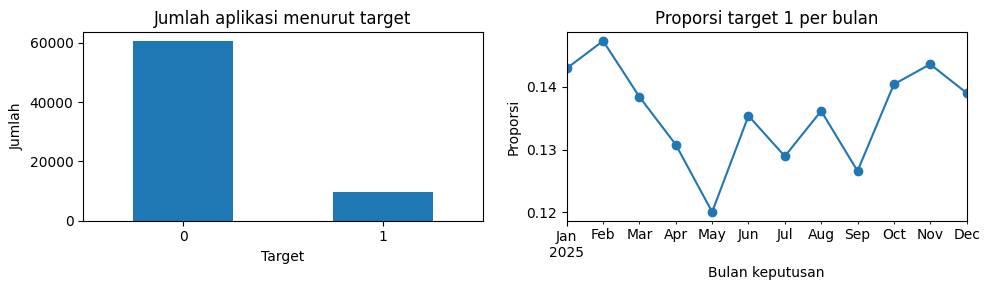

,aplikasi,rasio_target_1
employment_type,,
salaried,33473,0.132405
self_employed,20987,0.137943
variable_income,15540,0.140283


Urutan sample sama dengan test: False


In [2]:
train_raw = pd.read_csv(
    RAW / "train_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
test_raw = pd.read_csv(
    RAW / "test_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
sample = pd.read_csv(RAW / "sample_submission.csv")
profiles_eda = pd.read_csv(RAW / "customer_profiles.csv")
assert train_raw.application_id.is_unique and test_raw.application_id.is_unique
assert set(train_raw.customer_id).isdisjoint(test_raw.customer_id)
assert set(test_raw.application_id) == set(sample.application_id)
assert train_raw.target.isin([0, 1]).all()
display(
    pd.DataFrame(
        [
            {
                "dataset": "train",
                "baris": len(train_raw),
                "kolom": len(train_raw.columns),
                "target_positif": int(train_raw.target.sum()),
                "rasio_positif": train_raw.target.mean(),
            },
            {
                "dataset": "test",
                "baris": len(test_raw),
                "kolom": len(test_raw.columns),
                "target_positif": np.nan,
                "rasio_positif": np.nan,
            },
        ]
    )
)
display(
    pd.DataFrame({"tipe": train_raw.dtypes.astype(str), "missing": train_raw.isna().sum()})
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
train_raw.target.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Jumlah aplikasi menurut target", xlabel="Target", ylabel="Jumlah")
monthly = train_raw.groupby(train_raw.decision_datetime.dt.to_period("M")).target.agg(
    ["mean", "size"]
)
monthly["mean"].plot(marker="o", ax=axes[1])
axes[1].set(title="Proporsi target 1 per bulan", xlabel="Bulan keputusan", ylabel="Proporsi")
plt.tight_layout()
plt.show()
profile = train_raw[["customer_id", "target"]].merge(
    profiles_eda, on="customer_id", validate="one_to_one"
)
display(profile.groupby("employment_type").target.agg(aplikasi="size", rasio_target_1="mean"))
print("Urutan sample sama dengan test:", sample.application_id.equals(test_raw.application_id))
del profile, profiles_eda

## 3. Metrik KS dan risiko kebocoran

KS adalah maksimum selisih dua distribusi kumulatif skor. Dalam ROC, nilainya sama dengan maksimum |TPR−FPR|. KS mengukur pemisahan; submission tetap berupa probabilitas kontinu. Model validasi tidak boleh dilatih pada baris validasi. Informasi riwayat harus tersedia sebelum decision_datetime, dan opaque ID tidak menjadi fitur.

In [3]:
def ks(y, probability):
    fpr, tpr, _ = roc_curve(y, probability, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))


def lgb_ks(y, probability):
    return "ks", ks(y, probability), True


def metrics(y, probability):
    return {
        "ks": ks(y, probability),
        "roc_auc": roc_auc_score(y, probability),
        "average_precision": average_precision_score(y, probability),
        "log_loss": log_loss(y, probability),
    }

## 4. Fitur dasar: alat bantu dan pengaturan cache

Sel fitur berikut berisi kode agregasi yang digunakan pada eksperimen asli. Jika parquet tersedia, blok `if NEED_...` dilewati. Aktifkan `FORCE_REBUILD_FEATURES` untuk membaca ulang seluruh riwayat. Kode tetap terlihat dan dapat diedit langsung di notebook.

In [4]:
def safe_ratio(a, b):
    return a / b.where(b > 0)


def read(name, dates=()):
    return pd.read_csv(RAW / f"{name}.csv", parse_dates=list(dates))


def ratio(a, b):
    return a / b.where(b > 0)


NEED_BASE = FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features.parquet").exists()
NEED_BASE = NEED_BASE or not (PROCESSED / "bureau_latest.parquet").exists()
print("Bangun fitur dasar:", NEED_BASE)

Bangun fitur dasar: False


### Persiapan audit

Setiap aplikasi memiliki satu customer. Audit mencatat duplikasi, relasi tabel, missing value, dan ketersediaan riwayat.

In [5]:
if NEED_BASE:
    for folder in [PROCESSED, TABLES, OUT / "figures"]:
        folder.mkdir(parents=True, exist_ok=True)
    train = read("train_applications", ["application_datetime", "decision_datetime"])
    test = read("test_applications", ["application_datetime", "decision_datetime"])
    train["split"] = "train"
    test["split"] = "test"
    base = pd.concat([train, test], ignore_index=True)
    assert base.application_id.is_unique and base.customer_id.is_unique
    cutoff = base[[KEY, "decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    inventory, missing, audits, coverage = [], [], {}, []

    def inspect(df, name, primary):
        inventory.append(
            {
                "table": name,
                "rows": len(df),
                "columns": len(df.columns),
                "customers": df[KEY].nunique() if KEY in df else np.nan,
                "size_mb": (RAW / f"{name}.csv").stat().st_size / 1e6,
            }
        )
        for col in df:
            missing.append(
                {
                    "table": name,
                    "column": col,
                    "dtype": str(df[col].dtype),
                    "missing": int(df[col].isna().sum()),
                    "missing_pct": 100 * df[col].isna().mean(),
                    "unique_values": df[col].nunique(),
                }
            )
        audits[name] = {
            "duplicate_rows": int(df.duplicated().sum()),
            "duplicate_primary_keys": int(df.duplicated(primary).sum()),
        }
        if KEY in df:
            ids = set(df[KEY])
            audits[name]["orphan_customers"] = len(ids - set(base[KEY]))
            for part in ["train", "test"]:
                subset = base[base.split.eq(part)]
                coverage.append(
                    {
                        "table": name,
                        "split": part,
                        "covered_customers": int(subset[KEY].isin(ids).sum()),
                        "coverage_pct": 100 * subset[KEY].isin(ids).mean(),
                    }
                )
        print(f"Audited {name}: {len(df):,} rows", flush=True)

    def at_cutoff(df, name, cols):
        df = df.merge(cutoff, on=KEY, how="left", validate="many_to_one")
        assert df.cutoff.notna().all()
        for col in cols:
            audits[name][f"{col}_at_or_after_cutoff"] = int(df[col].ge(df.cutoff).sum())
        return df

    def attach(features):
        global base
        assert features.index.is_unique
        base = base.merge(
            features, left_on=KEY, right_index=True, how="left", validate="one_to_one"
        )
        assert len(base) == len(train) + len(test)

### Profil dan rasio kemampuan bayar

Gabungkan profil satu-ke-satu; rasio cicilan/pendapatan lebih mudah dipelajari model daripada dua jumlah rupiah terpisah.

In [6]:
if NEED_BASE:
    inspect(train.drop(columns="split"), "train_applications", "application_id")
    inspect(test.drop(columns="split"), "test_applications", "application_id")
    submission = read("sample_submission")
    inspect(submission, "sample_submission", "application_id")
    audits["submission"] = {
        "same_id_set_as_test": set(submission.application_id) == set(test.application_id),
        "same_row_order_as_test": submission.application_id.equals(test.application_id),
        "target_column": "default_probability",
    }
    profiles = read("customer_profiles")
    inspect(profiles, "customer_profiles", KEY)
    base = base.merge(profiles, on=KEY, how="left", validate="one_to_one")
    assert base.age.notna().all()
    base["installment_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.declared_monthly_income
    )
    base["loan_income_ratio"] = safe_ratio(base.loan_amount, base.declared_monthly_income)
    base["income_per_dependent"] = base.declared_monthly_income / (1 + base.dependents)
    base["decision_delay_hours"] = (
        base.decision_datetime - base.application_datetime
    ).dt.total_seconds() / 3600
    rate = base.annual_interest_rate / 12
    theoretical = (
        base.loan_amount
        * rate
        * (1 + rate) ** base.term_months
        / ((1 + rate) ** base.term_months - 1)
    )
    audits["applications"] = {
        "train_test_customer_overlap": len(set(train[KEY]) & set(test[KEY])),
        "train_test_application_overlap": len(
            set(train.application_id) & set(test.application_id)
        ),
        "decision_before_application": int(
            (base.decision_datetime < base.application_datetime).sum()
        ),
        "nonpositive_income": int(base.declared_monthly_income.le(0).sum()),
        "installment_formula_max_rounding_difference_idr": float(
            abs(base.proposed_monthly_installment - theoretical.round()).max()
        ),
        "term_months_values": sorted(base.term_months.unique().tolist()),
    }
    del profiles

### Riwayat aplikasi

Ambil keputusan sebelum cutoff. Hitung persetujuan, penolakan, dan jarak waktu aplikasi terakhir.

In [7]:
if NEED_BASE:
    name = "previous_applications"
    prev = read(name, ["application_datetime", "decision_datetime"])
    inspect(prev, name, "application_id")
    historical_ids = set(prev.application_id)
    approved_loans = set(prev.loan_id.dropna())
    loan_customers = prev.loc[prev.loan_id.notna(), ["loan_id", KEY]].set_index("loan_id")[KEY]
    audits[name]["overlap_with_selected_application_ids"] = len(
        historical_ids & set(base.application_id)
    )
    prev = at_cutoff(prev, name, ["application_datetime", "decision_datetime"])
    prev = prev[prev.decision_datetime.lt(prev.cutoff)].copy()
    for status in ["approved", "rejected", "cancelled"]:
        prev[f"is_{status}"] = prev.decision.eq(status).astype(int)
    prev["recency_days"] = (prev.cutoff - prev.decision_datetime).dt.total_seconds() / 86400
    features = prev.groupby(KEY).agg(
        previous_count=("application_id", "size"),
        previous_approved_count=("is_approved", "sum"),
        previous_rejection_rate=("is_rejected", "mean"),
        previous_cancel_rate=("is_cancelled", "mean"),
        previous_requested_mean=("requested_amount", "mean"),
        previous_approved_amount_mean=("approved_amount", "mean"),
        previous_installment_mean=("scheduled_monthly_installment", "mean"),
        previous_last_recency_days=("recency_days", "min"),
    )
    for days in [90, 180]:
        features[f"previous_count_{days}d"] = (
            prev[prev.recency_days.le(days)]
            .groupby(KEY)
            .size()
            .reindex(features.index, fill_value=0)
        )
    attach(features)
    base["has_previous"] = base.previous_count.notna().astype(int)
    del prev, features
    gc.collect()

### Riwayat pembayaran

DPD adalah days past due. Snapshot pembayaran harus diketahui sebelum keputusan, termasuk waktu pembayaran terakhir.

In [8]:
if NEED_BASE:
    name = "repayment_history"
    repay = read(name, ["due_date", "last_payment_datetime"])
    inspect(repay, name, "installment_id")
    audits[name]["loans_not_in_approved_history"] = len(set(repay.loan_id) - approved_loans)
    audits[name]["loan_customer_mismatches"] = int(
        repay.loan_id.map(loan_customers).ne(repay[KEY]).sum()
    )
    audits[name]["amount_paid_above_due"] = int(repay.amount_paid.gt(repay.amount_due).sum())
    audits[name]["max_dpd_below_current_dpd"] = int(
        repay.max_days_past_due.lt(repay.days_past_due).sum()
    )
    repay = at_cutoff(repay, name, ["due_date", "last_payment_datetime"])
    repay = repay[repay.due_date.lt(repay.cutoff)].copy()
    # Snapshot amounts/DPD are already measured before the selected decision.
    # Any future observed payment would invalidate this snapshot; do not silently use it.
    assert (
        repay.last_payment_datetime.dropna()
        .lt(repay.loc[repay.last_payment_datetime.notna(), "cutoff"])
        .all()
    )
    repay["unpaid_amount"] = (repay.amount_due - repay.amount_paid).clip(lower=0)
    for threshold in [1, 30, 90]:
        repay[f"ever_dpd_{threshold}"] = repay.max_days_past_due.ge(threshold).astype(int)
    repay["recency_days"] = (repay.cutoff - repay.due_date).dt.total_seconds() / 86400
    features = repay.groupby(KEY).agg(
        repayment_installment_count=("installment_id", "size"),
        repayment_loan_count=("loan_id", "nunique"),
        repayment_amount_due=("amount_due", "sum"),
        repayment_amount_paid=("amount_paid", "sum"),
        repayment_unpaid_amount=("unpaid_amount", "sum"),
        repayment_current_dpd_max=("days_past_due", "max"),
        repayment_historical_dpd_max=("max_days_past_due", "max"),
        repayment_historical_dpd_mean=("max_days_past_due", "mean"),
        repayment_late_share=("ever_dpd_1", "mean"),
        repayment_dpd30_share=("ever_dpd_30", "mean"),
        repayment_dpd90_share=("ever_dpd_90", "mean"),
    )
    features["repayment_paid_ratio"] = safe_ratio(
        features.repayment_amount_paid, features.repayment_amount_due
    )
    recent = (
        repay[repay.recency_days.le(180)]
        .groupby(KEY)
        .agg(
            repayment_dpd_mean_180d=("max_days_past_due", "mean"),
            repayment_unpaid_180d=("unpaid_amount", "sum"),
        )
    )
    attach(features.join(recent))
    base["has_repayments"] = base.repayment_installment_count.notna().astype(int)
    del repay, features, recent
    gc.collect()

### Perilaku rekening

Hanya bulan kalender yang sudah selesai yang digunakan; rangkum pemasukan, pengeluaran, saldo, dan hari saldo rendah.

In [9]:
if NEED_BASE:
    name = "account_behavior"
    account = read(name, ["month"])
    inspect(account, name, [KEY, "month"])
    account = at_cutoff(account, name, ["month"])
    completed = account.month + pd.offsets.MonthBegin(1)
    audits[name]["incomplete_month_at_cutoff"] = int(completed.gt(account.cutoff).sum())
    audits[name]["balance_identity_mismatches"] = int(
        (account.opening_balance + account.inflows - account.outflows)
        .ne(account.closing_balance)
        .sum()
    )
    audits[name]["negative_amount_cells"] = int(
        account.select_dtypes(include="number").lt(0).sum().sum()
    )
    account = account[completed.le(account.cutoff)].copy()
    account["net_inflow"] = account.inflows - account.outflows
    account["recency_days"] = (account.cutoff - account.month).dt.total_seconds() / 86400
    features = account.groupby(KEY).agg(
        account_month_count=("month", "size"),
        account_income_mean=("income_like_credits", "mean"),
        account_income_std=("income_like_credits", "std"),
        account_inflow_mean=("inflows", "mean"),
        account_outflow_mean=("outflows", "mean"),
        account_net_inflow_mean=("net_inflow", "mean"),
        account_average_balance_mean=("average_balance", "mean"),
        account_minimum_balance_min=("minimum_balance", "min"),
        account_low_balance_days_mean=("low_balance_days", "mean"),
        account_last_recency_days=("recency_days", "min"),
    )
    features["account_income_cv"] = safe_ratio(
        features.account_income_std, features.account_income_mean
    )
    last = account.sort_values("month").groupby(KEY).tail(1).set_index(KEY)
    for col in [
        "closing_balance",
        "income_like_credits",
        "average_balance",
        "low_balance_days",
    ]:
        features[f"account_last_{col}"] = last[col]
    # Three complete months immediately preceding the decision month.
    start = account.cutoff.dt.to_period("M").dt.to_timestamp() - pd.DateOffset(months=3)
    recent = (
        account[account.month.ge(start)]
        .groupby(KEY)
        .agg(
            account_income_mean_3m=("income_like_credits", "mean"),
            account_outflow_mean_3m=("outflows", "mean"),
            account_balance_mean_3m=("average_balance", "mean"),
            account_low_balance_days_mean_3m=("low_balance_days", "mean"),
        )
    )
    attach(features.join(recent))
    base["has_account"] = base.account_month_count.notna().astype(int)
    base["observed_declared_income_ratio"] = safe_ratio(
        base.account_income_mean, base.declared_monthly_income
    )
    base["installment_observed_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.account_income_mean
    )
    base["balance_installment_ratio"] = safe_ratio(
        base.account_last_closing_balance, base.proposed_monthly_installment
    )
    del account, features, last, recent
    gc.collect()

### Biro kredit

Laporan harus sudah dibuat dan tersedia sebelum cutoff. Gunakan laporan terakhir per provider; saldo provider tidak dijumlahkan karena cakupan dapat tumpang tindih.

In [10]:
if NEED_BASE:
    name = "bureau_observations"
    bureau = read(name, ["report_datetime", "available_datetime"])
    inspect(bureau, name, "bureau_observation_id")
    audits[name]["unknown_application_ids"] = len(
        set(bureau.application_id) - (historical_ids | set(base.application_id))
    )
    audits[name]["availability_before_report"] = int(
        bureau.available_datetime.lt(bureau.report_datetime).sum()
    )
    audits[name]["score_out_of_range"] = int(
        (bureau.score.notna() & ~bureau.score.between(300, 850)).sum()
    )
    expected_util = safe_ratio(
        bureau.revolving_outstanding_balance, bureau.revolving_credit_limit
    )
    audits[name]["utilization_max_absolute_difference"] = float(
        (bureau.utilization - expected_util).abs().max()
    )
    bureau = at_cutoff(bureau, name, ["report_datetime", "available_datetime"])
    bureau = bureau[
        bureau.report_datetime.lt(bureau.cutoff) & bureau.available_datetime.lt(bureau.cutoff)
    ].copy()
    latest = (
        bureau.sort_values(["report_datetime", "available_datetime", "bureau_observation_id"])
        .groupby([KEY, "bureau_provider"])
        .tail(1)
        .copy()
    )
    latest["report_age_days"] = (
        latest.cutoff - latest.report_datetime
    ).dt.total_seconds() / 86400
    latest["delivery_lag_days"] = (
        latest.available_datetime - latest.report_datetime
    ).dt.total_seconds() / 86400
    features = latest.groupby(KEY).agg(
        bureau_provider_count=("bureau_provider", "size"),
        bureau_scored_count=("score", "count"),
        bureau_score_mean=("score", "mean"),
        bureau_score_min=("score", "min"),
        bureau_score_max=("score", "max"),
        bureau_debt_max=("outstanding_balance", "max"),
        bureau_debt_mean=("outstanding_balance", "mean"),
        bureau_active_accounts_max=("active_accounts", "max"),
        bureau_utilization_max=("utilization", "max"),
        bureau_inquiries_max=("inquiries_last_6m", "max"),
        bureau_delinquent_accounts_max=("delinquent_accounts_last_12m", "max"),
        bureau_report_age_mean=("report_age_days", "mean"),
        bureau_delivery_lag_mean=("delivery_lag_days", "mean"),
    )
    features["bureau_score_spread"] = features.bureau_score_max - features.bureau_score_min
    # Provider balances can overlap; summing would imply unsupported unique debt.
    for col in ["score", "utilization", "outstanding_balance", "report_age_days"]:
        pivot = latest.pivot(index=KEY, columns="bureau_provider", values=col)
        pivot.columns = [f"bureau_{provider}_{col}" for provider in pivot.columns]
        features = features.join(pivot)
    attach(features)
    base["bureau_debt_income_ratio"] = safe_ratio(
        base.bureau_debt_max, base.declared_monthly_income
    )
    latest.drop(columns="cutoff").to_parquet(PROCESSED / "bureau_latest.parquet", index=False)
    del bureau, latest, features, pivot
    gc.collect()

### Transaksi e-commerce

`order_total` berulang di setiap barang. Deduplicasi pesanan sebelum menjumlahkan belanja; transaksi cancelled bukan pengeluaran.

In [11]:
if NEED_BASE:
    name = "ecommerce_transactions"
    ecom = read(name, ["transaction_datetime"])
    inspect(ecom, name, "order_item_id")
    # A transaction row is an ITEM, not an order. Verify before deduplicating.
    order_fields = [
        KEY,
        "transaction_datetime",
        "order_total",
        "payment_method",
        "order_status",
    ]
    inconsistent = (
        ecom.groupby("order_id")[order_fields].nunique(dropna=False).gt(1).any(axis=1)
    )
    audits[name]["inconsistent_order_fields"] = int(inconsistent.sum())
    assert not inconsistent.any()
    order_sums = ecom.groupby("order_id").item_total.sum()
    orders = ecom.drop_duplicates("order_id")[["order_id"] + order_fields].copy()
    audits[name]["order_total_mismatches"] = int(
        orders.order_id.map(order_sums).ne(orders.order_total).sum()
    )
    audits[name]["orders"] = len(orders)
    audits[name]["items"] = len(ecom)
    audits[name]["naive_completed_spend_idr"] = int(
        ecom.loc[ecom.order_status.eq("completed"), "order_total"].sum()
    )
    audits[name]["correct_completed_spend_idr"] = int(
        orders.loc[orders.order_status.eq("completed"), "order_total"].sum()
    )
    category_spend = (
        ecom[ecom.order_status.eq("completed")]
        .groupby([KEY, "product_category"])
        .item_total.sum()
        .unstack(fill_value=0)
    )
    # category_spend is safe only when all raw events precede the cutoff (audited below).
    del ecom, order_sums, inconsistent
    gc.collect()
    orders = at_cutoff(orders, name, ["transaction_datetime"])
    assert audits[name]["transaction_datetime_at_or_after_cutoff"] == 0
    orders = orders[orders.transaction_datetime.lt(orders.cutoff)].copy()
    orders["cancelled"] = orders.order_status.eq("cancelled").astype(int)
    features = orders.groupby(KEY).agg(
        ecom_order_count=("order_id", "size"), ecom_cancel_rate=("cancelled", "mean")
    )
    completed = orders[orders.order_status.eq("completed")].copy()
    completed["recency_days"] = (
        completed.cutoff - completed.transaction_datetime
    ).dt.total_seconds() / 86400
    features = features.join(
        completed.groupby(KEY).agg(
            ecom_completed_count=("order_id", "size"),
            ecom_spend_sum=("order_total", "sum"),
            ecom_order_value_mean=("order_total", "mean"),
            ecom_order_value_std=("order_total", "std"),
            ecom_last_purchase_recency_days=("recency_days", "min"),
        )
    )
    for days in [90, 180]:
        recent = (
            completed[completed.recency_days.le(days)]
            .groupby(KEY)
            .agg(
                **{
                    f"ecom_completed_count_{days}d": ("order_id", "size"),
                    f"ecom_spend_{days}d": ("order_total", "sum"),
                }
            )
        )
        features = features.join(recent.reindex(features.index, fill_value=0))
    payment = pd.crosstab(
        completed[KEY], completed.payment_method, normalize="index"
    ).add_prefix("ecom_payment_share_")
    features = features.join(payment)
    category_share = category_spend.div(category_spend.sum(axis=1), axis=0).add_prefix(
        "ecom_category_share_"
    )
    attach(features.join(category_share))
    base["ecom_spend90_income_ratio"] = safe_ratio(
        base.ecom_spend_90d / 3, base.declared_monthly_income
    )
    del orders, completed, features, category_spend, category_share, payment, recent
    gc.collect()

### Simpan fitur dasar

Nilai tak terhingga menjadi NaN. Nilai kosong struktural tetap tersedia sebagai sinyal untuk model pohon.

In [12]:
if NEED_BASE:
    base.replace([np.inf, -np.inf], np.nan, inplace=True)
    base.to_parquet(PROCESSED / "application_features.parquet", index=False)
    pd.DataFrame(inventory).to_csv(TABLES / "table_inventory.csv", index=False)
    pd.DataFrame(missing).to_csv(TABLES / "column_quality.csv", index=False)
    pd.DataFrame(coverage).to_csv(TABLES / "history_coverage.csv", index=False)
    (OUT / "quality_audit.json").write_text(json.dumps(audits, indent=2, ensure_ascii=False))
    print(f"Saved {len(base):,} application rows, {len(base.columns)} columns.", flush=True)
    features_base = base.copy()

In [13]:
features_base = pd.read_parquet(PROCESSED / "application_features.parquet")
print("Fitur dasar:", features_base.shape)

Fitur dasar: (100000, 122)


## 5. Fitur extended: perilaku terbaru dan beban utang

Jendela 30/60/90/180/365 hari membedakan pola terbaru dari seluruh sejarah. Perkiraan sisa pokok menggunakan amortisasi kontraktual dan jumlah cicilan yang diamati; nilainya bukan saldo aktual.

In [14]:
NEED_EXTENDED = (
    FORCE_REBUILD_FEATURES
    or not (PROCESSED / "application_features_extended.parquet").exists()
)

### Persiapan agregasi extended

Semua blok fitur dipertahankan pada indeks customer yang sama.

In [15]:
if NEED_EXTENDED:
    base = pd.read_parquet(PROCESSED / "application_features.parquet").set_index("customer_id")
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    parts = []
    audit = {}

    def attach(f):
        assert f.index.is_unique
        parts.append(f.reindex(base.index))
        print(
            f"Added {len(f.columns)} columns; total added {sum(len(p.columns) for p in parts)}",
            flush=True,
        )

    def history(name, dates):
        df = pd.read_csv(RAW / f"{name}.csv", parse_dates=dates)
        df = df.merge(
            cutoff, left_on="customer_id", right_index=True, how="left", validate="many_to_one"
        )
        assert df.cutoff.notna().all()
        for col in dates:
            audit[f"{name}_{col}_at_or_after_cutoff"] = int(df[col].ge(df.cutoff).sum())
        return df

    def stats(df, cols, prefix, functions=("mean", "std", "min", "max")):
        f = df.groupby("customer_id")[cols].agg(list(functions))
        f.columns = [f"{prefix}_{col}_{fn}" for col, fn in f.columns]
        return f

    # Installment-level patterns and loan-level outcomes observed before cutoff.

### Keterlambatan dan hasil per pinjaman

Rangkum DPD, pembayaran parsial, keterlambatan terbaru, serta hasil per pinjaman.

In [16]:
if NEED_EXTENDED:
    rep = history("repayment_history", ["due_date", "last_payment_datetime"])
    assert rep.last_payment_datetime.isna().sum() + rep.last_payment_datetime.lt(
        rep.cutoff
    ).sum() == len(rep)
    rep = rep[rep.due_date.lt(rep.cutoff)].copy()
    rep["age_days"] = (rep.cutoff - rep.due_date).dt.total_seconds() / 86400
    rep["payment_fraction"] = ratio(rep.amount_paid, rep.amount_due)
    rep["unpaid"] = (rep.amount_due - rep.amount_paid).clip(lower=0)
    rep["unpaid_fraction"] = ratio(rep.unpaid, rep.amount_due)
    rep["partial"] = rep.payment_fraction.between(1e-9, 0.999999).astype(int)
    rep["unpaid_flag"] = rep.amount_paid.eq(0).astype(int)
    rep["late"] = rep.max_days_past_due.gt(0).astype(int)
    rep["dpd30"] = rep.max_days_past_due.ge(30).astype(int)
    rep["dpd60"] = rep.max_days_past_due.ge(60).astype(int)
    rep["dpd90"] = rep.max_days_past_due.ge(90).astype(int)
    rep["payment_delay_days"] = (
        rep.last_payment_datetime - rep.due_date
    ).dt.total_seconds() / 86400
    rep["weighted_dpd"] = rep.max_days_past_due * rep.amount_due
    feature = stats(
        rep,
        [
            "days_past_due",
            "max_days_past_due",
            "payment_fraction",
            "unpaid_fraction",
            "payment_delay_days",
        ],
        "v2_repay",
    )
    for days in [90, 180, 365]:
        subset = rep[rep.age_days.le(days)]
        f = subset.groupby("customer_id").agg(
            n=("loan_id", "size"),
            loans=("loan_id", "nunique"),
            due=("amount_due", "sum"),
            paid=("amount_paid", "sum"),
            unpaid=("unpaid", "sum"),
            dpd_mean=("max_days_past_due", "mean"),
            dpd_max=("max_days_past_due", "max"),
            current_dpd_max=("days_past_due", "max"),
            late_share=("late", "mean"),
            dpd30_share=("dpd30", "mean"),
            dpd60_share=("dpd60", "mean"),
            dpd90_share=("dpd90", "mean"),
            partial_share=("partial", "mean"),
            completely_unpaid_share=("unpaid_flag", "mean"),
            weighted_dpd=("weighted_dpd", "sum"),
        )
        f["paid_ratio"] = ratio(f.paid, f.due)
        f["weighted_dpd"] = ratio(f.weighted_dpd, f.due)
        f = f.add_prefix(f"v2_repay_{days}d_")
        feature = feature.join(f)
    latest_due = (
        rep.sort_values("due_date").groupby("customer_id").tail(1).set_index("customer_id")
    )
    feature = feature.join(
        latest_due[
            ["max_days_past_due", "days_past_due", "payment_fraction", "unpaid", "age_days"]
        ].add_prefix("v2_repay_latest_")
    )
    late_last = rep[rep.late.eq(1)].groupby("customer_id").age_days.min()
    feature["v2_repay_last_late_age_days"] = late_last
    feature["v2_repay_late_recency_missing"] = (
        late_last.reindex(feature.index).isna().astype(int)
    )
    loans = (
        rep.groupby(["loan_id", "customer_id"])
        .agg(
            due_count=("due_date", "size"),
            due_sum=("amount_due", "sum"),
            paid_sum=("amount_paid", "sum"),
            unpaid_sum=("unpaid", "sum"),
            max_historical_dpd=("max_days_past_due", "max"),
            current_dpd=("days_past_due", "max"),
            mean_historical_dpd=("max_days_past_due", "mean"),
            last_due_date=("due_date", "max"),
        )
        .reset_index()
    )
    loans["paid_ratio"] = ratio(loans.paid_sum, loans.due_sum)
    loanfeature = stats(
        loans,
        ["max_historical_dpd", "current_dpd", "mean_historical_dpd", "paid_ratio"],
        "v2_loan_repay",
    )
    attach(feature.join(loanfeature))
    del rep, feature, loanfeature, latest_due, late_last, subset, f
    gc.collect()

### Pinjaman aktif dan cicilan kontraktual

Estimasi jumlah cicilan tersisa dan total cicilan aktif membantu mengukur beban utang.

In [17]:
if NEED_EXTENDED:
    prev = history("previous_applications", ["application_datetime", "decision_datetime"])
    prev = prev[prev.decision_datetime.lt(prev.cutoff)].copy()
    prev["age_days"] = (prev.cutoff - prev.decision_datetime).dt.total_seconds() / 86400
    prev["decision_delay_hours"] = (
        prev.decision_datetime - prev.application_datetime
    ).dt.total_seconds() / 3600
    prev["approved_fraction"] = ratio(prev.approved_amount, prev.requested_amount)
    feature = stats(
        prev,
        [
            "requested_amount",
            "approved_amount",
            "term_months",
            "annual_interest_rate",
            "scheduled_monthly_installment",
            "decision_delay_hours",
        ],
        "v2_prev",
    )
    last = (
        prev.sort_values("decision_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature = feature.join(
        last[
            [
                "requested_amount",
                "approved_amount",
                "term_months",
                "annual_interest_rate",
                "scheduled_monthly_installment",
                "age_days",
            ]
        ].add_prefix("v2_prev_last_")
    )
    feature["v2_prev_last_decision"] = last.decision
    approved = prev[prev.decision.eq("approved")].merge(
        loans, on=["loan_id", "customer_id"], how="left", validate="one_to_one"
    )
    approved["due_count"] = approved.due_count.fillna(0)
    approved["unpaid_sum"] = approved.unpaid_sum.fillna(0)
    approved["future_installments"] = (approved.term_months - approved.due_count).clip(lower=0)
    approved["active"] = approved.future_installments.gt(0).astype(int)
    approved["active_installment"] = approved.scheduled_monthly_installment * approved.active
    monthly_rate = approved.annual_interest_rate / 12
    factor = (1 + monthly_rate) ** approved.due_count
    approved["estimated_remaining_principal"] = (
        approved.approved_amount * factor
        - approved.scheduled_monthly_installment * (factor - 1) / monthly_rate
    ).clip(lower=0)
    approved["remaining_contractual_payments"] = (
        approved.future_installments * approved.scheduled_monthly_installment
    )
    f = approved.groupby("customer_id").agg(
        active_count=("active", "sum"),
        active_installment=("active_installment", "sum"),
        future_installments=("future_installments", "sum"),
        future_scheduled_amount=("remaining_contractual_payments", "sum"),
        estimated_remaining_principal=("estimated_remaining_principal", "sum"),
        unpaid_amount=("unpaid_sum", "sum"),
    )
    f = f.add_prefix("v2_existing_")
    feature = feature.join(f)
    lastloan = (
        approved.sort_values("decision_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature = feature.join(
        lastloan[
            [
                "max_historical_dpd",
                "mean_historical_dpd",
                "current_dpd",
                "paid_ratio",
                "active",
                "age_days",
            ]
        ].add_prefix("v2_latest_loan_")
    )
    for days in [180, 365]:
        sub = prev[prev.age_days.le(days)]
        for status in ["approved", "rejected", "cancelled"]:
            counts = sub[sub.decision.eq(status)].groupby("customer_id").size()
            feature[f"v2_prev_{status}_{days}d"] = counts.reindex(feature.index, fill_value=0)
    attach(feature)
    del prev, approved, feature, f, sub, last, lastloan, loans
    gc.collect()

### Riwayat dan perubahan biro

Bandingkan snapshot aplikasi sekarang, riwayat provider, dan perubahan skor.

In [18]:
if NEED_EXTENDED:
    bureau = history("bureau_observations", ["report_datetime", "available_datetime"])
    bureau = bureau[
        bureau.report_datetime.lt(bureau.cutoff) & bureau.available_datetime.lt(bureau.cutoff)
    ].copy()
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    bureau["lag_days"] = (
        bureau.available_datetime - bureau.report_datetime
    ).dt.total_seconds() / 86400
    cols = [
        "score",
        "active_accounts",
        "outstanding_balance",
        "revolving_credit_limit",
        "revolving_outstanding_balance",
        "utilization",
        "inquiries_last_6m",
        "delinquent_accounts_last_12m",
        "age_days",
        "lag_days",
    ]
    feature = stats(bureau, cols, "v2_bureau_history")
    selected_ids = base.application_id
    current = bureau[bureau.application_id.eq(bureau.customer_id.map(selected_ids))].copy()
    feature = feature.join(stats(current, cols, "v2_bureau_current"))
    for days in [90, 180, 365]:
        recent = bureau[bureau.age_days.le(days)]
        feature = feature.join(
            stats(
                recent,
                [
                    "score",
                    "utilization",
                    "outstanding_balance",
                    "inquiries_last_6m",
                    "delinquent_accounts_last_12m",
                ],
                f"v2_bureau_{days}d",
                ("mean", "min", "max"),
            )
        )
    ordered = bureau.sort_values(
        ["report_datetime", "available_datetime", "bureau_observation_id"]
    )
    latest = ordered.groupby(["customer_id", "bureau_provider"]).tail(1).copy()
    oldest = ordered.groupby(["customer_id", "bureau_provider"]).head(1).copy()
    for col in cols:
        pivot = latest.pivot(index="customer_id", columns="bureau_provider", values=col)
        pivot.columns = [f"v2_{provider}_latest_{col}" for provider in pivot.columns]
        feature = feature.join(pivot)
    change = latest.merge(
        oldest[
            [
                "customer_id",
                "bureau_provider",
                "score",
                "utilization",
                "outstanding_balance",
                "report_datetime",
            ]
        ],
        on=["customer_id", "bureau_provider"],
        suffixes=("", "_first"),
        validate="one_to_one",
    )
    for col in ["score", "utilization", "outstanding_balance"]:
        change[f"{col}_change"] = change[col] - change[f"{col}_first"]
    change["elapsed_days"] = (
        change.report_datetime - change.report_datetime_first
    ).dt.total_seconds() / 86400
    feature = feature.join(
        stats(
            change,
            [
                "score_change",
                "utilization_change",
                "outstanding_balance_change",
                "elapsed_days",
            ],
            "v2_bureau_change",
        )
    )
    attach(feature)
    del bureau, current, feature, recent, ordered, latest, oldest, change, pivot
    gc.collect()

### Tren rekening

Bandingkan tiga bulan terakhir terhadap tiga bulan sebelumnya, setelah memeriksa bulan selesai.

In [19]:
if NEED_EXTENDED:
    account = history("account_behavior", ["month"])
    end = account.month + pd.offsets.MonthBegin(1)
    audit["account_incomplete_month"] = int(end.gt(account.cutoff).sum())
    account = account[end.le(account.cutoff)].copy()
    account["months_back"] = (
        12 * (account.cutoff.dt.year - account.month.dt.year)
        + account.cutoff.dt.month
        - account.month.dt.month
    )
    account["low_balance_fraction"] = account.low_balance_days / account.month.dt.days_in_month
    account["saving_rate"] = ratio(account.inflows - account.outflows, account.inflows)
    account["spending_income_ratio"] = ratio(account.outflows, account.income_like_credits)
    account["balance_income_ratio"] = ratio(
        account.average_balance, account.income_like_credits
    )
    cols = [
        "inflows",
        "outflows",
        "income_like_credits",
        "average_balance",
        "minimum_balance",
        "low_balance_fraction",
        "saving_rate",
        "spending_income_ratio",
        "balance_income_ratio",
    ]
    feature = stats(account, cols, "v2_account")
    for months in [3, 6, 12]:
        recent = account[account.months_back.between(1, months)]
        feature = feature.join(stats(recent, cols, f"v2_account_{months}m"))
    for col in ["income_like_credits", "outflows", "average_balance", "low_balance_fraction"]:
        recent = account[account.months_back.between(1, 3)].groupby("customer_id")[col].mean()
        earlier = account[account.months_back.between(4, 6)].groupby("customer_id")[col].mean()
        feature[f"v2_account_{col}_recent_prior_ratio"] = ratio(recent, earlier)
        feature[f"v2_account_{col}_recent_prior_difference"] = recent - earlier
    last = account.sort_values("month").groupby("customer_id").tail(1).set_index("customer_id")
    feature = feature.join(
        last[
            [
                "minimum_balance",
                "low_balance_fraction",
                "saving_rate",
                "spending_income_ratio",
                "balance_income_ratio",
            ]
        ].add_prefix("v2_account_last_")
    )
    attach(feature)
    del account, feature, recent, earlier, last
    gc.collect()

### Jendela belanja

Deduplicasi pesanan; hitung jumlah, belanja, pembayaran, dan kategori pada beberapa jendela.

In [20]:
if NEED_EXTENDED:
    ecom = history("ecommerce_transactions", ["transaction_datetime"])
    ecom = ecom[ecom.transaction_datetime.lt(ecom.cutoff)].copy()
    ecom["age_days"] = (ecom.cutoff - ecom.transaction_datetime).dt.total_seconds() / 86400
    ecom["unit_price"] = ratio(ecom.item_total, ecom.quantity)
    orders = ecom.drop_duplicates("order_id").copy()
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    orders["cancelled"] = orders.order_status.eq("cancelled").astype(int)
    orders["spend"] = orders.order_total * orders.completed
    completed = orders[orders.completed.eq(1)].copy()
    feature = stats(
        completed,
        ["order_total", "age_days"],
        "v2_ecom_order",
        ("std", "min", "max", "median"),
    )
    for days in [30, 60, 90, 180, 365]:
        subset = orders[orders.age_days.le(days)]
        f = subset.groupby("customer_id").agg(
            orders=("order_id", "size"),
            completed=("completed", "sum"),
            cancelled=("cancelled", "sum"),
            spend=("spend", "sum"),
        )
        f["cancel_rate"] = ratio(f.cancelled, f.orders)
        f["average_order_value"] = ratio(f.spend, f.completed)
        feature = feature.join(f.add_prefix(f"v2_ecom_{days}d_"))
    prior = (
        completed[completed.age_days.gt(90) & completed.age_days.le(180)]
        .groupby("customer_id")
        .agg(spend=("order_total", "sum"), orders=("order_id", "size"))
    )
    recent = (
        completed[completed.age_days.le(90)]
        .groupby("customer_id")
        .agg(spend=("order_total", "sum"), orders=("order_id", "size"))
    )
    feature["v2_ecom_spend_recent_prior_ratio"] = ratio(recent.spend, prior.spend)
    feature["v2_ecom_orders_recent_prior_ratio"] = ratio(recent.orders, prior.orders)
    feature["v2_ecom_spend_recent_prior_difference"] = recent.spend - prior.spend
    first = orders.groupby("customer_id").age_days.max()
    feature["v2_ecom_observed_days"] = first
    feature["v2_ecom_completed_per_observed_month"] = ratio(
        base.ecom_completed_count, first / 30
    )
    for days in [90, 180]:
        items = ecom[ecom.order_status.eq("completed") & ecom.age_days.le(days)]
        cat = (
            items.groupby(["customer_id", "product_category"])
            .item_total.sum()
            .unstack(fill_value=0)
        )
        cat.columns = [f"v2_ecom_{days}d_category_{c}" for c in cat.columns]
        feature = feature.join(cat)
        pay = (
            completed[completed.age_days.le(days)]
            .groupby(["customer_id", "payment_method"])
            .order_total.sum()
            .unstack(fill_value=0)
        )
        pay = pay.div(pay.sum(axis=1), axis=0)
        pay.columns = [f"v2_ecom_{days}d_payment_spend_share_{c}" for c in pay.columns]
        feature = feature.join(pay)
    latest = (
        completed.sort_values("transaction_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature["v2_ecom_last_order_amount"] = latest.order_total
    feature["v2_ecom_last_payment_method"] = latest.payment_method
    itemstats = stats(
        ecom[ecom.order_status.eq("completed")], ["unit_price", "quantity"], "v2_ecom_item"
    )
    attach(feature.join(itemstats))
    del (
        ecom,
        orders,
        completed,
        feature,
        subset,
        f,
        prior,
        recent,
        first,
        items,
        cat,
        pay,
        latest,
        itemstats,
    )
    gc.collect()

### Rasio lintas tabel

Gabungkan cicilan, pendapatan, utang, saldo, dan belanja; ID tetap dikeluarkan dari model.

In [21]:
if NEED_EXTENDED:
    full = pd.concat([base] + parts, axis=1).copy()
    full["v2_existing_total_burden_declared"] = (
        full.proposed_monthly_installment + full.v2_existing_active_installment.fillna(0)
    ) / full.declared_monthly_income
    full["v2_existing_total_burden_observed"] = ratio(
        full.proposed_monthly_installment + full.v2_existing_active_installment,
        full.account_income_mean,
    )
    full["v2_existing_debt_declared_income"] = ratio(
        full.v2_existing_estimated_remaining_principal, full.declared_monthly_income
    )
    full["v2_existing_unpaid_declared_income"] = ratio(
        full.v2_existing_unpaid_amount, full.declared_monthly_income
    )
    full["v2_new_previous_loan_amount_ratio"] = ratio(
        full.loan_amount, full.v2_prev_last_approved_amount
    )
    full["v2_new_previous_installment_ratio"] = ratio(
        full.proposed_monthly_installment, full.v2_prev_last_scheduled_monthly_installment
    )
    full["v2_income_after_existing_installments"] = (
        full.declared_monthly_income - full.v2_existing_active_installment.fillna(0)
    )
    full["v2_installment_disposable_income_ratio"] = ratio(
        full.proposed_monthly_installment, full.v2_income_after_existing_installments
    )
    full["v2_repay_dpd_recent_historical_difference"] = (
        full.v2_repay_90d_dpd_mean - full.repayment_historical_dpd_mean
    )
    full["v2_bureau_current_historical_score_difference"] = (
        full.v2_bureau_current_score_mean - full.v2_bureau_history_score_mean
    )
    full["v2_bureau_current_latest_score_difference"] = (
        full.v2_bureau_current_score_mean - full.bureau_score_mean
    )
    full["v2_account_income_3m_declared_ratio"] = ratio(
        full.v2_account_3m_income_like_credits_mean, full.declared_monthly_income
    )
    full["v2_ecom_spend30_declared_income_ratio"] = ratio(
        full.v2_ecom_30d_spend, full.declared_monthly_income
    )
    full["v2_ecom_spend90_observed_income_ratio"] = ratio(
        full.v2_ecom_90d_spend / 3, full.account_income_mean
    )
    full["v2_ecom_spend90_balance_ratio"] = ratio(
        full.v2_ecom_90d_spend, full.account_last_closing_balance
    )
    full["v2_application_month"] = full.decision_datetime.dt.month
    # Month is observed at prediction time; opaque IDs remain excluded.
    assert full.columns.is_unique and full.index.is_unique
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    assert all(v == 0 for v in audit.values()), audit
    full.reset_index().to_parquet(
        PROCESSED / "application_features_extended.parquet", index=False
    )
    audit["base_columns"] = len(base.columns) + 1
    audit["extended_columns"] = len(full.columns) + 1
    (OUT / "extended_feature_audit.json").write_text(json.dumps(audit, indent=2))
    print(
        f"Saved extended features: {full.shape[0]:,} rows, {full.shape[1]+1} columns.",
        flush=True,
    )

In [22]:
features_extended = pd.read_parquet(PROCESSED / "application_features_extended.parquet")
print("Fitur extended:", features_extended.shape)

Fitur extended: (100000, 683)


## 6. Fitur versi 3: harga dan shrinkage

Shrinkage mengurangi ketidakstabilan persentase keterlambatan dari customer dengan sedikit cicilan. Rumusnya `(jumlah kejadian + strength × prior) / (jumlah observasi + strength)`. Prior berasal dari riwayat pembayaran, bukan label target.

In [23]:
NEED_V3 = (
    FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features_v3.parquet").exists()
)

### Prior keterlambatan historis

Gunakan jumlah kejadian DPD 1/7/30/60/90 dan beberapa kekuatan prior.

In [24]:
if NEED_V3:
    base = pd.read_parquet(PROCESSED / "application_features_extended.parquet").set_index(
        "customer_id"
    )
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    blocks = []
    audits = {}
    raw = ROOT / "data/raw"

    repayments = pd.read_csv(
        raw / "repayment_history.csv", parse_dates=["due_date", "last_payment_datetime"]
    )
    repayments = repayments.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audits["future_due_rows"] = int(repayments.due_date.ge(repayments.cutoff).sum())
    audits["future_payment_rows"] = int(
        repayments.last_payment_datetime.ge(repayments.cutoff).sum()
    )
    assert audits["future_due_rows"] == audits["future_payment_rows"] == 0
    repayments["age_days"] = (
        repayments.cutoff - repayments.due_date
    ).dt.total_seconds() / 86400
    repayments["fully_paid"] = repayments.amount_paid.ge(repayments.amount_due).astype(int)
    repayments["payment_delay"] = (
        repayments.last_payment_datetime - repayments.due_date
    ).dt.total_seconds() / 86400
    repayments["unpaid_fraction"] = ratio(
        (repayments.amount_due - repayments.amount_paid).clip(lower=0), repayments.amount_due
    )
    for threshold in [1, 7, 30, 60, 90]:
        repayments[f"late_{threshold}"] = repayments.max_days_past_due.ge(threshold).astype(
            int
        )
    features = []
    training_ids = set(base.index[base.split.eq("train")])
    for window in [None, 180, 365]:
        part = repayments if window is None else repayments[repayments.age_days.le(window)]
        grouped = part.groupby("customer_id")
        data = grouped.agg(
            n=("loan_id", "size"),
            fully_paid_share=("fully_paid", "mean"),
            unpaid_fraction_mean=("unpaid_fraction", "mean"),
            unpaid_fraction_max=("unpaid_fraction", "max"),
            paid_delay_mean=("payment_delay", "mean"),
            paid_delay_std=("payment_delay", "std"),
        )
        tag = "all" if window is None else f"{window}d"
        for threshold in [1, 7, 30, 60, 90]:
            counts = grouped[f"late_{threshold}"].sum()
            observed = part[part.customer_id.isin(training_ids)][f"late_{threshold}"].mean()
            for strength in [6, 24]:
                data[f"late_{threshold}_posterior_{strength}"] = (
                    counts + strength * observed
                ) / (data.n + strength)
        data.columns = [f"v3_repay_{tag}_{col}" for col in data.columns]
        features.append(data)
    blocks.append(pd.concat(features, axis=1))
    print("Repayment shrinkage and censoring features complete.", flush=True)
    del repayments, features, data, part, grouped

### Skor biro dengan bobot recency

Laporan yang lebih lama memperoleh bobot eksponensial yang lebih kecil.

In [25]:
if NEED_V3:
    bureau = pd.read_parquet(PROCESSED / "bureau_latest.parquet")
    bureau = bureau.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    blocks_bureau = []
    for half_life in [30, 90]:
        weight = np.exp(-np.log(2) * bureau.age_days / half_life)
        bureau["weight"] = weight.where(bureau.score.notna(), 0)
        bureau["weighted_score"] = bureau.score.fillna(0) * bureau.weight
        grouped = bureau.groupby("customer_id").agg(
            numerator=("weighted_score", "sum"), denominator=("weight", "sum")
        )
        blocks_bureau.append(
            ratio(grouped.numerator, grouped.denominator).rename(
                f"v3_bureau_score_recency_weighted_{half_life}d"
            )
        )
    blocks.append(pd.concat(blocks_bureau, axis=1))
    del bureau, blocks_bureau, grouped, weight

### Harga per kategori dan variasi belanja

Harga unit adalah item_total/quantity. Kelompokkan kategori, harga, jumlah barang, dan belanja bulanan.

In [26]:
if NEED_V3:
    ecom = pd.read_csv(
        raw / "ecommerce_transactions.csv", parse_dates=["transaction_datetime"]
    )
    ecom = ecom.merge(cutoff, left_on="customer_id", right_index=True, validate="many_to_one")
    audits["future_transaction_rows"] = int(ecom.transaction_datetime.ge(ecom.cutoff).sum())
    assert audits["future_transaction_rows"] == 0
    ecom["age_days"] = (ecom.cutoff - ecom.transaction_datetime).dt.total_seconds() / 86400
    ecom["unit_price"] = ratio(ecom.item_total, ecom.quantity)
    completed = ecom[ecom.order_status.eq("completed")]
    features = []
    for window in [None, 180]:
        part = completed if window is None else completed[completed.age_days.le(window)]
        tag = "all" if window is None else "180d"
        summary = part.groupby(["customer_id", "product_category"]).agg(
            price_mean=("unit_price", "mean"),
            price_median=("unit_price", "median"),
            price_min=("unit_price", "min"),
            quantity_mean=("quantity", "mean"),
            item_count=("order_item_id", "size"),
            distinct_orders=("order_id", "nunique"),
            spend=("item_total", "sum"),
            last_age=("age_days", "min"),
        )
        wide = summary.unstack("product_category")
        wide.columns = [
            f"v3_ecom_{tag}_{category}_{value}" for value, category in wide.columns
        ]
        features.append(wide)
    shares = (
        completed.groupby(["customer_id", "product_category"])
        .item_total.sum()
        .unstack(fill_value=0)
    )
    shares = shares.div(shares.sum(axis=1), axis=0)
    entropy = -(shares.replace(0, np.nan) * np.log(shares.replace(0, np.nan))).sum(axis=1)
    features.append(
        pd.DataFrame(
            {
                "v3_ecom_category_entropy": entropy,
                "v3_ecom_category_concentration": (shares**2).sum(axis=1),
            }
        )
    )
    orders = ecom.drop_duplicates("order_id").copy()
    orders["completed_spend"] = orders.order_total.where(
        orders.order_status.eq("completed"), 0
    )
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    orders["days_bucket"] = (orders.age_days // 30).astype(int)
    month = (
        orders[orders.days_bucket.between(0, 5)]
        .groupby(["customer_id", "days_bucket"])
        .agg(spend=("completed_spend", "sum"), orders=("completed", "sum"))
    )
    for value in ["spend", "orders"]:
        wide = month[value].unstack(fill_value=0).reindex(columns=range(6), fill_value=0)
        # No orders in a known lookback bucket are an observed zero.
        wide = wide.reindex(base.index, fill_value=0)
        wide.columns = [f"v3_ecom_month_back_{i}_{value}" for i in range(6)]
        features.append(wide)
        features.append(
            pd.DataFrame(
                {
                    f"v3_ecom_monthly_{value}_cv": ratio(wide.std(axis=1), wide.mean(axis=1)),
                    f"v3_ecom_monthly_{value}_max_share": ratio(
                        wide.max(axis=1), wide.sum(axis=1)
                    ),
                }
            )
        )
    blocks.append(pd.concat(features, axis=1))
    print(
        "Category prices, purchase composition, and monthly variability complete.", flush=True
    )
    del ecom, completed, orders, features, part, summary, wide, shares, entropy, month

### Cakupan cicilan oleh arus kas

Surplus sebelum dan sesudah cicilan membantu merangkum kemampuan bayar berdasarkan transaksi rekening.

In [27]:
if NEED_V3:
    extra = pd.DataFrame(index=base.index)
    income = base.v2_account_3m_income_like_credits_mean
    outflow = base.v2_account_3m_outflows_mean
    existing = base.v2_existing_active_installment
    installment = base.proposed_monthly_installment
    extra["v3_cash_surplus_before_new_installment"] = income - outflow
    extra["v3_cash_surplus_after_new_installment"] = income - outflow - installment
    extra["v3_cash_surplus_installment_cover"] = ratio(income - outflow, installment)
    extra["v3_cash_surplus_installment_existing_cover"] = ratio(
        income - outflow, installment + existing.fillna(0)
    )
    extra["v3_min_balance_installment_cover"] = ratio(
        base.v2_account_3m_minimum_balance_min, installment
    )
    extra["v3_balance_total_installment_cover"] = ratio(
        base.v2_account_3m_average_balance_mean, installment + existing.fillna(0)
    )
    extra["v3_income_after_installments_per_dependent"] = (
        income - installment - existing.fillna(0)
    ) / (base.dependents + 1)
    extra["v3_cash_deficit_monthly_income_share"] = ratio(
        (outflow + installment - income).clip(lower=0), income
    )
    blocks.append(extra)
    full = pd.concat([base] + blocks, axis=1)
    assert full.columns.is_unique and full.index.is_unique
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    output = PROCESSED / "application_features_v3.parquet"
    full.reset_index().to_parquet(output, index=False)
    audits["new_columns"] = len(full.columns) - len(base.columns)
    audits["training_labels_used_for_features"] = False
    audits["repayment_priors"] = (
        "Global historical late-event frequency among training customers only; no target labels."
    )
    (OUT / "v3_feature_audit.json").write_text(json.dumps(audits, indent=2))
    print(f"Saved {len(full):,} customers with {len(full.columns)+1} columns.", flush=True)

In [28]:
features_v3 = pd.read_parquet(PROCESSED / "application_features_v3.parquet")
print("Fitur versi 3:", features_v3.shape)

Fitur versi 3: (100000, 871)


## 7. Fitur versi 4: normalisasi harga dan cicilan yang cukup umur

Harga dinormalisasi terhadap kategori agar kategori yang berbeda dapat diringkas bersama. Cicilan yang baru jatuh tempo tidak dapat mencapai DPD 90; denominator kejadian tersebut perlu cukup umur. Normalisasi dan prior menggunakan riwayat customer training tanpa label target.

In [29]:
NEED_V4 = (
    FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features_v4.parquet").exists()
)

### Harga yang dinormalisasi menurut kategori

Kurangi log harga dengan median kategori dari riwayat customer training. Bandingkan bobot per barang, pesanan, dan kategori.

In [30]:
if NEED_V4:
    base = pd.read_parquet(PROCESSED / "application_features_v3.parquet").set_index(
        "customer_id"
    )
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    training_ids = set(base.index[base.split.eq("train")])
    audit = {
        "training_target_used": False,
        "normalization_population": "Training customer histories; no target labels.",
    }
    blocks = []

    transactions = pd.read_csv(
        ROOT / "data/raw/ecommerce_transactions.csv", parse_dates=["transaction_datetime"]
    )
    transactions = transactions.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_transaction_rows"] = int(
        transactions.transaction_datetime.ge(transactions.cutoff).sum()
    )
    assert audit["future_transaction_rows"] == 0
    transactions = transactions[
        transactions.order_status.eq("completed") & transactions.quantity.gt(0)
    ].copy()
    transactions["age_days"] = (
        transactions.cutoff - transactions.transaction_datetime
    ).dt.total_seconds() / 86400
    transactions["log_price"] = np.log1p(transactions.item_total / transactions.quantity)
    reference = (
        transactions[transactions.customer_id.isin(training_ids)]
        .groupby("product_category")
        .log_price.median()
    )
    transactions["relative_log_price"] = (
        transactions.log_price - transactions.product_category.map(reference)
    )
    audit["category_log_price_reference"] = reference.to_dict()
    for window in [None, 180, 90]:
        part = (
            transactions if window is None else transactions[transactions.age_days.le(window)]
        )
        tag = "all" if window is None else f"{window}d"
        grouped = part.groupby("customer_id").relative_log_price
        feature = grouped.agg(["mean", "median", "std", "min", "max"])
        feature["q10"] = grouped.quantile(0.1)
        feature["q90"] = grouped.quantile(0.9)
        feature = feature.add_prefix(f"v4_price_{tag}_")
        # Give each category equal weight instead of letting frequent grocery items dominate.
        categories = (
            part.groupby(["customer_id", "product_category"])
            .relative_log_price.mean()
            .unstack()
        )
        feature[f"v4_price_{tag}_equal_category_mean"] = categories.mean(axis=1)
        feature[f"v4_price_{tag}_equal_category_median"] = categories.median(axis=1)
        feature[f"v4_price_{tag}_between_category_std"] = categories.std(axis=1)
        orders = part.groupby(["customer_id", "order_id"]).relative_log_price.mean()
        order_summary = orders.groupby(level="customer_id").agg(["mean", "std"])
        order_summary.columns = [f"v4_price_{tag}_equal_order_{c}" for c in order_summary]
        blocks.append(feature.join(order_summary))
    print("Normalized category prices complete.", flush=True)
    del transactions, part, grouped, feature, categories, orders, order_summary

### Keterlambatan pada cicilan matang

Untuk ambang t hari, gunakan hanya cicilan berumur setidaknya t hari; hitung pula proporsi dengan bobot setara per pinjaman.

In [31]:
if NEED_V4:
    repayments = pd.read_csv(
        ROOT / "data/raw/repayment_history.csv",
        parse_dates=["due_date", "last_payment_datetime"],
    )
    repayments = repayments.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_due_rows"] = int(repayments.due_date.ge(repayments.cutoff).sum())
    audit["future_payment_rows"] = int(
        repayments.last_payment_datetime.ge(repayments.cutoff).sum()
    )
    assert audit["future_due_rows"] == audit["future_payment_rows"] == 0
    repayments["age_days"] = (
        repayments.cutoff - repayments.due_date
    ).dt.total_seconds() / 86400
    recent = repayments.sort_values("due_date").groupby("customer_id").tail(12)
    for threshold in [1, 7, 30, 90]:
        # A recently due installment cannot yet reach a larger DPD threshold.
        eligible = repayments[repayments.age_days.ge(threshold)].copy()
        eligible["late"] = eligible.max_days_past_due.ge(threshold).astype(int)
        prior = float(eligible[eligible.customer_id.isin(training_ids)].late.mean())
        audit[f"mature_late_{threshold}_prior"] = prior
        features = eligible.groupby("customer_id").late.agg(["sum", "count", "mean"])
        for strength in [6, 24]:
            features[f"posterior_{strength}"] = (features["sum"] + strength * prior) / (
                features["count"] + strength
            )
        features = features.add_prefix(f"v4_mature_late_{threshold}_")
        loan_rates = eligible.groupby(["customer_id", "loan_id"]).late.mean()
        loan_summary = loan_rates.groupby(level="customer_id").agg(
            ["mean", "std", "min", "max"]
        )
        loan_summary.columns = [f"v4_loan_late_{threshold}_{c}" for c in loan_summary]
        features = features.join(loan_summary)
        last = recent[recent.age_days.ge(threshold)].copy()
        last["late"] = last.max_days_past_due.ge(threshold).astype(int)
        counts = last.groupby("customer_id").late.agg(["sum", "count"])
        features[f"v4_last12_late_{threshold}_posterior"] = (counts["sum"] + 12 * prior) / (
            counts["count"] + 12
        )
        for half_life in [90, 365]:
            eligible["w"] = np.exp(-np.log(2) * eligible.age_days / half_life)
            eligible["wlate"] = eligible.w * eligible.late
            weighted = eligible.groupby("customer_id")[["w", "wlate"]].sum()
            features[f"v4_weighted_late_{threshold}_{half_life}d"] = (
                weighted.wlate + 6 * prior
            ) / (weighted.w + 6)
        blocks.append(features)
    positive = (
        repayments[repayments.max_days_past_due.gt(0)]
        .groupby("customer_id")
        .max_days_past_due.agg(["mean", "median", "std"])
    )
    blocks.append(positive.add_prefix("v4_positive_dpd_"))
    print("Mature events and equal-loan delinquency rates complete.", flush=True)
    del (
        repayments,
        recent,
        eligible,
        features,
        loan_rates,
        loan_summary,
        last,
        counts,
        weighted,
        positive,
    )

### Skor dengan bobot setara antarprovider

Pusatkan skor menurut provider dan agregasikan riwayatnya; jangan menjumlahkan saldo provider.

In [32]:
if NEED_V4:
    bureau = pd.read_csv(
        ROOT / "data/raw/bureau_observations.csv",
        parse_dates=["report_datetime", "available_datetime"],
    )
    bureau = bureau.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_bureau_report_rows"] = int(bureau.report_datetime.ge(bureau.cutoff).sum())
    audit["future_bureau_available_rows"] = int(
        bureau.available_datetime.ge(bureau.cutoff).sum()
    )
    assert audit["future_bureau_report_rows"] == audit["future_bureau_available_rows"] == 0
    reference = (
        bureau[bureau.customer_id.isin(training_ids)].groupby("bureau_provider").score.mean()
    )
    bureau["centered_score"] = bureau.score - bureau.bureau_provider.map(reference)
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    audit["bureau_score_reference"] = reference.to_dict()
    for window in [None, 180]:
        part = bureau if window is None else bureau[bureau.age_days.le(window)]
        tag = "all" if window is None else f"{window}d"
        provider = part.groupby(["customer_id", "bureau_provider"]).centered_score.agg(
            ["mean", "median", "std"]
        )
        for value in ["mean", "median", "std"]:
            feature = (
                provider[value].groupby(level="customer_id").agg(["mean", "min", "max", "std"])
            )
            blocks.append(feature.add_prefix(f"v4_bureau_{tag}_equal_provider_{value}_"))
    for half_life in [90, 365]:
        bureau["w"] = np.exp(-np.log(2) * bureau.age_days / half_life).where(
            bureau.score.notna(), 0
        )
        bureau["weighted_score"] = bureau.centered_score.fillna(0) * bureau.w
        weighted = bureau.groupby("customer_id")[["w", "weighted_score"]].sum()
        blocks.append(
            (weighted.weighted_score / weighted.w.where(weighted.w.gt(0))).rename(
                f"v4_bureau_history_weighted_{half_life}d"
            )
        )
    print("Centered bureau scores complete.", flush=True)

### Simpan fitur versi 4

Periksa bahwa ID dan label tidak berubah setelah agregasi.

In [33]:
if NEED_V4:
    result = pd.concat([base] + blocks, axis=1).reindex(base.index)
    assert result.columns.is_unique and result.index.is_unique
    added = [c for c in result if c.startswith("v4_")]
    assert all(pd.api.types.is_numeric_dtype(result[c]) for c in added)
    result.replace([np.inf, -np.inf], np.nan, inplace=True)
    assert result.application_id.equals(base.application_id)
    assert result.target.equals(base.target)
    result.reset_index().to_parquet(PROCESSED / "application_features_v4.parquet", index=False)
    audit["added_columns"] = len(added)
    output = OUT
    output.mkdir(parents=True, exist_ok=True)
    (output / "feature_audit.json").write_text(json.dumps(audit, indent=2))
    print(f"Saved {len(result):,} rows with {len(added)} new features.", flush=True)

In [34]:
features_v4 = pd.read_parquet(PROCESSED / "application_features_v4.parquet")
print("Fitur versi 4:", features_v4.shape)

Fitur versi 4: (100000, 984)


## Tambahan fitur versi 5: pilihan harga pada semua basket

Pesanan cancelled memberikan informasi barang yang dipilih, tetapi tidak menjadi belanja. Referensi kategori hanya memakai riwayat customer training tanpa label target. Kode berikut menambahkan 28 fitur; TabM final memakai empat ringkasan harga pooled di antaranya.

In [35]:
feature_file_v5 = PROCESSED / "application_features_v5.parquet"
if FORCE_REBUILD_FEATURES or not feature_file_v5.exists():
    base = pd.read_parquet(PROCESSED / "application_features_v4.parquet").set_index(
        "customer_id"
    )
    events = pd.read_csv(
        RAW / "ecommerce_transactions.csv",
        parse_dates=["transaction_datetime"],
    )
    events = events.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    future_rows = int(events.transaction_datetime.ge(events.decision_datetime).sum())
    assert future_rows == 0
    events = events[events.quantity.gt(0)].copy()
    events["age"] = (
        events.decision_datetime - events.transaction_datetime
    ).dt.total_seconds() / 86400
    events["log_price"] = np.log1p(events.item_total / events.quantity)
    train = events.customer_id.isin(base.index[base.split.eq("train")])
    reference = events[train].groupby("product_category").log_price.median()
    events["relative_price"] = events.log_price - events.product_category.map(reference)
    blocks = []
    for status, mask in [
        ("pooled", np.ones(len(events), dtype=bool)),
        ("cancelled", events.order_status.eq("cancelled")),
    ]:
        for window in [None, 180]:
            part = events[mask] if window is None else events[mask & events.age.le(window)]
            tag = f'{status}_{"all" if window is None else "180d"}'
            grouped = part.groupby("customer_id").relative_price
            summary = grouped.agg(["mean", "median", "std", "count"])
            summary.columns = [f"v5_price_{tag}_{c}" for c in summary]
            orders = (
                part.groupby(["customer_id", "order_id"])
                .relative_price.mean()
                .groupby(level=0)
            )
            summary[f"v5_price_{tag}_equal_order_mean"] = orders.mean()
            category = (
                part.groupby(["customer_id", "product_category"])
                .relative_price.mean()
                .unstack()
            )
            summary[f"v5_price_{tag}_equal_category_mean"] = category.mean(axis=1)
            blocks.append(summary)
    # Count distinct events, including cancellations; repeated item rows are never orders.
    orders = events.drop_duplicates(["customer_id", "order_id"]).copy()
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    for window in [90, 180, 365]:
        part = orders[orders.age.le(window)]
        summary = part.groupby("customer_id").agg(
            n=("order_id", "size"), completed=("completed", "sum")
        )
        prior = float(
            part[part.customer_id.isin(base.index[base.split.eq("train")])].completed.mean()
        )
        summary[f"v5_ecom_{window}d_completion_posterior"] = (
            summary.completed + 12 * prior
        ) / (summary.n + 12)
        blocks.append(summary[[f"v5_ecom_{window}d_completion_posterior"]])
    # A cross-feature measures purchasing preference relative to declared income.
    preference = pd.concat(blocks, axis=1).reindex(base.index)
    preference["v5_price_income_residual"] = preference.v5_price_pooled_all_mean - np.log1p(
        base.declared_monthly_income
    )
    result = base.join(preference).replace([np.inf, -np.inf], np.nan)
    assert result.application_id.equals(base.application_id) and result.target.equals(
        base.target
    )
    assert result.index.is_unique and result.columns.is_unique
    result.reset_index().to_parquet(feature_file_v5, index=False)
    destination = OUT / "feature_audits"
    destination.mkdir(parents=True, exist_ok=True)
    (destination / "feature_audit.json").write_text(
        json.dumps(
            {
                "future_ecommerce_rows": future_rows,
                "target_used": False,
                "normalization_population": "Training customer baskets only; target labels excluded.",
                "cancelled_basket_use": "Observed product preference and completion rate; never spending.",
                "category_log_price_reference": reference.to_dict(),
                "new_features": preference.columns.tolist(),
                "rows": len(result),
            },
            indent=2,
        )
    )
    print(
        f"Saved {len(result):,} rows and {len(preference.columns)} new features.",
        flush=True,
    )
features_v5 = pd.read_parquet(feature_file_v5)
assert features_v5.application_id.equals(features_v4.application_id)
assert features_v5.target.equals(features_v4.target)
print("Fitur versi 5:", features_v5.shape)
display(features_v5[["v4_price_all_mean", "v5_price_pooled_all_mean"]].describe())

Fitur versi 5: (100000, 1012)


,v4_price_all_mean,v5_price_pooled_all_mean
count,100000.000000,100000.000000
mean,0.001407,0.001088
std,0.250306,0.248955
min,-1.110624,-1.112101
25%,-0.164972,-0.164137
50%,-0.007059,-0.007234
75%,0.159719,0.158634
max,1.255327,1.255634


## Fitur estimasi noise: eksperimen yang ikut diuji

Harga, biro, pendapatan, dan keterlambatan diperkirakan tanpa target. Parameter
unsupervised memakai fitur seluruh train sebagaimana audit versi sebelumnya;
preprocessing model tetap dipelajari hanya dari konteks training fold.
Fitur ini tidak membuktikan bahwa seed RNG asli sudah ditemukan.
Cache dibangun dari data mentah bila belum ada. Pengulangan pada lingkungan Kumo
cocok dalam toleransi `rtol=1e-6, atol=1e-7`; selisih terbesar sekitar 4e-7.


In [36]:
DESTINATION = OUT / 'latent_audit'
DESTINATION.mkdir(parents=True, exist_ok=True)
def distribution_summary(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return {"rows": 0}
    sample = np.random.default_rng(91403).choice(
        x, size=min(50000, len(x)), replace=False
    )
    mu, sd = stats.norm.fit(sample)
    return {
        "rows": len(x),
        "mean": float(x.mean()),
        "std": float(x.std()),
        "quantiles": dict(
            zip(
                ["q01", "q05", "q50", "q95", "q99"],
                np.quantile(x, [0.01, 0.05, 0.5, 0.95, 0.99]).tolist(),
            )
        ),
        "skewness": float(stats.skew(sample)),
        "excess_kurtosis": float(stats.kurtosis(sample)),
        "normal_fit_ks_descriptive": (
            float(stats.kstest(sample, "norm", args=(mu, sd)).statistic)
            if sd > 0
            else None
        ),
        "normality_caveat": "Descriptive fitted-distribution distance, not a calibrated hypothesis-test p-value.",
    }

def aggregate_ratio_grid(values, steps):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    return {
        str(step): float(
            np.isclose(x / step, np.rint(x / step), rtol=0, atol=1e-8).mean()
        )
        for step in steps
    }

def fit_price_latent(base):
    columns = [
        "customer_id",
        "order_id",
        "product_category",
        "quantity",
        "item_total",
        "transaction_datetime",
    ]
    events = pd.read_csv(
        ROOT / "data/raw/ecommerce_transactions.csv",
        usecols=columns,
        parse_dates=["transaction_datetime"],
        dtype={"customer_id": "category", "product_category": "category"},
    )
    cutoffs = base.decision_datetime
    assert events.transaction_datetime.lt(
        events.customer_id.map(cutoffs).astype("datetime64[ns]")
    ).all()
    assert events.quantity.gt(0).all()
    ids = pd.Series(np.arange(len(base)), index=base.index)
    customer = events.customer_id.map(ids).to_numpy(dtype=np.int64)
    category, categories = pd.factorize(events.product_category, sort=True)
    order, orders = pd.factorize(events.order_id, sort=False)
    first = ~events.order_id.duplicated().to_numpy()
    order_customer = customer[first]
    quantity = events.quantity.to_numpy()
    unit = events.item_total.to_numpy() / quantity
    log_price = np.log(unit)
    n_customer = np.bincount(customer, minlength=len(base))
    n_order = np.bincount(order)
    train_customer = base.split.eq("train").to_numpy()
    training = train_customer[customer]
    n_category = np.bincount(category[training], minlength=len(categories))
    intercept = (
        np.bincount(category[training], weights=log_price[training]) / n_category
    )
    # Two-way fixed effects remove product composition while fitting a customer preference.
    for _ in range(8):
        customer_effect = (
            np.bincount(
                customer, weights=log_price - intercept[category], minlength=len(base)
            )
            / n_customer
        )
        intercept = (
            np.bincount(
                category[training],
                weights=(log_price - customer_effect[customer])[training],
            )
            / n_category
        )
        center = float(customer_effect[train_customer].mean())
        customer_effect -= center
        intercept += center
    adjusted = log_price - intercept[category]
    order_mean = np.bincount(order, weights=adjusted) / n_order
    train_order = train_customer[order_customer]
    item_df = int((n_order[train_order] - 1).sum())
    item_noise_variance = float(
        np.square((adjusted - order_mean[order])[training]).sum() / item_df
    )
    orders_per_customer = np.bincount(order_customer, minlength=len(base))
    equal_order_mean = (
        np.bincount(order_customer, weights=order_mean, minlength=len(base))
        / orders_per_customer
    )
    order_df = int((orders_per_customer[train_customer] - 1).sum())
    centered_order_ss = float(
        np.square(order_mean - equal_order_mean[order_customer])[train_order].sum()
    )
    correction = item_noise_variance * float(
        ((1 - 1 / orders_per_customer[order_customer]) / n_order)[train_order].sum()
    )
    order_noise_variance = max((centered_order_ss - correction) / order_df, 0)
    observation_variance = order_noise_variance + item_noise_variance / n_order
    weight = 1 / np.maximum(observation_variance, 1e-12)
    precision = np.bincount(order_customer, weights=weight, minlength=len(base))
    raw_effect = (
        np.bincount(order_customer, weights=weight * order_mean, minlength=len(base))
        / precision
    )
    prior_mean = float(raw_effect[train_customer].mean())
    prior_variance = max(
        float(
            raw_effect[train_customer].var() - np.mean(1 / precision[train_customer])
        ),
        1e-8,
    )
    posterior_variance = 1 / (precision + 1 / prior_variance)
    posterior_mean = posterior_variance * (
        precision * raw_effect + prior_mean / prior_variance
    )
    features = pd.DataFrame(
        {
            "re_price_log_gls": raw_effect,
            "re_price_log_posterior": posterior_mean,
            "re_price_posterior_sd": np.sqrt(posterior_variance),
            "re_price_measurement_sd": np.sqrt(1 / precision),
            "re_price_latent_multiplier": np.exp(posterior_mean),
            "re_price_order_noise_sd": np.sqrt(order_noise_variance),
        },
        index=base.index,
    )
    same_previous_order = np.r_[False, order[1:] == order[:-1]]
    paired = np.diff(adjusted)[same_previous_order[1:]]
    residual = adjusted - customer_effect[customer]
    category_jitter = {}
    for j, name in enumerate(categories):
        category_jitter[str(name)] = distribution_summary(
            residual[training & (category == j)]
        )
    # A separate order split tests repeatability of the estimated preference, without targets.
    second_half = (
        np.random.default_rng(18117).integers(0, 2, size=len(n_order)).astype(bool)
    )
    half_estimates = []
    for half in [second_half, ~second_half]:
        part_weight = weight * half
        p = np.bincount(order_customer, weights=part_weight, minlength=len(base))
        half_estimates.append(
            np.bincount(
                order_customer, weights=part_weight * order_mean, minlength=len(base)
            )
            / np.where(p > 0, p, np.nan)
        )
    eligible = (
        train_customer & np.isfinite(half_estimates[0]) & np.isfinite(half_estimates[1])
    )
    audit = {
        "rows": len(events),
        "orders": len(n_order),
        "future_rows": 0,
        "targets_used": False,
        "unit_price_grid": aggregate_ratio_grid(unit, [100, 500, 1000]),
        "minimum_unit_price_idr": float(unit.min()),
        "unit_price_at_5000_fraction": float((unit == 5000).mean()),
        "unit_rounded_before_quantity_exact_fraction": float(
            events.item_total.mod(events.quantity * 1000).eq(0).mean()
        ),
        "category_log_intercepts": dict(zip(map(str, categories), intercept.tolist())),
        "category_geometric_baselines_idr": dict(
            zip(map(str, categories), np.exp(intercept).tolist())
        ),
        "estimated_item_log_noise_sd": float(np.sqrt(item_noise_variance)),
        "estimated_shared_order_log_noise_sd": float(np.sqrt(order_noise_variance)),
        "estimated_customer_effect_prior_sd": float(np.sqrt(prior_variance)),
        "within_order_pair_difference": distribution_summary(paired),
        "category_residuals": category_jitter,
        "order_split_customer_effect_correlation": float(
            np.corrcoef(half_estimates[0][eligible], half_estimates[1][eligible])[0, 1]
        ),
        "latent_customer_effect": distribution_summary(raw_effect[train_customer]),
        "quantization_interval_idr": "For unit prices above floor: pre-rounded unit value approximately in [unit-500,unit+500); item_total = rounded_unit*quantity.",
        "location_identifiability": "Category intercepts and customer effects have a shared arbitrary additive origin. Centering the mean training customer effect at zero fixes a convention, not the original generator scale.",
        "inference_status": "Variance components and latent values are estimates under an additive log-price random-effects model, not recovered original RNG draws.",
    }
    print("Ecommerce latent/noise analysis complete.", flush=True)
    return (
        features,
        audit,
        {
            "item_pair_difference": paired[:: max(1, len(paired) // 50000)],
            "latent_price": raw_effect[train_customer],
            "price_residual": residual[training][::100],
        },
    )

def fit_bureau_latent(base):
    bureau = pd.read_csv(
        ROOT / "data/raw/bureau_observations.csv",
        parse_dates=["report_datetime", "available_datetime"],
    )
    bureau = bureau.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert (
        bureau.report_datetime.lt(bureau.decision_datetime).all()
        and bureau.available_datetime.lt(bureau.decision_datetime).all()
    )
    training_ids = base.index[base.split.eq("train")]
    paired = bureau.pivot_table(
        index=["customer_id", "application_id"],
        columns="bureau_provider",
        values="score",
        aggfunc="mean",
    )
    paired_train = paired[
        paired.index.get_level_values("customer_id").isin(training_ids)
    ]
    names = sorted(paired.columns)
    differences, variances, mean_differences = {}, {}, {}
    for a, b in [(names[0], names[1]), (names[0], names[2]), (names[1], names[2])]:
        values = (paired_train[a] - paired_train[b]).dropna().to_numpy()
        differences[a + "-" + b] = distribution_summary(values)
        variances[(a, b)] = float(values.var())
        mean_differences[(a, b)] = float(values.mean())
    # Solve differences with the first provider as reference; then center the offsets.
    offsets = np.array(
        [
            0,
            -mean_differences[(names[0], names[1])],
            -mean_differences[(names[0], names[2])],
        ]
    )
    offsets -= offsets.mean()
    v01, v02, v12 = [
        variances[p]
        for p in [(names[0], names[1]), (names[0], names[2]), (names[1], names[2])]
    ]
    noise = np.maximum(
        np.array([(v01 + v02 - v12) / 2, (v01 + v12 - v02) / 2, (v02 + v12 - v01) / 2]),
        1e-8,
    )
    offset_map, variance_map = dict(zip(names, offsets)), dict(zip(names, noise))
    bureau["adjusted_score"] = bureau.score - bureau.bureau_provider.map(offset_map)
    bureau["precision"] = 1 / bureau.bureau_provider.map(variance_map)
    bureau["precision"] = bureau.precision.where(bureau.score.notna(), 0)
    bureau["weighted_score"] = bureau.adjusted_score.fillna(0) * bureau.precision
    summary = (
        bureau.groupby("customer_id")[["precision", "weighted_score"]]
        .sum()
        .reindex(base.index)
    )
    mean = summary.weighted_score / summary.precision.where(summary.precision.gt(0))
    train_mean = mean.reindex(training_ids).dropna()
    mean_precision = summary.precision.reindex(train_mean.index)
    prior_mean = float(train_mean.mean())
    prior_variance = max(
        float(train_mean.var(ddof=0) - (1 / mean_precision).mean()), 1e-8
    )
    posterior_variance = 1 / (summary.precision.fillna(0) + 1 / prior_variance)
    posterior_mean = posterior_variance * (
        summary.weighted_score.fillna(0) + prior_mean / prior_variance
    )
    features = pd.DataFrame(
        {
            "re_bureau_score_gls": mean,
            "re_bureau_score_posterior": posterior_mean,
            "re_bureau_posterior_sd": np.sqrt(posterior_variance),
        },
        index=base.index,
    )
    availability_days = (
        bureau.available_datetime - bureau.report_datetime
    ).dt.total_seconds() / 86400
    audit = {
        "rows": len(bureau),
        "targets_used": False,
        "future_report_rows": 0,
        "future_available_rows": 0,
        "score_integer_fraction": float(bureau.score.dropna().mod(1).eq(0).mean()),
        "report_second_zero_fraction": float(
            bureau.report_datetime.dt.second.eq(0).mean()
        ),
        "availability_lag_days": distribution_summary(availability_days),
        "estimated_provider_offsets": dict(zip(names, offsets.tolist())),
        "estimated_provider_noise_sd": dict(zip(names, np.sqrt(noise).tolist())),
        "estimated_latent_score_prior_mean": prior_mean,
        "estimated_latent_score_prior_sd": float(np.sqrt(prior_variance)),
        "pair_differences": differences,
        "inference_status": "Same-application paired scores estimate offset/noise under independent unbiased provider errors. Age effects, dependence and clipping can violate that model.",
    }
    print("Bureau matched-pair noise analysis complete.", flush=True)
    return (
        features,
        audit,
        (paired_train[names[0]] - paired_train[names[1]]).dropna().to_numpy()[::5],
    )

def fit_account_latent(base):
    account = pd.read_csv(ROOT / "data/raw/account_behavior.csv", parse_dates=["month"])
    account = account.merge(
        base[["decision_datetime", "employment_type"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert (
        (account.month + pd.offsets.MonthBegin(1)).le(account.decision_datetime).all()
    )
    account.sort_values(["customer_id", "month"], inplace=True)
    previous = account.groupby("customer_id").closing_balance.shift()
    carry = (account.opening_balance - previous).dropna()
    balance_residual = (
        account.closing_balance
        - account.opening_balance
        - account.inflows
        + account.outflows
    )
    account["log_income"] = np.log(
        account.income_like_credits.where(account.income_like_credits.gt(0))
    )
    account["log_outflow"] = np.log(account.outflows.where(account.outflows.gt(0)))
    summary = (
        account.groupby("customer_id")
        .agg(
            log_income=("log_income", "mean"),
            log_income_std=("log_income", "std"),
            log_outflow=("log_outflow", "mean"),
            n=("log_income", "count"),
        )
        .reindex(base.index)
    )
    account["income_log_difference"] = account.groupby("customer_id").log_income.diff()
    jitter = {
        str(name): distribution_summary(part.income_log_difference.dropna())
        for name, part in account.groupby("employment_type")
    }
    variance_map = {
        str(name): float(part.income_log_difference.dropna().var(ddof=0) / 2)
        for name, part in account.groupby("employment_type")
    }
    measurement_variance = base.employment_type.map(variance_map) / summary.n.where(
        summary.n.gt(0)
    )
    features = pd.DataFrame(
        {
            "re_income_geometric_mean": np.exp(summary.log_income),
            "re_income_log_mean": summary.log_income,
            "re_income_log_sd": summary.log_income_std,
            "re_income_log_measurement_sd": np.sqrt(measurement_variance),
            "re_declared_income_log_gap": np.log(base.declared_monthly_income)
            - summary.log_income,
            "re_outflow_income_geometric_ratio": np.exp(
                summary.log_outflow - summary.log_income
            ),
        },
        index=base.index,
    )
    average_residual = (
        account.average_balance
        - (account.opening_balance + account.closing_balance) / 2
    )
    normalized = average_residual / account.income_like_credits.where(
        account.income_like_credits.gt(0)
    )
    audit = {
        "rows": len(account),
        "targets_used": False,
        "incomplete_month_rows": 0,
        "opening_matches_previous_closing_fraction": float(carry.eq(0).mean()),
        "balance_identity_exact_fraction": float(balance_residual.eq(0).mean()),
        "income_adjacent_log_difference_by_employment": jitter,
        "estimated_iid_log_income_noise_sd_by_employment": {
            k: float(np.sqrt(v)) for k, v in variance_map.items()
        },
        "average_balance_midpoint_residual_in_income_units": distribution_summary(
            normalized
        ),
        "inference_status": "Income jitter estimate uses Var(log income_t-log income_(t-1))/2. Trend, autocorrelation and shocks can invalidate the iid assumption.",
    }
    print("Account identities and income jitter analysis complete.", flush=True)
    return features, audit, account.income_log_difference.dropna().to_numpy()[::20]

def beta_binomial_prior(k, n):
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    positive = n > 0
    k, n = k[positive], n[positive]
    initial_mean = np.clip(k.sum() / n.sum(), 1e-5, 1 - 1e-5)

    def objective(log_params):
        alpha, beta = np.exp(log_params)
        return float(
            -(
                special.betaln(k + alpha, n - k + beta) - special.betaln(alpha, beta)
            ).sum()
        )

    result = optimize.minimize(
        objective,
        np.log([initial_mean * 12, (1 - initial_mean) * 12]),
        method="L-BFGS-B",
        bounds=[(-7, 10), (-7, 10)],
    )
    assert result.success, result.message
    alpha, beta = np.exp(result.x)
    return {
        "alpha": float(alpha),
        "beta": float(beta),
        "strength": float(alpha + beta),
        "mean": float(alpha / (alpha + beta)),
        "customers": len(n),
        "optimizer_success": bool(result.success),
    }

def fit_repayment_latent(base):
    repayment = pd.read_csv(
        ROOT / "data/raw/repayment_history.csv",
        parse_dates=["due_date", "last_payment_datetime"],
    )
    repayment = repayment.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert repayment.due_date.lt(repayment.decision_datetime).all()
    assert (
        repayment.last_payment_datetime.isna()
        | repayment.last_payment_datetime.lt(repayment.decision_datetime)
    ).all()
    repayment["age"] = (
        repayment.decision_datetime - repayment.due_date
    ).dt.total_seconds() / 86400
    features = pd.DataFrame(index=base.index)
    audit = {
        "rows": len(repayment),
        "targets_used": False,
        "future_due_rows": 0,
        "future_payment_rows": 0,
        "beta_binomial_priors": {},
    }
    train_ids = base.index[base.split.eq("train")]
    for threshold in [1, 7, 30]:
        eligible = repayment[repayment.age.ge(threshold)].copy()
        eligible["late"] = eligible.max_days_past_due.ge(threshold).astype(int)
        counts = (
            eligible.groupby("customer_id")
            .late.agg(["sum", "count"])
            .reindex(base.index)
            .fillna(0)
        )
        prior = beta_binomial_prior(
            counts["sum"].reindex(train_ids), counts["count"].reindex(train_ids)
        )
        a, b = prior["alpha"], prior["beta"]
        denominator = counts["count"] + a + b
        features[f"re_late_{threshold}_posterior"] = (counts["sum"] + a) / denominator
        features[f"re_late_{threshold}_posterior_sd"] = np.sqrt(
            (counts["sum"] + a)
            * (counts["count"] - counts["sum"] + b)
            / (denominator**2 * (denominator + 1))
        )
        audit["beta_binomial_priors"][str(threshold)] = prior
    paid_fraction = repayment.amount_paid / repayment.amount_due
    audit["payment_fraction"] = distribution_summary(paid_fraction)
    audit["full_payment_fraction"] = float(paid_fraction.eq(1).mean())
    audit["current_dpd_frequencies_top20"] = (
        repayment.days_past_due.value_counts().head(20).to_dict()
    )
    audit["inference_status"] = (
        "Historical propensity posterior, not original Bernoulli RNG recovery. Payment dependence/censoring may overstate precision."
    )
    print("Repayment empirical-Bayes propensity analysis complete.", flush=True)
    return features, audit

In [37]:
reverse_file = PROCESSED / 'application_features_reverse.parquet'
if FORCE_REBUILD_FEATURES or not reverse_file.exists():
    base = pd.read_parquet(PROCESSED / 'application_features_v5.parquet').set_index('customer_id')
    latent_parts = [fn(base)[0] for fn in
        [fit_price_latent, fit_bureau_latent, fit_account_latent, fit_repayment_latent]]
    latent = pd.concat(latent_parts, axis=1)
    assert latent.index.equals(base.index) and latent.columns.is_unique
    assert not any('target' in c for c in latent.columns)
    base.join(latent).replace([np.inf, -np.inf], np.nan).reset_index().to_parquet(reverse_file, index=False)
    del base, latent, latent_parts
    gc.collect()
print('Fitur estimasi noise:', reverse_file)


Fitur estimasi noise: /home/taqiyudinmiftah/Logika/data/processed/application_features_reverse.parquet


## Resep model dan fungsi umum

Kumo: 90 fitur, delapan anggota ensemble, maksimum 50.000 konteks berlabel.
Spline: basis kubik lima knot, regularisasi C=0,05, tanpa interaksi/pembobotan kelas.
Daftar fitur berasal dari resep reverse_spline di notebook 07. ID dan target tidak
masuk X. Missing value dan kategori diproses hanya berdasarkan training fold.


In [38]:
DEST = ROOT / 'artifacts/optimization/kumo_hybrid'
DEST.mkdir(parents=True, exist_ok=True)
WEIGHT = 0.25
FORCE_RERUN_HYBRID = False
def fingerprint(frame, columns):
    return hashlib.sha256(
        pd.util.hash_pandas_object(frame[columns], index=False).values.tobytes()
    ).hexdigest()

def read_oof(directory, anchor, splits):
    parts = [pd.read_parquet(directory / f"fold{i}_oof.parquet") for i in range(splits)]
    full = pd.concat(parts, ignore_index=True)
    assert full.application_id.is_unique and len(full) == len(anchor)
    joined = anchor.merge(
        full, on="application_id", validate="one_to_one", suffixes=("", "_check")
    )
    assert np.array_equal(joined.target, joined.target_check)
    return joined.prediction.to_numpy()

In [39]:
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))

In [40]:
def metrics(y, p):
    return {"ks": ks(y, p), "auc": float(roc_auc_score(y, p))}

In [41]:
def make_tables(frame, columns, device="cuda"):
    import sdm

    x = frame[columns].copy()
    stypes = {}
    for c in columns:
        if pd.api.types.is_numeric_dtype(x[c]):
            x[c] = x[c].replace([np.inf, -np.inf], np.nan)
            stypes[c] = "numerical"
        else:
            # No label encoding fitted to query rows; SDM aligns categories to context.
            x[c] = x[c].astype("string")
            stypes[c] = "categorical"
    return sdm.TableTensor.from_pandas(x, stypes=stypes, device=device)

In [42]:
def context_indices(training_indices, y, max_context, seed):
    """Subsample ONLY this fold's training rows, retaining observed class prevalence."""
    if max_context >= len(training_indices):
        return training_indices.copy()
    chosen, _ = train_test_split(
        training_indices,
        train_size=max_context,
        stratify=np.asarray(y)[training_indices],
        random_state=seed,
    )
    return chosen

In [43]:
def predict_batches(model, x, batch_size):
    import torch

    predictions = []
    with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
        for start in range(0, len(x), batch_size):
            output = model.predict(x[start : start + batch_size])
            # Match the positive class by name, never assume a shuffled class index.
            p = output[:, "1"].numerical.reshape(-1).float().cpu().numpy()
            predictions.append(p)
    p = np.concatenate(predictions)
    assert len(p) == len(x) and np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p

In [44]:
def specifications():
    spline = next(
        s
        for s in json.loads(
            (
                ROOT / "artifacts/reverse_engineering/validation_definitions.json"
            ).read_text()
        )
        if s["name"] == "reverse_spline"
    )
    kumo_columns = json.loads(
        (
            ROOT / "artifacts/optimization/v5/confirmation_recipe_v5_tabm_weight1.json"
        ).read_text()
    )["spec"]["columns"]
    assert not set(spline["columns"] + kumo_columns) & EXCLUDED
    return spline, kumo_columns

In [45]:
def read_data():
    spline, kumo_columns = specifications()
    columns = list(dict.fromkeys(kumo_columns + spline["columns"]))
    full = pd.read_parquet(
        ROOT / "data/processed/application_features_reverse.parquet",
        columns=["application_id", "customer_id", "target", "split"] + columns,
    )
    train = full[full.split.eq("train")].reset_index(drop=True)
    test = full[full.split.eq("test")].reset_index(drop=True)
    assert train.application_id.is_unique and test.application_id.is_unique
    assert set(train.customer_id).isdisjoint(test.customer_id)
    return train, test, spline, kumo_columns

In [46]:
def ids_hash(data, indices):
    return hashlib.sha256(
        "\n".join(data.application_id.iloc[indices]).encode()
    ).hexdigest()

In [47]:
def baseline_directory(splits, seed):
    stage = f"cv{splits}_seed{seed}"
    old = (
        ROOT / "artifacts/optimization/kumo/large_v5_ctx50000_e8"
        if stage == "cv3_seed8247"
        else ROOT / "artifacts/optimization/kumo_improvement" / stage / "baseline_e8"
    )
    if all(
        (old / f"fold{i}_oof.parquet").exists()
        and (old / f"fold{i}_test.parquet").exists()
        for i in range(splits)
    ):
        return old
    return DEST / stage / "baseline_e8"

In [48]:
data_hybrid, test_hybrid, spline_spec, kumo_columns = read_data()
print('Train/test:', len(data_hybrid), len(test_hybrid))
print('Fitur Kumo/spline:', len(kumo_columns), len(spline_spec['columns']))
display(pd.DataFrame({'spline_feature':spline_spec['columns']}))

Train/test: 70000 30000
Fitur Kumo/spline: 90 77


,spline_feature
0,age
1,employment_tenure_months
2,declared_monthly_income
3,dependents
4,loan_amount
...,...
72,re_late_1_posterior_sd
73,re_late_7_posterior
74,re_late_7_posterior_sd
75,re_late_30_posterior


## Kumo baseline pada fold yang sama

Kode berikut menyiapkan konteks dari outer-training, membangun preprocessing dan
cache Kumo, lalu memprediksi validation/test. Tidak ada pembaruan bobot Kumo.
OOF historis dipakai jika tersedia; pada clone baru, baseline dihitung otomatis.
Konteks tidak pernah berisi baris validation yang sedang diprediksi.


In [49]:
def ensure_baseline(data, test, columns, splits, seed):
    directory = baseline_directory(splits, seed)
    if all(
        (directory / f"fold{i}_oof.parquet").exists()
        and (directory / f"fold{i}_test.parquet").exists()
        for i in range(splits)
    ):
        meta_file = directory / "fold0_metadata.json"
        if not meta_file.exists():
            meta_file = directory / "fold0_oof.json"
        cached = json.loads(meta_file.read_text())["recipe"]
        known = cached.get("training_sha256", cached.get("training_data_sha256"))
        assert known == fingerprint(
            data, ["application_id", "target"] + columns
        ), "Baseline input changed; rebuild frozen predictions before combining."
        if "test_sha256" in cached:
            assert cached["test_sha256"] == fingerprint(
                test, ["application_id"] + columns
            )
        return directory
    import torch, sdm

    torch.set_num_threads(8)
    directory.mkdir(parents=True, exist_ok=True)
    y = data.target.astype(int)
    recipe = dict(
        columns=columns,
        n_splits=splits,
        fold_seed=seed,
        context_limit=50000,
        estimators=8,
        estimator_batch_size=4,
        query_batch_size=8192,
        autocast="float16",
        weights="nvidia/Kumo-Tabular",
        weights_revision="v1.0.1",
        weights_commit="3c3e10bbdb590ace29e7026847f92db3c603096d",
        packages={
            p: importlib.metadata.version(p)
            for p in [
                "torch",
                "structured-data-models",
                "numpy",
                "pandas",
                "scikit-learn",
            ]
        },
        training_sha256=fingerprint(data, ["application_id", "target"] + columns),
        test_sha256=fingerprint(test, ["application_id"] + columns),
    )
    folds = list(
        StratifiedKFold(splits, shuffle=True, random_state=seed).split(data, y)
    )
    model = x = xt = yt = None
    for fold, (ti, vi) in enumerate(folds):
        meta_file = directory / f"fold{fold}_metadata.json"
        oof_file = directory / f"fold{fold}_oof.parquet"
        test_file = directory / f"fold{fold}_test.parquet"
        if meta_file.exists() and oof_file.exists() and test_file.exists():
            assert json.loads(meta_file.read_text())["recipe"] == recipe
            continue
        if model is None:
            x = make_tables(data, columns)
            xt = make_tables(test, columns)
            yt = sdm.TableTensor.from_pandas(
                pd.DataFrame({"target": y}),
                stypes={"target": "categorical"},
                device="cuda",
            )
            model = sdm.models.KumoTabular(
                task="classification", size="large", device="cuda"
            )
        ci = context_indices(ti, y, 50000, 2026 + fold)
        assert not len(np.intersect1d(ci, vi))
        torch.manual_seed(2026 + fold)
        with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
            model.fit(
                x[ci],
                yt[ci],
                num_estimators=8,
                estimator_batch_size=4,
                generator=torch.Generator(device="cuda").manual_seed(2026 + fold),
            )
        p = predict_batches(model, x[vi], 8192)
        pt = predict_batches(model, xt, 8192)
        pd.DataFrame(
            dict(
                application_id=data.application_id.iloc[vi].to_numpy(),
                target=y.iloc[vi].to_numpy(),
                prediction=p,
            )
        ).to_parquet(oof_file, index=False)
        pd.DataFrame(
            dict(application_id=test.application_id, prediction=pt)
        ).to_parquet(test_file, index=False)
        meta = dict(
            recipe=recipe,
            fold=fold,
            metrics=metrics(y.iloc[vi], p),
            training_ids_sha256=ids_hash(data, ti),
            validation_ids_sha256=ids_hash(data, vi),
            context_ids_sha256=ids_hash(data, ci),
        )
        meta_file.write_text(json.dumps(meta, indent=2) + "\n")
        print("FROZEN", fold, meta["metrics"], flush=True)
        model.clear()
        gc.collect()
        torch.cuda.empty_cache()
    return directory

## Spline: log bertanda, basis nonlinier dan regresi logistik

Numerik diubah menjadi sign(x) × log(1+|x|). Fitur kontinu memakai basis spline;
fitur diskret memakai bagian linier. Indikator missing dan one-hot kategori ikut
masuk model. Median, knot, standardisasi dan koefisien hanya dipelajari pada train.
Tidak ada pemilihan iterasi dari validation fold: parameternya sudah tetap.


In [50]:
def prepare(frame, columns, categorical):
    x = frame[columns].copy()
    for c in categorical:
        x[c] = x[c].fillna("MISSING").astype(str)
    for c in x.columns.difference(categorical):
        x[c] = np.sign(x[c]) * np.log1p(np.abs(x[c]))
    return x

In [51]:
def fit_spline(spec, data, indices):
    columns = spec["columns"]
    training = data.iloc[indices]
    params = spec["params"]
    assert params == dict(C=0.05, n_knots=5, positive_weight=1, interactions=False)
    categorical = data[columns].select_dtypes(include="object").columns.tolist()
    numeric = [c for c in columns if c not in categorical]
    continuous = [c for c in numeric if training[c].nunique(dropna=True) > 10]
    linear = [c for c in numeric if c not in continuous]
    encoder = ColumnTransformer(
        [
            (
                "spline",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="median")),
                        (
                            "basis",
                            SplineTransformer(
                                n_knots=5,
                                degree=3,
                                knots="quantile",
                                extrapolation="constant",
                            ),
                        ),
                        ("scale", StandardScaler()),
                    ]
                ),
                continuous,
            ),
            (
                "linear",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                    ]
                ),
                linear,
            ),
            (
                "missing",
                MissingIndicator(features="all", sparse=False, error_on_new=False),
                numeric,
            ),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                categorical,
            ),
        ]
    )
    with threadpool_limits(limits=4):
        x = encoder.fit_transform(prepare(training, columns, categorical))
        model = LogisticRegression(
            C=0.05, solver="newton-cholesky", max_iter=80, tol=1e-5
        )
        model.fit(x, training.target.astype(int), sample_weight=np.ones(len(training)))
    return dict(encoder=encoder, model=model, columns=columns, categorical=categorical)

In [52]:
def predict_spline(bundle, frame):
    x = prepare(frame, bundle["columns"], bundle["categorical"])
    with threadpool_limits(limits=4):
        p = bundle["model"].predict_proba(bundle["encoder"].transform(x))[:, 1]
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p

## Jalankan tiga fold dan lima fold

Bobot spline tetap 25% selama kedua tahap. Cache diperiksa terhadap definisi, data,
dan versi paket. FORCE_RERUN_HYBRID=True melatih ulang spline; baseline Kumo memakai
konteks/resep yang sama. Kode fit dan predict tersedia langsung pada fungsi berikut.


In [53]:
def evaluate(splits, seed, force=False):
    data, test, spec, kumo_columns = read_data()
    y = data.target.astype(int)
    stage = f"cv{splits}_seed{seed}"
    path = DEST / stage / "reverse_spline"
    path.mkdir(parents=True, exist_ok=True)
    baseline = ensure_baseline(data, test, kumo_columns, splits, seed)
    recipe = dict(
        spec=spec,
        n_splits=splits,
        fold_seed=seed,
        model_seed=2026,
        training_sha256=fingerprint(
            data, ["application_id", "target"] + spec["columns"]
        ),
        test_sha256=fingerprint(test, ["application_id"] + spec["columns"]),
        packages={
            p: importlib.metadata.version(p)
            for p in ["numpy", "pandas", "scipy", "scikit-learn", "joblib"]
        },
    )
    definition = path / "definition.json"
    if definition.exists() and any(path.glob("fold*_oof.parquet")) and not force:
        assert json.loads(definition.read_text()) == recipe
    definition.write_text(json.dumps(recipe, indent=2) + "\n")
    folds = list(
        StratifiedKFold(splits, shuffle=True, random_state=seed).split(data, y)
    )
    for fold, (ti, vi) in enumerate(folds):
        meta_file = path / f"fold{fold}_metadata.json"
        oof_file = path / f"fold{fold}_oof.parquet"
        test_file = path / f"fold{fold}_test.parquet"
        model_file = path / f"fold{fold}_model.joblib"
        if (
            meta_file.exists()
            and oof_file.exists()
            and test_file.exists()
            and model_file.exists()
            and not force
        ):
            meta = json.loads(meta_file.read_text())
            assert meta["recipe"] == recipe
            for file, key in [
                (oof_file, "oof_sha256"),
                (test_file, "test_sha256"),
                (model_file, "model_sha256"),
            ]:
                assert hashlib.sha256(file.read_bytes()).hexdigest() == meta[key]
            continue
        assert not len(np.intersect1d(ti, vi))
        bundle = fit_spline(spec, data, ti)
        p = predict_spline(bundle, data.iloc[vi])
        pt = predict_spline(bundle, test)
        joblib.dump(bundle, model_file, compress=3)
        pd.DataFrame(
            dict(
                application_id=data.application_id.iloc[vi].to_numpy(),
                target=y.iloc[vi].to_numpy(),
                prediction=p,
            )
        ).to_parquet(oof_file, index=False)
        pd.DataFrame(
            dict(application_id=test.application_id, prediction=pt)
        ).to_parquet(test_file, index=False)
        meta = dict(
            recipe=recipe,
            fold=fold,
            metrics=metrics(y.iloc[vi], p),
            training_ids_sha256=ids_hash(data, ti),
            validation_ids_sha256=ids_hash(data, vi),
            preprocessing_fitted_on_training_only=True,
            model_sha256=hashlib.sha256(model_file.read_bytes()).hexdigest(),
            oof_sha256=hashlib.sha256(oof_file.read_bytes()).hexdigest(),
            test_sha256=hashlib.sha256(test_file.read_bytes()).hexdigest(),
        )
        meta_file.write_text(json.dumps(meta, indent=2) + "\n")
        print("SPLINE", stage, fold, meta["metrics"], flush=True)
    base = read_oof(baseline, data[["application_id", "target"]], splits).astype(
        np.float64
    )
    spline = read_oof(path, data[["application_id", "target"]], splits).astype(
        np.float64
    )
    base_folds = np.array([ks(y.iloc[vi], base[vi]) for _, vi in folds])
    rows = []
    for name, p in [
        ("frozen_baseline", base),
        ("spline_only", spline),
        ("kumo75_spline25", (1 - WEIGHT) * base + WEIGHT * spline),
    ]:
        per = np.array([ks(y.iloc[vi], p[vi]) for _, vi in folds])
        rows.append(
            dict(
                name=name,
                **metrics(y, p),
                mean_fold_ks=float(per.mean()),
                fold_ks=per.tolist(),
                fold_deltas=(per - base_folds).tolist(),
                delta_ks=ks(y, p) - ks(y, base),
                delta_mean_fold_ks=float((per - base_folds).mean()),
                fold_wins=int((per > base_folds).sum()),
            )
        )
    result = dict(
        stage=stage,
        weight_spline=WEIGHT,
        blend_dtype="float64",
        comparisons=rows,
        baseline_directory=str(baseline.relative_to(ROOT)),
        warning="Repeated model selection on the same training labels; new folds are not an untouched holdout.",
    )
    (DEST / stage / "comparison.json").write_text(json.dumps(result, indent=2) + "\n")
    pd.DataFrame(rows).drop(columns=["fold_ks", "fold_deltas"]).to_csv(
        DEST / stage / "comparison.csv", index=False
    )
    return result

In [54]:
baseline_confirmation = evaluate(5, 31027, FORCE_RERUN_HYBRID)
display(pd.DataFrame(baseline_confirmation['comparisons']).drop(columns=['fold_ks','fold_deltas']))
assert abs(baseline_confirmation['comparisons'][-1]['ks'] - 0.5285099762252743) < 1e-12


,name,ks,auc,mean_fold_ks,delta_ks,delta_mean_fold_ks,fold_wins
0,frozen_baseline,0.527223,0.847110,0.531984,0.000000,0.000000,0
1,spline_only,0.519990,0.841854,0.521875,-0.007232,-0.010109,0
2,kumo75_spline25,0.528510,0.847321,0.530955,0.001287,-0.001029,1


## Pemeriksaan prediksi spline dari model tersimpan

Sel ini menghitung ulang probabilitas test dari lima model spline dan membandingkannya
dengan cache. File OOF/test serta model menyimpan checksum pada metadata fold.


In [55]:
rebuild_checks = []
for fold in range(5):
    directory = DEST / 'cv5_seed31027/reverse_spline'
    model_file = directory / f'fold{fold}_model.joblib'
    meta = json.loads((directory / f'fold{fold}_metadata.json').read_text())
    assert hashlib.sha256(model_file.read_bytes()).hexdigest() == meta['model_sha256']
    bundle = joblib.load(model_file)
    rebuilt = predict_spline(bundle, test_hybrid)
    cached = pd.read_parquet(directory / f'fold{fold}_test.parquet')
    assert cached.application_id.equals(test_hybrid.application_id)
    difference = float(np.max(np.abs(rebuilt-cached.prediction)))
    assert difference < 5e-12
    rebuild_checks.append({'fold':fold+1, 'test_prediction_max_abs_difference':difference})
display(pd.DataFrame(rebuild_checks))


,fold,test_prediction_max_abs_difference
0,1,0.0
1,2,0.0
2,3,0.0
3,4,0.0
4,5,0.0


## Protokol riset dan lingkungan

Semua model baru dibandingkan dengan baseline pada baris validation yang sama.
Bobot model baru ditetapkan 25%/50%/75%, serta model tunggal. TabPFN memakai delapan
anggota dan 50.000 konteks. EBM mempelajari bin, interaksi dan early stopping hanya
dari outer-training. Dataset tidak dikirim ke layanan inferensi eksternal.

Referensi: [TabPFN](https://github.com/PriorLabs/TabPFN),
[bobot 3.5](https://huggingface.co/Prior-Labs/tabpfn_3_5),
[EBM](https://interpret.ml/docs/python/api/ExplainableBoostingClassifier.html).


In [56]:
import argparse, gc, hashlib, importlib.metadata, json, os, shutil, time
from datetime import datetime, timezone
from types import SimpleNamespace
from scipy.stats import ks_2samp
from scipy.optimize import minimize
from scipy.special import expit, logit
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from threadpoolctl import threadpool_limits
display(pd.DataFrame([{'package':p,'version':importlib.metadata.version(p)} for p in
 ['torch','structured-data-models','tabpfn','interpret-core','numpy','pandas','scikit-learn']]))


,package,version
0,torch,2.8.0+cu128
1,structured-data-models,0.2.1
2,tabpfn,9.2.0
3,interpret-core,0.7.8
4,numpy,2.2.6
5,pandas,2.3.3
6,scikit-learn,1.7.2


In [57]:
CORE_COLUMNS = [
    "v5_price_pooled_all_mean",
    "v5_price_pooled_all_equal_order_mean",
    "v4_price_all_mean",
    "v4_price_180d_mean",
    "v2_ecom_completed_per_observed_month",
    "v2_ecom_30d_orders",
    "v2_ecom_order_age_days_median",
    "ecom_last_purchase_recency_days",
    "v2_bureau_history_score_mean",
    "v2_bureau_180d_score_mean",
    "v2_bureau_history_delinquent_accounts_last_12m_mean",
    "bureau_utilization_max",
    "bureau_inquiries_max",
    "v3_repay_all_late_1_posterior_24",
    "v3_repay_all_late_30_posterior_24",
    "v3_repay_all_fully_paid_share",
    "repayment_installment_count",
    "repayment_paid_ratio",
    "v2_repay_365d_paid",
    "v2_latest_loan_age_days",
    "v2_existing_future_installments",
    "v2_existing_estimated_remaining_principal",
    "installment_income_ratio",
    "loan_income_ratio",
    "declared_monthly_income",
    "employment_tenure_months",
    "age",
    "dependents",
    "v2_account_3m_income_like_credits_mean",
    "v2_account_3m_outflows_mean",
    "v2_account_3m_minimum_balance_min",
    "has_repayments",
    "has_account",
    "loan_purpose",
    "employment_type",
    "housing_status",
    "region",
]

In [58]:
EXCLUDED = {
    "application_id",
    "customer_id",
    "target",
    "split",
    "decision_date",
    "application_datetime",
    "decision_datetime",
}

In [59]:
LATENT_COLUMNS = [
    "re_price_log_gls",
    "re_price_log_posterior",
    "re_price_posterior_sd",
    "re_bureau_score_gls",
    "re_bureau_score_posterior",
    "re_bureau_posterior_sd",
    "re_income_geometric_mean",
    "re_income_log_sd",
    "re_income_log_measurement_sd",
    "re_declared_income_log_gap",
    "re_outflow_income_geometric_ratio",
    "re_late_1_posterior",
    "re_late_1_posterior_sd",
    "re_late_7_posterior",
    "re_late_7_posterior_sd",
    "re_late_30_posterior",
    "re_late_30_posterior_sd",
]

In [60]:
DERIVED_COLUMNS = [
    "ki_installment_income_geo_ratio",
    "ki_loan_income_geo_ratio",
    "ki_log_installment",
    "ki_log_declared_income",
    "ki_log_loan_amount",
]

In [61]:
def shared_definitions():
    old = json.loads((ROOT / 'artifacts/optimization/v5/confirmation_recipe_v5_tabm_weight1.json').read_text())['spec']['columns']
    dense = old + ['re_price_log_posterior', 're_price_posterior_sd', 're_bureau_score_posterior', 're_bureau_posterior_sd', 're_income_geometric_mean', 're_declared_income_log_gap', 're_late_1_posterior', 're_late_1_posterior_sd', 're_late_30_posterior', 'ki_installment_income_geo_ratio']
    latent = list(dict.fromkeys(CORE_COLUMNS + LATENT_COLUMNS + DERIVED_COLUMNS + ['term_months']))
    specs = [dict(name='core37_e8', columns=CORE_COLUMNS, estimators=8), dict(name='denoised_e8', columns=latent, estimators=8), dict(name='v5_latent100_e8', columns=dense, estimators=8), dict(name='v5_e16', columns=old, estimators=16), dict(name='baseline_e8', columns=old, estimators=8), dict(name='v5_fullcontext_e8', columns=old, estimators=8), dict(name='tabicl_v5_e8', columns=old, estimators=8, family='tabicl'), dict(name='tabicl_denoised_e8', columns=latent, estimators=8, family='tabicl'), dict(name='v5_balanced2_e8', columns=old, estimators=8, negative_ratio=2), dict(name='v5_balanced1_e8', columns=old, estimators=8, negative_ratio=1)]
    for s in specs:
        s.update(size='large', context_limit=100000, recipe='default', seed_offset=0)
        if s.get('family') == 'tabicl':
            s['size'] = 'v2'
        if s['name'] == 'baseline_e8':
            s['context_limit'] = 50000
        assert len(s['columns']) == len(set(s['columns'])) and (not set(s['columns']) & EXCLUDED)
    return specs

In [62]:
def shared_load_frame(specs):
    columns = list(dict.fromkeys((c for s in specs for c in s['columns'])))
    required = [c for c in columns if c not in DERIVED_COLUMNS]
    uses_derived = any((c in DERIVED_COLUMNS for c in columns))
    required += [c for c in ['proposed_monthly_installment', 'loan_amount', 'declared_monthly_income', 're_income_geometric_mean'] if uses_derived and c not in required]
    feature_file = 'application_features_reverse.parquet' if uses_derived or any((c.startswith('re_') for c in required)) else 'application_features_v5.parquet'
    full = pd.read_parquet(ROOT / 'data/processed' / feature_file, columns=['application_id', 'customer_id', 'split', 'target'] + required)
    if uses_derived:
        income = full.re_income_geometric_mean.where(full.re_income_geometric_mean.gt(0))
        full['ki_installment_income_geo_ratio'] = full.proposed_monthly_installment / income
        full['ki_loan_income_geo_ratio'] = full.loan_amount / income
        for new, old in [('ki_log_installment', 'proposed_monthly_installment'), ('ki_log_declared_income', 'declared_monthly_income'), ('ki_log_loan_amount', 'loan_amount')]:
            full[new] = np.log1p(full[old].where(full[old].ge(0)))
    train = full[full.split.eq('train')].reset_index(drop=True)
    test = full[full.split.eq('test')].reset_index(drop=True)
    assert train.application_id.is_unique and test.application_id.is_unique
    assert set(train.customer_id).isdisjoint(test.customer_id)
    return (train, test)

## TabPFN 3.5: data, cache dan inferensi

Bobot diikat ke commit Hugging Face. SafeTensors dimaterialisasi dengan suffix yang
benar. Cache konteks disimpan di CPU di antara query; setiap fold membangun cache
baru hanya dari konteksnya. Prefix `g_` membedakan fungsi riset ini dari baseline.


In [63]:
g_DEST = ROOT / 'artifacts/optimization/goal054'

In [64]:
g_FOLD_SEED = 31027

In [65]:
g_SPLITS = 5

In [66]:
g_WEIGHT_REPO = 'Prior-Labs/tabpfn_3_5'

In [67]:
g_WEIGHT_REVISION = '06bf2ba35c80a92a3b9abb436b99cf49e7a0365e'

In [68]:
g_PUBLIC_CHECKPOINT = 'submission_kumo_spline_exploratory.csv'

In [69]:
g_PUBLIC_SHA256 = '3de98287976a7137ad63c946e9932b6ac3ba3a7ee6df607d74cde1aa6a8fc417'

In [70]:
def g_write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(f'.{path.name}.{os.getpid()}.{time.monotonic_ns()}.tmp')
    temporary.write_text(json.dumps(value, indent=2) + '\n')
    temporary.replace(path)

In [71]:
def g_checksum(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

In [72]:
def g_specifications():
    old = {s['name']: s for s in shared_definitions()}
    result = []
    for size, features in [('fast', 'v5'), ('large', 'v5'), ('large', 'denoised')]:
        columns = old['baseline_e8' if features == 'v5' else 'denoised_e8']['columns']
        assert not set(columns) & EXCLUDED and len(set(columns)) == len(columns)
        result.append(dict(name=f'tabpfn35_{size}_{features}_cache_e8_ctx50000', family='tabpfn35', size=size, feature_set=features, columns=columns, estimators=8, context_limit=50000, checkpoint='tabpfn-v3.5-fast-20260909.safetensors' if size == 'fast' else 'tabpfn-v3.5-20260909.safetensors'))
    return result

In [73]:
def g_scores(y, p):
    y, p = (np.asarray(y, dtype=int), np.asarray(p, dtype=float))
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return dict(ks=float(ks_2samp(p[y == 1], p[y == 0]).statistic), auc=float(roc_auc_score(y, p)))

In [74]:
def g_inputs(specs):
    frame_specs = [dict(columns=s['columns']) for s in specs]
    data, test = shared_load_frame(frame_specs)
    assert len(data) == 70000 and int(data.target.sum()) == 9507 and (len(test) == 30000)
    assert data.application_id.is_unique and test.application_id.is_unique
    assert set(data.customer_id).isdisjoint(test.customer_id)
    return (data, test)

In [75]:
def g_model_features(frame, columns):
    result = frame[columns].copy()
    for column in columns:
        if pd.api.types.is_numeric_dtype(result[column]):
            result[column] = result[column].replace([np.inf, -np.inf], np.nan)
        else:
            result[column] = result[column].fillna('MISSING').astype(str)
    return result

In [76]:
def g_checkpoint_path(spec):
    from huggingface_hub import hf_hub_download
    source = Path(hf_hub_download(g_WEIGHT_REPO, spec['checkpoint'], revision=g_WEIGHT_REVISION, token=False))
    target = ROOT / 'data/weights/tabpfn35' / g_WEIGHT_REVISION / spec['checkpoint']
    target.parent.mkdir(parents=True, exist_ok=True)
    if not target.exists():
        try:
            os.link(source.resolve(), target)
        except OSError:
            shutil.copyfile(source, target)
    assert not target.is_symlink() and g_checksum(target) == g_checksum(source)
    return target

In [77]:
def g_classifier(spec, path, fold, estimators=None):
    from tabpfn import TabPFNClassifier
    return TabPFNClassifier(model_path=path, n_estimators=estimators or spec['estimators'], auto_scale_n_estimators=False, device='cuda', random_state=2026 + fold, fit_mode='fit_with_cache', keep_cache_on_device=False, kv_cache_precision='auto', memory_saving_mode=True, n_preprocessing_jobs=4, inference_precision='autocast', eval_metric='roc_auc', show_progress_bar=False)

In [78]:
def g_predict(model, frame, batch_size):
    positive = np.flatnonzero(np.asarray(model.classes_) == 1)
    assert len(positive) == 1
    parts = []
    for start in range(0, len(frame), batch_size):
        p = model.predict_proba(frame.iloc[start:start + batch_size])[:, positive[0]]
        parts.append(np.asarray(p, dtype=float))
        print('PREDICT', min(start + batch_size, len(frame)), '/', len(frame), flush=True)
    result = np.concatenate(parts)
    assert len(result) == len(frame) and np.isfinite(result).all()
    return result

In [79]:
def g_run(args):
    import torch
    torch.set_num_threads(4)
    assert torch.cuda.is_available()
    assert g_checksum(ROOT / g_PUBLIC_CHECKPOINT) == g_PUBLIC_SHA256
    specs = [s for s in g_specifications() if s['name'] in args.candidates]
    assert len(specs) == len(set(args.candidates))
    data, test = g_inputs(specs)
    y = data.target.astype(int)
    folds = list(StratifiedKFold(g_SPLITS, shuffle=True, random_state=g_FOLD_SEED).split(data, y))
    packages = {name: importlib.metadata.version(name) for name in ['tabpfn', 'torch', 'numpy', 'pandas', 'scipy', 'scikit-learn', 'skrub']}
    for spec in specs:
        path = g_checkpoint_path(spec)
        recipe = dict(spec=spec, splits=g_SPLITS, fold_seed=g_FOLD_SEED, weights_repo=g_WEIGHT_REPO, weights_revision=g_WEIGHT_REVISION, weights_sha256=g_checksum(path), packages=packages, training_sha256=fingerprint(data, ['application_id', 'target'] + spec['columns']), test_sha256=fingerprint(test, ['application_id'] + spec['columns']), batch_size=args.batch_size, auto_scale_n_estimators=False, fit_mode='fit_with_cache', keep_cache_on_device=False, kv_cache_precision='auto', memory_saving_mode=True, inference_precision='autocast', eval_metric='roc_auc')
        directory = g_DEST / f'cv{g_SPLITS}_seed{g_FOLD_SEED}' / spec['name']
        definition = directory / 'definition.json'
        if definition.exists() and any(directory.glob('fold*_oof.parquet')):
            assert json.loads(definition.read_text()) == recipe, 'Use a new experiment name for a changed recipe.'
        g_write_json(definition, recipe)
        x, xt = (g_model_features(data, spec['columns']), g_model_features(test, spec['columns']))
        for fold in args.folds if args.folds is not None else range(g_SPLITS):
            ti, vi = folds[fold]
            oof_file, test_file = (directory / f'fold{fold}_oof.parquet', directory / f'fold{fold}_test.parquet')
            meta_file = directory / f'fold{fold}_metadata.json'
            if oof_file.exists() and meta_file.exists() and (not args.test or test_file.exists()):
                meta = json.loads(meta_file.read_text())
                assert meta['recipe'] == recipe and g_checksum(oof_file) == meta['oof_sha256']
                if args.test:
                    assert g_checksum(test_file) == meta['test_sha256']
                print('CACHED', spec['name'], fold, meta['metrics'], flush=True)
                continue
            ci = context_indices(ti, y, spec['context_limit'], 2026 + fold)
            assert not len(np.intersect1d(ci, vi)) and set(ci).issubset(set(ti))
            start = time.monotonic()
            print('FIT', spec['name'], 'fold', fold, 'context', len(ci), flush=True)
            torch.manual_seed(2026 + fold)
            torch.cuda.reset_peak_memory_stats()
            model = g_classifier(spec, path, fold)
            model.fit(x.iloc[ci], y.iloc[ci])
            print('FIT DONE', spec['name'], fold, 'seconds', time.monotonic() - start, flush=True)
            pv = g_predict(model, x.iloc[vi], args.batch_size)
            pd.DataFrame(dict(application_id=data.application_id.iloc[vi].to_numpy(), target=y.iloc[vi].to_numpy(), prediction=pv)).to_parquet(oof_file, index=False)
            pt = g_predict(model, xt, args.batch_size) if args.test else None
            if pt is not None:
                pd.DataFrame(dict(application_id=test.application_id, prediction=pt)).to_parquet(test_file, index=False)
            from pydantic import TypeAdapter
            fitted_config = model.get_inference_config()
            config = TypeAdapter(type(fitted_config)).dump_python(fitted_config, mode='json')
            meta = dict(recipe=recipe, fold=fold, metrics=g_scores(y.iloc[vi], pv), training_rows=len(ti), context_rows=len(ci), validation_rows=len(vi), training_ids_sha256=ids_hash(data, ti), validation_ids_sha256=ids_hash(data, vi), context_ids_sha256=ids_hash(data, ci), oof_sha256=g_checksum(oof_file), test_sha256=g_checksum(test_file) if pt is not None else None, inference_config=config, seconds=time.monotonic() - start, peak_allocated_gpu_gb=torch.cuda.max_memory_allocated() / 1000000000.0)
            g_write_json(meta_file, meta)
            print('RESULT', spec['name'], fold, json.dumps(meta['metrics']), 'seconds', meta['seconds'], flush=True)
            del model
            gc.collect()
            torch.cuda.empty_cache()
            assert g_checksum(ROOT / g_PUBLIC_CHECKPOINT) == g_PUBLIC_SHA256
    g_compare()

In [80]:
def g_read_oof(directory, anchor, folds):
    values = np.full(len(anchor), np.nan)
    for fold, (_, vi) in enumerate(folds):
        p = pd.read_parquet(directory / f'fold{fold}_oof.parquet')
        assert p.application_id.tolist() == anchor.application_id.iloc[vi].tolist()
        assert np.array_equal(p.target.astype(int), anchor.target.iloc[vi].astype(int))
        assert not np.isfinite(values[vi]).any()
        values[vi] = p.prediction.to_numpy(dtype=float)
    assert np.isfinite(values).all()
    return values

In [81]:
def g_compare():
    specs = g_specifications()
    data, _ = g_inputs(specs)
    y = data.target.astype(int)
    folds = list(StratifiedKFold(g_SPLITS, shuffle=True, random_state=g_FOLD_SEED).split(data, y))
    frozen = g_read_oof(baseline_directory(g_SPLITS, g_FOLD_SEED), data, folds)
    spline = g_read_oof(ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline', data, folds)
    baseline = 0.75 * frozen + 0.25 * spline

    def row(name, p, **extra):
        m = g_scores(y, p)
        m.update(name=name, fold_ks=[g_scores(y.iloc[vi], p[vi])['ks'] for _, vi in folds], **extra)
        m['mean_fold_ks'] = float(np.mean(m['fold_ks']))
        return m
    base = row('public_056393_recipe', baseline)
    result = [base]
    incomplete = []
    for spec in specs:
        directory = g_DEST / f'cv{g_SPLITS}_seed{g_FOLD_SEED}' / spec['name']
        if not all(((directory / f'fold{i}_metadata.json').exists() for i in range(g_SPLITS))):
            incomplete.append(spec['name'])
            continue
        p = g_read_oof(directory, data, folds)
        for weight in [1.0, 0.25, 0.5, 0.75]:
            values = (1 - weight) * baseline + weight * p
            m = row(spec['name'] + f'_w{weight}', values, candidate=spec['name'], new_model_weight=weight)
            m.update(delta_ks=m['ks'] - base['ks'], delta_mean_fold_ks=m['mean_fold_ks'] - base['mean_fold_ks'], fold_wins=sum((a > b for a, b in zip(m['fold_ks'], base['fold_ks']))), target_reached=m['ks'] >= 0.54)
            result.append(m)
    report = dict(protocol=dict(splits=g_SPLITS, seed=g_FOLD_SEED, rows=len(data)), comparisons=result, incomplete=incomplete, target_reached=any((r.get('target_reached', False) for r in result)), caveat='Repeated model selection on previously used training labels and splits introduces optimism. Public score of every changed candidate is unknown.')
    g_write_json(g_DEST / 'comparison.json', report)
    print('COMPARISON', json.dumps(report), flush=True)
    return report

In [82]:
# Namespace helper mengikat fungsi yang terlihat di atas.
r = SimpleNamespace(
    write_json=g_write_json,
    checksum=g_checksum,
    specifications=g_specifications,
    scores=g_scores,
    inputs=g_inputs,
    model_features=g_model_features,
    checkpoint_path=g_checkpoint_path,
    classifier=g_classifier,
    predict=g_predict,
    run=g_run,
    read_oof=g_read_oof,
    compare=g_compare,
    DEST=g_DEST,
    FOLD_SEED=g_FOLD_SEED,
    SPLITS=g_SPLITS,
    PUBLIC_CHECKPOINT=g_PUBLIC_CHECKPOINT,
    PUBLIC_SHA256=g_PUBLIC_SHA256,
    ROOT=ROOT,
    EXCLUDED=EXCLUDED,
    context_indices=context_indices,
    baseline_directory=baseline_directory,
    ids_hash=ids_hash,
    fingerprint=fingerprint
)

## EBM: loss biasa dan seimbang

EBM mempelajari model aditif dan 12 interaksi dari training fold, memakai delapan
bag internal. Bobot positif versi seimbang dihitung dari outer-training. Prediksi
dikonversi kembali ke prior populasi sebelum dicampur dengan baseline.


In [83]:
def e_run(variants):
    from interpret.glassbox import ExplainableBoostingClassifier
    plan = json.loads((r.DEST / 'ebm_plan.json').read_text())
    spec = next((s for s in r.specifications() if s['feature_set'] == 'denoised'))
    data, test = r.inputs([spec])
    x, xt = (r.model_features(data, spec['columns']), r.model_features(test, spec['columns']))
    y = data.target.astype(int)
    folds = list(StratifiedKFold(r.SPLITS, shuffle=True, random_state=r.FOLD_SEED).split(data, y))
    for variant in variants:
        name = 'ebm_denoised_' + variant
        directory = r.DEST / f'cv{r.SPLITS}_seed{r.FOLD_SEED}' / name
        recipe = dict(family='ebm', variant=variant, columns=spec['columns'], params=plan['params'], folds=r.SPLITS, seed=r.FOLD_SEED, training_sha256=r.fingerprint(data, ['application_id', 'target'] + spec['columns']), test_sha256=r.fingerprint(test, ['application_id'] + spec['columns']), packages={p: importlib.metadata.version(p) for p in ['interpret-core', 'numpy', 'pandas', 'scikit-learn', 'joblib']})
        definition = directory / 'definition.json'
        if definition.exists() and any(directory.glob('fold*_oof.parquet')):
            assert json.loads(definition.read_text()) == recipe
        r.write_json(definition, recipe)
        for fold, (ti, vi) in enumerate(folds):
            oof_file, test_file, model_file, meta_file = [directory / f'fold{fold}_{suffix}' for suffix in ['oof.parquet', 'test.parquet', 'model.joblib', 'metadata.json']]
            if all((p.exists() for p in [oof_file, test_file, model_file, meta_file])):
                meta = json.loads(meta_file.read_text())
                assert meta['recipe'] == recipe
                assert r.checksum(oof_file) == meta['oof_sha256']
                print('CACHED', name, fold, meta['metrics'], flush=True)
                continue
            ratio = float((y.iloc[ti] == 0).sum() / (y.iloc[ti] == 1).sum()) if variant == 'class_balanced' else 1.0
            weight = np.where(y.iloc[ti].to_numpy() == 1, ratio, 1.0)
            start = time.monotonic()
            print('FIT', name, fold, 'rows', len(ti), 'positive_weight', ratio, flush=True)
            model = ExplainableBoostingClassifier(**plan['params'], random_state=2026 + fold)
            model.fit(x.iloc[ti], y.iloc[ti], sample_weight=weight)

            def corrected(frame):
                p = model.predict_proba(frame)[:, np.flatnonzero(model.classes_ == 1)[0]]
                return p / (ratio - (ratio - 1) * p)
            pv, pt = (corrected(x.iloc[vi]), corrected(xt))
            assert np.isfinite(pv).all() and np.isfinite(pt).all()
            pd.DataFrame(dict(application_id=data.application_id.iloc[vi].to_numpy(), target=y.iloc[vi].to_numpy(), prediction=pv)).to_parquet(oof_file, index=False)
            pd.DataFrame(dict(application_id=test.application_id, prediction=pt)).to_parquet(test_file, index=False)
            joblib.dump(model, model_file, compress=3)
            meta = dict(recipe=recipe, fold=fold, metrics=r.scores(y.iloc[vi], pv), positive_weight=ratio, training_ids_sha256=r.ids_hash(data, ti), validation_ids_sha256=r.ids_hash(data, vi), training_rows=len(ti), validation_rows=len(vi), oof_sha256=r.checksum(oof_file), test_sha256=r.checksum(test_file), model_sha256=r.checksum(model_file), seconds=time.monotonic() - start, selected_terms=[[int(i) for i in term] for term in model.term_features_], best_iteration=np.asarray(model.best_iteration_).tolist())
            r.write_json(meta_file, meta)
            print('RESULT', name, fold, json.dumps(meta['metrics']), 'seconds', meta['seconds'], flush=True)
            assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
        result = e_compare()
        if result['target_reached']:
            print('TARGET REACHED: independent audit and export still required.', flush=True)
            break

In [84]:
def e_compare():
    spec = next((s for s in r.specifications() if s['feature_set'] == 'denoised'))
    data, _ = r.inputs([spec])
    y = data.target.astype(int)
    folds = list(StratifiedKFold(r.SPLITS, shuffle=True, random_state=r.FOLD_SEED).split(data, y))
    kumo = r.read_oof(r.baseline_directory(r.SPLITS, r.FOLD_SEED), data, folds)
    spline = r.read_oof(r.ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline', data, folds)
    baseline = 0.75 * kumo + 0.25 * spline

    def metrics(p):
        row = r.scores(y, p)
        row['fold_ks'] = [r.scores(y.iloc[vi], p[vi])['ks'] for _, vi in folds]
        row['mean_fold_ks'] = float(np.mean(row['fold_ks']))
        return row
    base = dict(name='public_056393_recipe', **metrics(baseline))
    rows = [base]
    for variant in ['unweighted', 'class_balanced']:
        name = 'ebm_denoised_' + variant
        directory = r.DEST / f'cv{r.SPLITS}_seed{r.FOLD_SEED}' / name
        if not all(((directory / f'fold{i}_metadata.json').exists() for i in range(r.SPLITS))):
            continue
        p = r.read_oof(directory, data, folds)
        for weight in [1.0, 0.25, 0.5, 0.75]:
            row = dict(name=name, new_model_weight=weight, **metrics((1 - weight) * baseline + weight * p))
            row.update(delta_ks=row['ks'] - base['ks'], delta_mean_fold_ks=row['mean_fold_ks'] - base['mean_fold_ks'], fold_wins=sum((a > b for a, b in zip(row['fold_ks'], base['fold_ks']))), target_reached=row['ks'] >= 0.54)
            rows.append(row)
    result = dict(comparisons=rows, target_reached=any((row.get('target_reached', False) for row in rows)), protocol=dict(splits=r.SPLITS, seed=r.FOLD_SEED), caveat='Repeated selection reuses training labels and folds; not untouched holdout.')
    r.write_json(r.DEST / 'ebm_comparison.json', result)
    print('COMPARISON', json.dumps(result), flush=True)
    return result

## Koreksi Kumo dari 6.000 baris di luar konteks

Outer-training dibagi menjadi 50.000 konteks Kumo dan 6.000 baris training koreksi.
Keduanya tidak beririsan dengan 14.000 baris outer-validation. Ini menghindari
pelatihan koreksi dari OOF seluruh fold yang dapat membawa label validation.

Regresi logistik memakai logit Kumo sebagai offset, basis spline risiko, dan
penalti L2. Koreksi nol mengembalikan probabilitas Kumo. Dua penalti, dua loss,
dan dua kekuatan koreksi menghasilkan delapan resep yang ditetapkan sebelumnya.
Hasil akhir adalah 75% Kumo terkoreksi + 25% spline baseline.


In [85]:
c_BASE = r.DEST / 'context_holdout_base/cv5_seed31027'

In [86]:
c_STAGE = r.DEST / 'cv5_seed31027'

In [87]:
c_PLAN = r.DEST / 'context_correction_definitions.json'

In [88]:
def c_specifications():
    plan = json.loads(c_PLAN.read_text())
    return [dict(name=f"kumo_offset_l2{str(penalty).replace('.', 'p')}_{balance}_d{str(strength).replace('.', 'p')}", family='offset_kumo', penalty=penalty, balance=balance, correction_strength=strength, correction_columns=plan['risk_features'], spline_weight=0.25, n_knots=3, spline_degree=2) for penalty in plan['penalties'] for balance in ['unweighted', 'balanced'] for strength in plan['correction_strengths']]

In [89]:
def c_offset_probability(p):
    return logit(np.clip(np.asarray(p, dtype=float), 1e-06, 1 - 1e-06))

In [90]:
def c_prepare(frame, columns, categorical):
    x = frame[columns].copy()
    for column in categorical:
        x[column] = x[column].fillna('MISSING').astype(str)
    for column in x.columns.difference(categorical):
        v = x[column].replace([np.inf, -np.inf], np.nan)
        x[column] = np.sign(v) * np.log1p(np.abs(v))
    return x

In [91]:
def c_fit_encoder(spec, data, indices, base_prediction):
    columns = spec['correction_columns']
    assert not set(columns) & r.EXCLUDED
    training = data.iloc[indices]
    categorical = training[columns].select_dtypes(include=['object', 'string', 'category']).columns.tolist()
    numeric = [c for c in columns if c not in categorical]
    encoder = ColumnTransformer([('smooth', Pipeline([('fill', SimpleImputer(strategy='median')), ('basis', SplineTransformer(n_knots=3, degree=2, knots='quantile', extrapolation='constant')), ('scale', StandardScaler())]), numeric), ('missing', MissingIndicator(features='all', sparse=False, error_on_new=False), numeric), ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)])
    with threadpool_limits(limits=4):
        basis = encoder.fit_transform(c_prepare(training, columns, categorical))
    offset = c_offset_probability(base_prediction)
    mean, sd = (float(offset.mean()), max(float(offset.std()), 1e-08))
    x = np.column_stack([np.ones(len(training)), (offset - mean) / sd, basis])
    bundle = dict(encoder=encoder, columns=columns, categorical=categorical, offset_mean=mean, offset_sd=sd)
    assert np.isfinite(x).all()
    return (bundle, x, offset)

In [92]:
def c_design(bundle, frame, base_prediction):
    with threadpool_limits(limits=4):
        basis = bundle['encoder'].transform(c_prepare(frame, bundle['columns'], bundle['categorical']))
    offset = c_offset_probability(base_prediction)
    x = np.column_stack([np.ones(len(frame)), (offset - bundle['offset_mean']) / bundle['offset_sd'], basis])
    assert np.isfinite(x).all()
    return (x, offset)

In [93]:
def c_objective(beta, x, offset, y, weight, penalty, prior_shift):
    eta = offset + prior_shift + x @ beta
    losses = np.logaddexp(0, eta) - y * eta
    normalized = weight / weight.sum()
    value = float(normalized @ losses + 0.5 * penalty * (beta[1:] @ beta[1:]))
    gradient = x.T @ (normalized * (expit(eta) - y))
    gradient[1:] += penalty * beta[1:]
    return (value, gradient)

In [94]:
def c_fit_correction(spec, data, indices, base_prediction):
    bundle, x, offset = c_fit_encoder(spec, data, indices, base_prediction)
    y = data.target.iloc[indices].to_numpy(dtype=int)
    ratio = float((y == 0).sum() / (y == 1).sum()) if spec['balance'] == 'balanced' else 1.0
    weight = np.where(y == 1, ratio, 1.0)
    shift = float(np.log(ratio))
    with threadpool_limits(limits=4):
        result = minimize(c_objective, np.zeros(x.shape[1]), args=(x, offset, y, weight, spec['penalty'], shift), method='L-BFGS-B', jac=True, options=dict(maxiter=300, ftol=1e-11, gtol=1e-07))
    value, gradient = c_objective(result.x, x, offset, y, weight, spec['penalty'], shift)
    assert result.success and np.max(np.abs(gradient)) < 0.0001
    bundle.update(coefficients=result.x, spec=spec, positive_weight=ratio, objective=value, gradient_max_abs=float(np.max(np.abs(gradient))), iterations=int(result.nit))
    return bundle

In [95]:
def c_predict_correction(bundle, frame, base_prediction):
    x, offset = c_design(bundle, frame, base_prediction)
    correction = x @ bundle['coefficients']
    corrected = expit(offset + bundle['spec']['correction_strength'] * correction)
    return (corrected, correction)

In [96]:
def c_context_recipe(data, test, columns):
    return dict(family='frozen_kumo_context_holdout', columns=columns, context_limit=50000, estimators=8, estimator_batch_size=4, query_batch_size=8192, model_seed='2026+fold', dtype='float16', weights='nvidia/Kumo-Tabular', weights_revision='v1.0.1', weights_commit='3c3e10bbdb590ace29e7026847f92db3c603096d', n_splits=r.SPLITS, fold_seed=r.FOLD_SEED, training_sha256=r.fingerprint(data, ['application_id', 'target'] + columns), test_sha256=r.fingerprint(test, ['application_id'] + columns), packages={p: importlib.metadata.version(p) for p in ['torch', 'structured-data-models', 'numpy', 'pandas', 'scikit-learn']})

In [97]:
def c_ensure_context(data, test, columns, fold, ti, vi, pool):
    recipe = c_context_recipe(data, test, columns)
    definition = c_BASE / 'definition.json'
    if definition.exists():
        assert json.loads(definition.read_text()) == recipe
    else:
        r.write_json(definition, recipe)
    ci = r.context_indices(ti, data.target.astype(int), 50000, 2026 + fold)
    hi = np.setdiff1d(ti, ci)
    assert len(ci) == 50000 and len(hi) == 6000 and (len(vi) == 14000)
    assert np.array_equal(np.sort(np.r_[ci, hi]), np.sort(ti))
    assert not len(np.intersect1d(ci, hi)) and (not len(np.intersect1d(ti, vi)))
    meta_file = c_BASE / f'fold{fold}_metadata.json'
    paths = {kind: c_BASE / f'fold{fold}_{kind}.parquet' for kind in ['oof', 'test', 'holdout']}
    if meta_file.exists() and all((p.exists() for p in paths.values())):
        meta = json.loads(meta_file.read_text())
        assert meta['recipe'] == recipe and meta['correction_training_ids_sha256'] == r.ids_hash(data, hi)
        for key, path in paths.items():
            assert r.checksum(path) == meta[key + '_sha256']
        return (hi, {key: pd.read_parquet(path) for key, path in paths.items()}, meta)
    import torch
    import sdm
    started = time.monotonic()
    diagnostic = r.DEST / 'context_reproduction_diagnostics' / f'fold{fold}' / 'attempt1'
    reused_diagnostic = (diagnostic / 'comparison.json').exists()
    if reused_diagnostic:
        proof = json.loads((diagnostic / 'comparison.json').read_text())
        assert proof['recipe'] == recipe
        assert proof['context_ids_sha256'] == r.ids_hash(data, ci)
        assert proof['correction_training_ids_sha256'] == r.ids_hash(data, hi)
        assert proof['validation_ids_sha256'] == r.ids_hash(data, vi)
        frames = {kind: pd.read_parquet(diagnostic / f'{kind}.parquet') for kind in paths}
        assert frames['holdout'].application_id.tolist() == data.application_id.iloc[hi].tolist()
        assert np.array_equal(frames['holdout'].target, data.target.iloc[hi])
        pv, pt, ph = (frames[kind].prediction.to_numpy() for kind in ['oof', 'test', 'holdout'])
        print('REUSE PRESERVED CONTEXT ATTEMPT', fold, diagnostic, flush=True)
    else:
        if not pool:
            while torch.cuda.mem_get_info()[0] < 22 * 1024 ** 3:
                print('WAIT: need 22 GiB free GPU memory for an additional Kumo context job', flush=True)
                time.sleep(30)
            torch.cuda.set_per_process_memory_fraction(0.3)
            pool.update(model=sdm.models.KumoTabular(task='classification', size='large', device='cuda'), x=make_tables(data, columns), xt=make_tables(test, columns), yt=sdm.TableTensor.from_pandas(pd.DataFrame({'target': data.target.astype(int)}), stypes={'target': 'categorical'}, device='cuda'))
            for parameter in pool['model'].parameters():
                parameter.requires_grad_(False)
        model, x, xt, yt = (pool[k] for k in ['model', 'x', 'xt', 'yt'])
        torch.manual_seed(2026 + fold)
        torch.cuda.reset_peak_memory_stats()
        print('CONTEXT FIT', fold, 'context', len(ci), 'correction', len(hi), flush=True)
        with torch.inference_mode(), torch.amp.autocast('cuda', dtype=torch.float16):
            model.fit(x[ci], yt[ci], num_estimators=8, estimator_batch_size=4, generator=torch.Generator(device='cuda').manual_seed(2026 + fold))
        pv = predict_batches(model, x[vi], 8192)
        pt = predict_batches(model, xt, 8192)
        ph = predict_batches(model, x[hi], 8192)
        frames = dict(oof=pd.DataFrame(dict(application_id=data.application_id.iloc[vi].to_numpy(), target=data.target.iloc[vi].to_numpy(dtype=int), prediction=pv)), test=pd.DataFrame(dict(application_id=test.application_id, prediction=pt)), holdout=pd.DataFrame(dict(application_id=data.application_id.iloc[hi].to_numpy(), target=data.target.iloc[hi].to_numpy(dtype=int), prediction=ph)))
    old_dir = r.baseline_directory(r.SPLITS, r.FOLD_SEED)
    old_meta = json.loads((old_dir / f'fold{fold}_metadata.json').read_text())
    assert old_meta['context_ids_sha256'] == r.ids_hash(data, ci)
    assert old_meta['recipe']['training_sha256'] == recipe['training_sha256']
    old_oof = pd.read_parquet(old_dir / f'fold{fold}_oof.parquet')
    old_test = pd.read_parquet(old_dir / f'fold{fold}_test.parquet')
    assert frames['oof'].application_id.equals(old_oof.application_id)
    assert frames['test'].application_id.equals(old_test.application_id)
    difference = float(max(np.max(np.abs(pv - old_oof.prediction)), np.max(np.abs(pt - old_test.prediction))))
    if difference >= 0.001 and (not reused_diagnostic):
        diagnostic_root = r.DEST / 'context_reproduction_diagnostics' / f'fold{fold}'
        attempt = len(list(diagnostic_root.glob('attempt*'))) + 1
        diagnostic = diagnostic_root / f'attempt{attempt}'
        diagnostic.mkdir(parents=True, exist_ok=False)
        left = np.r_[pv, pt].astype(float)
        right = np.r_[old_oof.prediction, old_test.prediction].astype(float)
        error = np.abs(left - right)
        for kind, frame in frames.items():
            frame.to_parquet(diagnostic / f'{kind}.parquet', index=False)
        r.write_json(diagnostic / 'comparison.json', dict(recipe=recipe, fold=fold, context_ids_sha256=r.ids_hash(data, ci), correction_training_ids_sha256=r.ids_hash(data, hi), validation_ids_sha256=r.ids_hash(data, vi), max_abs_difference=difference, mean_abs_difference=float(error.mean()), p99_abs_difference=float(np.quantile(error, 0.99)), above_original_tolerance=int((error >= 0.001).sum()), correlation=float(np.corrcoef(left, right)[0, 1]), checkpoint_preserved=True, validation_labels_used_for_decision=False))
        print('REPRODUCTION DIAGNOSTIC', diagnostic, 'max', difference, 'mean', float(error.mean()), flush=True)
    for frame in frames.values():
        assert np.isfinite(frame.prediction).all() and frame.prediction.between(0, 1).all()
    assert np.array_equal(frames['oof'].target, data.target.iloc[vi])
    for kind, frame in frames.items():
        frame.to_parquet(paths[kind], index=False)
    meta = dict(recipe=recipe, fold=fold, training_ids_sha256=r.ids_hash(data, ti), context_ids_sha256=r.ids_hash(data, ci), correction_training_ids_sha256=r.ids_hash(data, hi), validation_ids_sha256=r.ids_hash(data, vi), training_rows=len(ti), context_rows=len(ci), correction_training_rows=len(hi), validation_rows=len(vi), metrics=r.scores(data.target.iloc[vi], pv), reproduced_frozen_prediction_max_abs_difference=difference, source_is_numerically_distinct_from_public_baseline=True, acceptance_basis='Exact feature/context hashes and disjoint labels; no metric or prediction-delta selection', reused_preserved_attempt=str(diagnostic.relative_to(r.ROOT)) if reused_diagnostic else None, **{kind + '_sha256': r.checksum(path) for kind, path in paths.items()}, seconds=time.monotonic() - started, peak_gpu_gb=torch.cuda.max_memory_allocated() / 1000000000.0)
    r.write_json(meta_file, meta)
    print('CONTEXT READY', fold, 'difference', difference, 'seconds', meta['seconds'], flush=True)
    if pool:
        pool['model'].clear()
    gc.collect()
    torch.cuda.empty_cache()
    return (hi, frames, meta)

In [98]:
def c_run(fold_numbers=None):
    import torch
    torch.set_num_threads(4)
    assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    data, test, _, context_columns = read_data()
    y = data.target.astype(int)
    specs = c_specifications()
    folds = list(StratifiedKFold(r.SPLITS, shuffle=True, random_state=r.FOLD_SEED).split(data, y))
    pool = {}
    for fold in fold_numbers if fold_numbers is not None else range(r.SPLITS):
        ti, vi = folds[fold]
        hi, sources, source_meta = c_ensure_context(data, test, context_columns, fold, ti, vi, pool)
        assert sources['holdout'].application_id.tolist() == data.application_id.iloc[hi].tolist()
        assert np.array_equal(sources['holdout'].target, y.iloc[hi])
        spline_dir = r.ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline'
        sv, st = [pd.read_parquet(spline_dir / f'fold{fold}_{kind}.parquet') for kind in ['oof', 'test']]
        assert sv.application_id.equals(sources['oof'].application_id) and st.application_id.equals(test.application_id)
        fitted = {}
        for spec in specs:
            directory = c_STAGE / spec['name']
            columns = list(dict.fromkeys(context_columns + spec['correction_columns']))
            recipe = dict(**spec, columns=columns, context_columns=context_columns, n_splits=r.SPLITS, fold_seed=r.FOLD_SEED, context_limit=50000, correction_training_rows=6000, training_sha256=r.fingerprint(data, ['application_id', 'target'] + columns), test_sha256=r.fingerprint(test, ['application_id'] + columns), parameter_plan_sha256=r.checksum(c_PLAN), packages={p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib']})
            definition = directory / 'definition.json'
            if definition.exists():
                assert json.loads(definition.read_text()) == recipe
            else:
                r.write_json(definition, recipe)
            oof_file, test_file, meta_file, model_file = [directory / f'fold{fold}_{suffix}' for suffix in ['oof.parquet', 'test.parquet', 'metadata.json', 'model.joblib']]
            if all((p.exists() for p in [oof_file, test_file, meta_file, model_file])):
                meta = json.loads(meta_file.read_text())
                assert meta['recipe'] == recipe and r.checksum(oof_file) == meta['oof_sha256']
                continue
            started = time.monotonic()
            key = (spec['penalty'], spec['balance'])
            if key not in fitted:
                fitted[key] = c_fit_correction(spec, data, hi, sources['holdout'].prediction)
            bundle = {**fitted[key], 'spec': spec}
            cv, dv = c_predict_correction(bundle, data.iloc[vi], sources['oof'].prediction)
            ct, dt = c_predict_correction(bundle, test, sources['test'].prediction)
            pv = 0.75 * cv + 0.25 * sv.prediction.to_numpy(dtype=float)
            pt = 0.75 * ct + 0.25 * st.prediction.to_numpy(dtype=float)
            output = sources['oof'][['application_id', 'target']].copy()
            output['prediction'], output['correction_logit'] = (pv, dv)
            test_output = sources['test'][['application_id']].copy()
            test_output['prediction'], test_output['correction_logit'] = (pt, dt)
            output.to_parquet(oof_file, index=False)
            test_output.to_parquet(test_file, index=False)
            joblib.dump(bundle, model_file, compress=3)
            meta = dict(recipe=recipe, fold=fold, metrics=r.scores(y.iloc[vi], pv), training_ids_sha256=r.ids_hash(data, ti), context_ids_sha256=r.ids_hash(data, np.setdiff1d(ti, hi)), correction_training_ids_sha256=r.ids_hash(data, hi), validation_ids_sha256=r.ids_hash(data, vi), training_rows=len(ti), context_rows=50000, correction_training_rows=len(hi), validation_rows=len(vi), context_source_metadata=str((c_BASE / f'fold{fold}_metadata.json').relative_to(r.ROOT)), context_source_metadata_sha256=r.checksum(c_BASE / f'fold{fold}_metadata.json'), spline_oof_sha256=r.checksum(spline_dir / f'fold{fold}_oof.parquet'), spline_test_sha256=r.checksum(spline_dir / f'fold{fold}_test.parquet'), oof_sha256=r.checksum(oof_file), test_sha256=r.checksum(test_file), model_sha256=r.checksum(model_file), optimization_objective=bundle['objective'], optimization_gradient_max_abs=bundle['gradient_max_abs'], optimization_iterations=bundle['iterations'], seconds=time.monotonic() - started)
            meta['context_ids_sha256'] = source_meta['context_ids_sha256']
            r.write_json(meta_file, meta)
            print('CORRECTED', spec['name'], fold, json.dumps(meta['metrics']), flush=True)
        assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    a_report_markdown(a_audit())

In [99]:
def c_audit_correction(data, test, fold, ti, vi, directory, meta):
    """Verify stage separation, optimization and actual OOF/test reconstruction."""
    spec = meta['recipe']
    ci = r.context_indices(ti, data.target.astype(int), 50000, 2026 + fold)
    hi = np.setdiff1d(ti, ci)
    assert len(ci) == 50000 and len(hi) == 6000
    assert np.array_equal(np.sort(np.r_[ci, hi]), np.sort(ti))
    assert not len(np.intersect1d(ci, hi)) and (not len(np.intersect1d(ti, vi)))
    assert meta['context_ids_sha256'] == r.ids_hash(data, ci)
    assert meta['correction_training_ids_sha256'] == r.ids_hash(data, hi)
    source_file = r.ROOT / meta['context_source_metadata']
    assert r.checksum(source_file) == meta['context_source_metadata_sha256']
    source_meta = json.loads(source_file.read_text())
    assert source_meta['recipe']['training_sha256'] == r.fingerprint(data, ['application_id', 'target'] + spec['context_columns'])
    assert source_meta['context_ids_sha256'] == r.ids_hash(data, ci)
    assert source_meta['correction_training_ids_sha256'] == r.ids_hash(data, hi)
    assert source_meta['validation_ids_sha256'] == r.ids_hash(data, vi)
    sources = {}
    for kind in ['holdout', 'oof', 'test']:
        path = source_file.parent / f'fold{fold}_{kind}.parquet'
        assert r.checksum(path) == source_meta[kind + '_sha256']
        sources[kind] = pd.read_parquet(path)
    assert sources['holdout'].application_id.tolist() == data.application_id.iloc[hi].tolist()
    assert np.array_equal(sources['holdout'].target, data.target.iloc[hi].astype(int))
    assert sources['oof'].application_id.tolist() == data.application_id.iloc[vi].tolist()
    assert np.array_equal(sources['oof'].target, data.target.iloc[vi].astype(int))
    assert sources['test'].application_id.equals(test.application_id)
    model_file = directory / f'fold{fold}_model.joblib'
    assert r.checksum(model_file) == meta['model_sha256']
    bundle = joblib.load(model_file)
    assert all((spec[key] == value for key, value in bundle['spec'].items()))
    x, offset = c_design(bundle, data.iloc[hi], sources['holdout'].prediction)
    y = data.target.iloc[hi].to_numpy(dtype=int)
    ratio = float((y == 0).sum() / (y == 1).sum()) if spec['balance'] == 'balanced' else 1.0
    assert bundle['positive_weight'] == ratio
    value, gradient = c_objective(bundle['coefficients'], x, offset, y, np.where(y == 1, ratio, 1.0), spec['penalty'], np.log(ratio))
    assert abs(value - meta['optimization_objective']) < 1e-12
    assert np.max(np.abs(gradient)) < 0.0001
    spline_dir = r.ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline'
    difference = 0.0
    for kind, frame in [('oof', data.iloc[vi]), ('test', test)]:
        spline_file = spline_dir / f'fold{fold}_{kind}.parquet'
        assert r.checksum(spline_file) == meta[f'spline_{kind}_sha256']
        spline = pd.read_parquet(spline_file)
        actual = pd.read_parquet(directory / f'fold{fold}_{kind}.parquet')
        assert actual.application_id.equals(spline.application_id)
        corrected, delta = c_predict_correction(bundle, frame, sources[kind].prediction)
        expected = 0.75 * corrected + 0.25 * spline.prediction.to_numpy(dtype=float)
        difference = max(difference, float(np.max(np.abs(expected - actual.prediction))))
        assert np.max(np.abs(delta - actual.correction_logit)) < 2e-14
    assert difference < 2e-14
    return dict(correction_training_rows=len(hi), three_way_split_disjoint=True, optimization_gradient_max_abs=float(np.max(np.abs(gradient))), rebuilt_prediction_max_abs_difference=difference)

## Efek kalender dari training fold

Diagnostik residual dipakai untuk menyusun hipotesis, sehingga pemilihan ini tetap
mengandung optimisme seleksi. Koefisien bulan/tahun dipelajari hanya pada 56.000
baris outer-training, memakai prediksi spline sebagai offset. Spline itu sendiri
tidak pernah melihat label outer-validation. Koreksi log odds dipindahkan ke
baseline Kumo–spline untuk validation dan test. Delapan resep ditetapkan sebelumnya.


In [100]:
def d_calendar_features(applications):
    a = pd.to_datetime(applications.application_datetime)
    d = pd.to_datetime(applications.decision_datetime)
    assert (a <= d).all()
    return pd.DataFrame(dict(application_id=applications.application_id, cal_year=a.dt.year, cal_month=a.dt.month, cal_day=a.dt.day, cal_weekday=a.dt.dayofweek, cal_hour=a.dt.hour, cal_decision_day=d.dt.day, cal_decision_weekday=d.dt.dayofweek, cal_delay_hours=(d - a).dt.total_seconds() / 3600))

In [101]:
k_PLAN = r.DEST / 'calendar_transfer_plan.json'

In [102]:
k_BASE = r.DEST / 'calendar_transfer_base/cv5_seed31027'

In [103]:
k_STAGE = r.DEST / 'cv5_seed31027'

In [104]:
def k_add_calendar(data, test):
    frames = []
    for frame, split in [(data, 'train'), (test, 'test')]:
        apps = pd.read_csv(r.ROOT / f'data/raw/{split}_applications.csv')
        features = d_calendar_features(apps)
        result = frame.merge(features, on='application_id', validate='one_to_one')
        assert result.application_id.equals(frame.application_id)
        frames.append(result)
    return tuple(frames)

In [105]:
def k_specifications():
    plan = json.loads(k_PLAN.read_text())
    return [dict(name=f"calendar_transfer_l2{str(penalty).replace('.', 'p')}_{balance}_d{str(strength).replace('.', 'p')}", family='calendar_transfer', penalty=penalty, balance=balance, correction_strength=strength, calendar_columns=plan['calendar_columns']) for penalty in plan['penalties'] for balance in ['unweighted', 'balanced'] for strength in plan['correction_strengths']]

In [106]:
def k_fit(spec, calendar, y, spline_probability):
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float64)
    x = np.column_stack([np.ones(len(calendar)), encoder.fit_transform(calendar[spec['calendar_columns']])])
    offset = logit(np.clip(np.asarray(spline_probability, dtype=float), 1e-06, 1 - 1e-06))
    y = np.asarray(y, dtype=int)
    ratio = float((y == 0).sum() / (y == 1).sum()) if spec['balance'] == 'balanced' else 1.0
    weight = np.where(y == 1, ratio, 1.0)
    with threadpool_limits(limits=4):
        result = minimize(c_objective, np.zeros(x.shape[1]), args=(x, offset, y, weight, spec['penalty'], np.log(ratio)), jac=True, method='L-BFGS-B', options=dict(maxiter=300, ftol=1e-11, gtol=1e-07))
    value, gradient = c_objective(result.x, x, offset, y, weight, spec['penalty'], np.log(ratio))
    assert result.success and np.max(np.abs(gradient)) < 0.0001
    return dict(spec=spec, encoder=encoder, coefficients=result.x, positive_weight=ratio, objective=value, gradient_max_abs=float(np.max(np.abs(gradient))), iterations=int(result.nit))

In [107]:
def k_predict(bundle, frame, hybrid_probability):
    x = np.column_stack([np.ones(len(frame)), bundle['encoder'].transform(frame[bundle['spec']['calendar_columns']])])
    correction = x @ bundle['coefficients']
    offset = logit(np.clip(np.asarray(hybrid_probability, dtype=float), 1e-06, 1 - 1e-06))
    return (expit(offset + bundle['spec']['correction_strength'] * correction), correction)

In [108]:
def k_source_training_prediction(data, spline_spec, fold, ti, vi):
    directory = r.ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline'
    source_meta_file = directory / f'fold{fold}_metadata.json'
    source_meta = json.loads(source_meta_file.read_text())
    assert source_meta['training_ids_sha256'] == r.ids_hash(data, ti)
    assert source_meta['validation_ids_sha256'] == r.ids_hash(data, vi)
    assert source_meta['recipe']['training_sha256'] == r.fingerprint(data, ['application_id', 'target'] + spline_spec['columns'])
    model_file = directory / f'fold{fold}_model.joblib'
    assert r.checksum(model_file) == source_meta['model_sha256']
    path = k_BASE / f'fold{fold}_training.parquet'
    meta_path = k_BASE / f'fold{fold}_metadata.json'
    if path.exists() and meta_path.exists():
        meta = json.loads(meta_path.read_text())
        assert meta['source_model_sha256'] == r.checksum(model_file) and meta['training_prediction_sha256'] == r.checksum(path)
        frame = pd.read_parquet(path)
        assert frame.application_id.tolist() == data.application_id.iloc[ti].tolist()
        return (frame, meta)
    model = joblib.load(model_file)
    print('SPLINE TRAINING OFFSET', fold, len(ti), flush=True)
    probability = predict_spline(model, data.iloc[ti])
    frame = pd.DataFrame(dict(application_id=data.application_id.iloc[ti].to_numpy(), target=data.target.iloc[ti].to_numpy(dtype=int), prediction=probability))
    k_BASE.mkdir(parents=True, exist_ok=True)
    frame.to_parquet(path, index=False)
    meta = dict(fold=fold, training_ids_sha256=r.ids_hash(data, ti), validation_ids_sha256=r.ids_hash(data, vi), source_model_sha256=r.checksum(model_file), source_metadata_sha256=r.checksum(source_meta_file), source_training_features_sha256=source_meta['recipe']['training_sha256'], training_prediction_sha256=r.checksum(path), rows=len(ti), note='In-sample spline probabilities used only for another training stage. Both stages exclude outer-validation labels. No OOF probabilities from other outer folds are training inputs.')
    r.write_json(meta_path, meta)
    return (frame, meta)

In [109]:
def k_run():
    data, test, spline_spec, kumo_columns = read_data()
    data, test = k_add_calendar(data, test)
    specs = k_specifications()
    y = data.target.astype(int)
    folds = list(StratifiedKFold(r.SPLITS, shuffle=True, random_state=r.FOLD_SEED).split(data, y))
    spline_dir = r.ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline'
    kumo_dir = r.baseline_directory(r.SPLITS, r.FOLD_SEED)
    assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    for fold, (ti, vi) in enumerate(folds):
        training, source_meta = k_source_training_prediction(data, spline_spec, fold, ti, vi)
        assert np.array_equal(training.target, y.iloc[ti])
        source_paths = {}
        hybrid = {}
        for kind, frame in [('oof', data.iloc[vi]), ('test', test)]:
            kp, sp = [directory / f'fold{fold}_{kind}.parquet' for directory in [kumo_dir, spline_dir]]
            k, s = (pd.read_parquet(kp), pd.read_parquet(sp))
            assert k.application_id.tolist() == frame.application_id.tolist() and s.application_id.equals(k.application_id)
            hybrid[kind] = 0.75 * k.prediction.to_numpy(dtype=float) + 0.25 * s.prediction.to_numpy(dtype=float)
            source_paths[kind] = dict(kumo_path=str(kp.relative_to(r.ROOT)), kumo_sha256=r.checksum(kp), spline_path=str(sp.relative_to(r.ROOT)), spline_sha256=r.checksum(sp))
        fitted = {}
        for spec in specs:
            directory = k_STAGE / spec['name']
            columns = kumo_columns + spec['calendar_columns']
            recipe = dict(**spec, columns=columns, n_splits=r.SPLITS, fold_seed=r.FOLD_SEED, training_sha256=r.fingerprint(data, ['application_id', 'target'] + columns), test_sha256=r.fingerprint(test, ['application_id'] + columns), source_spline_columns=spline_spec['columns'], parameter_plan_sha256=r.checksum(k_PLAN), packages={p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib']})
            definition = directory / 'definition.json'
            if definition.exists():
                assert json.loads(definition.read_text()) == recipe
            else:
                r.write_json(definition, recipe)
            paths = {kind: directory / f'fold{fold}_{kind}.parquet' for kind in ['oof', 'test']}
            meta_path = directory / f'fold{fold}_metadata.json'
            model_path = directory / f'fold{fold}_model.joblib'
            if meta_path.exists() and all((p.exists() for p in paths.values())) and model_path.exists():
                meta = json.loads(meta_path.read_text())
                assert meta['recipe'] == recipe
                continue
            key = (spec['penalty'], spec['balance'])
            if key not in fitted:
                fitted[key] = k_fit(spec, data.iloc[ti], y.iloc[ti], training.prediction)
            bundle = {**fitted[key], 'spec': spec}
            for kind, frame in [('oof', data.iloc[vi]), ('test', test)]:
                probability, correction = k_predict(bundle, frame, hybrid[kind])
                output = frame[['application_id', 'target']].copy() if kind == 'oof' else frame[['application_id']].copy()
                output['prediction'], output['correction_logit'] = (probability, correction)
                output.to_parquet(paths[kind], index=False)
            joblib.dump(bundle, model_path, compress=3)
            oof = pd.read_parquet(paths['oof'])
            meta = dict(recipe=recipe, fold=fold, metrics=r.scores(y.iloc[vi], oof.prediction), training_rows=len(ti), validation_rows=len(vi), training_ids_sha256=r.ids_hash(data, ti), validation_ids_sha256=r.ids_hash(data, vi), training_offset_metadata=str((k_BASE / f'fold{fold}_metadata.json').relative_to(r.ROOT)), training_offset_metadata_sha256=r.checksum(k_BASE / f'fold{fold}_metadata.json'), prediction_sources=source_paths, model_sha256=r.checksum(model_path), **{kind + '_sha256': r.checksum(path) for kind, path in paths.items()}, optimization_objective=bundle['objective'], optimization_gradient_max_abs=bundle['gradient_max_abs'])
            r.write_json(meta_path, meta)
            print('CALENDAR', spec['name'], fold, json.dumps(meta['metrics']), flush=True)
        assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    a_report_markdown(a_audit())

In [110]:
def k_audit_calendar(data, test, fold, ti, vi, directory, meta):
    spec = meta['recipe']
    assert not len(np.intersect1d(ti, vi)) and len(ti) == 56000 and (len(vi) == 14000)
    source_meta_file = r.ROOT / meta['training_offset_metadata']
    assert r.checksum(source_meta_file) == meta['training_offset_metadata_sha256']
    sm = json.loads(source_meta_file.read_text())
    assert sm['training_ids_sha256'] == r.ids_hash(data, ti) and sm['validation_ids_sha256'] == r.ids_hash(data, vi)
    spline_meta_file = r.ROOT / f'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline/fold{fold}_metadata.json'
    assert r.checksum(spline_meta_file) == sm['source_metadata_sha256']
    spm = json.loads(spline_meta_file.read_text())
    assert spm['training_ids_sha256'] == r.ids_hash(data, ti) and spm['validation_ids_sha256'] == r.ids_hash(data, vi)
    training_path = source_meta_file.parent / f'fold{fold}_training.parquet'
    assert r.checksum(training_path) == sm['training_prediction_sha256']
    training = pd.read_parquet(training_path)
    assert training.application_id.tolist() == data.application_id.iloc[ti].tolist()
    assert np.array_equal(training.target, data.target.iloc[ti].astype(int))
    model_path = directory / f'fold{fold}_model.joblib'
    assert r.checksum(model_path) == meta['model_sha256']
    bundle = joblib.load(model_path)
    assert all((spec[key] == value for key, value in bundle['spec'].items()))
    x = np.column_stack([np.ones(len(ti)), bundle['encoder'].transform(data.iloc[ti][spec['calendar_columns']])])
    offset = logit(np.clip(training.prediction.to_numpy(dtype=float), 1e-06, 1 - 1e-06))
    y = data.target.iloc[ti].to_numpy(dtype=int)
    ratio = float((y == 0).sum() / (y == 1).sum()) if spec['balance'] == 'balanced' else 1.0
    assert bundle['positive_weight'] == ratio
    value, gradient = c_objective(bundle['coefficients'], x, offset, y, np.where(y == 1, ratio, 1.0), spec['penalty'], np.log(ratio))
    assert abs(value - meta['optimization_objective']) < 1e-12 and np.max(np.abs(gradient)) < 0.0001
    difference = 0.0
    for kind, frame in [('oof', data.iloc[vi]), ('test', test)]:
        source = meta['prediction_sources'][kind]
        kp, sp = [r.ROOT / source[k + '_path'] for k in ['kumo', 'spline']]
        assert r.checksum(kp) == source['kumo_sha256'] and r.checksum(sp) == source['spline_sha256']
        k, s = (pd.read_parquet(kp), pd.read_parquet(sp))
        assert k.application_id.tolist() == frame.application_id.tolist() and k.application_id.equals(s.application_id)
        expected, delta = k_predict(bundle, frame, 0.75 * k.prediction.to_numpy(dtype=float) + 0.25 * s.prediction.to_numpy(dtype=float))
        actual = pd.read_parquet(directory / f'fold{fold}_{kind}.parquet')
        difference = max(difference, float(np.max(np.abs(actual.prediction - expected))))
        assert np.max(np.abs(actual.correction_logit - delta)) < 2e-14
    assert difference < 2e-14
    return dict(training_rows=len(ti), outer_validation_excluded=True, optimization_gradient_max_abs=float(np.max(np.abs(gradient))), rebuilt_prediction_max_abs_difference=difference)

## Kumo Relational: riwayat sebagai tabel terkait

Setiap aplikasi terhubung ke profil pelanggan dan riwayat rekening, biro kredit,
belanja, serta pembayaran yang tersedia sebelum keputusan. ID hanya menjadi
penghubung graf. Pelanggan konteks dan query tidak beririsan; target hanya masuk
melalui y_context. Sampling riwayat memakai waktu dan posisi baris, tanpa label.

Kode pembentukan tabel berikut dapat dijalankan pada clone tanpa cache. Pemeriksaan
awal data asli tidak menghitung KS dan hanya menguji API, memori, serta inferensi.
Evaluasi utama tetap lima fold, delapan anggota, 50.000 konteks, satu hop.
Referensi: [NVIDIA Kumo Relational](https://huggingface.co/nvidia/Kumo-Relational).


In [111]:
b_OUT = ROOT/'data/processed/relational_goal054'

In [112]:
def b_spans_and_recent(frame, time_column, spans=16, recent=4):
    frame = frame.sort_values(['customer_id', time_column], kind='mergesort').copy()
    grouped = frame.groupby('customer_id', sort=False, observed=True)
    position = grouped.cumcount()
    count = grouped[time_column].transform('size')
    frame['_history_bucket'] = (position * spans // count).astype(np.int16)
    take = ~frame.duplicated(['customer_id', '_history_bucket']) | position.ge(count - recent)
    result = frame.loc[take].drop(columns='_history_bucket')
    assert result.groupby('customer_id', observed=True).size().max() <= spans + recent
    return result

In [113]:
def b_main():
    b_OUT.mkdir(parents=True, exist_ok=True)
    raw = r.ROOT / 'data/raw'
    manifest_file = b_OUT / 'manifest.json'
    if manifest_file.exists():
        manifest = json.loads(manifest_file.read_text())
        assert manifest['builder_sha256'] == r.checksum(r.ROOT / 'scripts/build_relational054.py')
        for name, digest in manifest['output_sha256'].items():
            assert r.checksum(b_OUT / name) == digest
        print('RELATIONAL FEATURES CACHED', flush=True)
        return
    applications = pd.concat([pd.read_csv(raw / f'{split}_applications.csv', usecols=['application_id', 'customer_id', 'application_datetime', 'decision_datetime'], parse_dates=['application_datetime', 'decision_datetime']) for split in ['train', 'test']], ignore_index=True)
    assert len(applications) == 100000 and applications.customer_id.is_unique and applications.application_id.is_unique
    assert applications.application_datetime.le(applications.decision_datetime).all()
    cutoffs = applications.set_index('customer_id').decision_datetime
    users = pd.read_csv(raw / 'customer_profiles.csv')
    assert users.customer_id.is_unique and set(users.customer_id) == set(cutoffs.index)
    profile_columns = [c for c in users if c != 'customer_id']
    metadata = dict(rows=100000, customer_ids_unique=True, targets_in_related_tables=False, ids_are_graph_links_only=True, builder_sha256=r.checksum(r.ROOT / 'scripts/build_relational054.py'), tables={}, raw_sha256={}, output_sha256={})
    paths = ['customer_profiles.csv', 'train_applications.csv', 'test_applications.csv']

    def save(name, frame, source, raw_rows, eligibility):
        assert 'target' not in frame and 'split' not in frame
        assert set(frame.customer_id).issubset(cutoffs.index)
        path = b_OUT / f'{name}.parquet'
        frame.to_parquet(path, index=False)
        metadata['tables'][name] = dict(raw_rows=raw_rows, selected_rows=len(frame), customers=int(frame.customer_id.nunique()), columns=frame.columns.tolist(), eligibility=eligibility, maximum_rows_per_customer=int(frame.groupby('customer_id', observed=True).size().max()))
        metadata['output_sha256'][path.name] = r.checksum(path)
        paths.append(source)
        print('RELATED TABLE', name, len(frame), flush=True)
    account = pd.read_csv(raw / 'account_behavior.csv', parse_dates=['month'], dtype={'customer_id': 'category'})
    cutoff = account.customer_id.map(cutoffs).astype('datetime64[ns]')
    account['month_end'] = account.month + pd.offsets.MonthEnd(0)
    eligible = account.month_end.lt(cutoff)
    assert eligible.all(), 'Account data contains an incomplete/future month.'
    counts = account.groupby('customer_id', observed=True).size()
    users['history_account_rows'] = users.customer_id.map(counts).fillna(0).astype(np.int32)
    n = len(account)
    account = account.sort_values(['customer_id', 'month'], kind='mergesort').groupby('customer_id', observed=True, sort=False).tail(12).copy()
    account['net_flow'] = account.inflows - account.outflows
    account['outflow_income_ratio'] = account.outflows / account.income_like_credits.where(account.income_like_credits.gt(0))
    account = account.drop(columns='month').replace([np.inf, -np.inf], np.nan)
    save('accounts', account, 'account_behavior.csv', n, 'All months end strictly before decision; retain last 12')
    del account
    gc.collect()
    bureau = pd.read_csv(raw / 'bureau_observations.csv', parse_dates=['report_datetime', 'available_datetime'], dtype={'customer_id': 'category', 'bureau_provider': 'category'})
    cutoff = bureau.customer_id.map(cutoffs).astype('datetime64[ns]')
    assert bureau.report_datetime.lt(cutoff).all() and bureau.available_datetime.lt(cutoff).all()
    counts = bureau.groupby('customer_id', observed=True).size()
    users['history_bureau_rows'] = users.customer_id.map(counts).fillna(0).astype(np.int32)
    n = len(bureau)
    bureau = bureau.sort_values(['customer_id', 'bureau_provider', 'report_datetime'], kind='mergesort').groupby(['customer_id', 'bureau_provider'], observed=True, sort=False).tail(4).copy()
    bureau['availability_lag_days'] = (bureau.available_datetime - bureau.report_datetime).dt.total_seconds() / 86400
    bureau = bureau.drop(columns=['bureau_observation_id', 'application_id', 'available_datetime'])
    save('bureau', bureau, 'bureau_observations.csv', n, 'Report and availability strictly before decision; retain last 4 per provider')
    del bureau
    gc.collect()
    events = pd.read_csv(raw / 'ecommerce_transactions.csv', parse_dates=['transaction_datetime'], dtype={'customer_id': 'category', 'product_category': 'category', 'payment_method': 'category', 'order_status': 'category'})
    cutoff = events.customer_id.map(cutoffs).astype('datetime64[ns]')
    assert events.transaction_datetime.lt(cutoff).all() and events.quantity.gt(0).all()
    counts = events.groupby('customer_id', observed=True).size()
    users['history_ecommerce_rows'] = users.customer_id.map(counts).fillna(0).astype(np.int32)
    n = len(events)
    events = b_spans_and_recent(events, 'transaction_datetime')
    events['unit_price'] = events.item_total / events.quantity
    events['log_unit_price'] = np.log1p(events.unit_price)
    events = events.drop(columns=['order_id', 'order_item_id'])
    save('ecommerce', events, 'ecommerce_transactions.csv', n, 'Event strictly before decision; up to 16 history-spanning item rows plus last 4; cancelled baskets remain known preferences')
    del events
    gc.collect()
    repayment = pd.read_csv(raw / 'repayment_history.csv', parse_dates=['due_date', 'last_payment_datetime'], dtype={'customer_id': 'category'})
    cutoff = repayment.customer_id.map(cutoffs).astype('datetime64[ns]')
    known = repayment.last_payment_datetime.isna() | repayment.last_payment_datetime.lt(cutoff)
    assert known.all(), 'A repayment allocation occurs after cutoff.'
    n = len(repayment)
    future_due = int(repayment.due_date.ge(cutoff).sum())
    repayment = repayment[repayment.due_date.lt(cutoff)].copy()
    counts = repayment.groupby('customer_id', observed=True).size()
    users['history_repayment_rows'] = users.customer_id.map(counts).fillna(0).astype(np.int32)
    repayment = repayment.sort_values(['customer_id', 'due_date'], kind='mergesort').groupby('customer_id', observed=True, sort=False).tail(16).copy()
    repayment['payment_fraction'] = repayment.amount_paid / repayment.amount_due.where(repayment.amount_due.gt(0))
    repayment['payment_delay_days'] = (repayment.last_payment_datetime - repayment.due_date).dt.total_seconds() / 86400
    repayment = repayment.drop(columns=['loan_id', 'installment_id', 'last_payment_datetime']).replace([np.inf, -np.inf], np.nan)
    save('repayment', repayment, 'repayment_history.csv', n, f'Last allocation before cutoff or missing; {future_due} future scheduled due rows excluded; retain last 16 past-due rows')
    del repayment
    gc.collect()
    save('users', users, 'customer_profiles.csv', len(users), 'Profile at selected decision; history row counts computed without targets')
    metadata['profile_feature_columns'] = profile_columns
    metadata['cutoff_range'] = [str(cutoffs.min()), str(cutoffs.max())]
    for name in sorted(set(paths)):
        metadata['raw_sha256'][name] = r.checksum(raw / name)
    r.write_json(manifest_file, metadata)
    r.write_json(r.DEST / 'relational_feature_manifest.json', metadata)
    print('RELATIONAL FEATURES READY', json.dumps({k: v['selected_rows'] for k, v in metadata['tables'].items()}), flush=True)

In [114]:
t_REVISION = '2bd603d3d8f25f67a7aaa8579908595e20567e22'

In [115]:
def t_table(frame, device='cuda'):
    import sdm
    frame = frame.copy()
    stypes = {}
    for column in frame:
        if column == 'customer_id':
            frame[column] = frame[column].astype(str)
            stypes[column] = 'id'
        elif pd.api.types.is_datetime64_any_dtype(frame[column]):
            stypes[column] = 'datetime'
        elif pd.api.types.is_numeric_dtype(frame[column]):
            stypes[column] = 'numerical'
        else:
            stypes[column] = 'categorical'
    return sdm.TableTensor.from_pandas(frame, stypes=stypes, device=device)

In [116]:
def t_related(frames, ids, device='cuda'):
    import sdm
    ids = set(ids)
    selected = {name: frame[frame.customer_id.isin(ids)].reset_index(drop=True) for name, frame in frames.items()}
    assert set(selected['users'].customer_id) == ids
    assert all((set(frame.customer_id).issubset(ids) for frame in selected.values()))
    tables = {name: t_table(frame, device=device) for name, frame in selected.items()}
    relationships = [dict(left_table=name, left_columns='customer_id', right_table='users', right_columns='customer_id') for name in tables if name != 'users']
    result = sdm.RelatedTables(tables=tables, relationships=relationships, task_links=[dict(task_columns='customer_id', table='users', table_columns='customer_id')])
    return result

Agregasi graf satu hop dihemat dengan menghitung statistik tujuan hanya
untuk tabel pelanggan. Semua pesan masuk, bobot dan fitur tetap dipakai. Perbandingan
FP32/FP16 dengan implementasi SDK mencakup cache, indeks berulang, offset tabel dan
jalur fallback. Hasilnya ada pada `relational_readout_parity.json`.

In [117]:
def p_readout_forward(self, x, graph, *, readout_table, readout_index, num_hops, cache=None, generator=None):
    import torch
    import torch.nn.functional as functional
    from sdm._kernels import segment_multi_reduce
    if num_hops != 1:
        return self._original_readout_forward(x, graph, readout_table=readout_table, readout_index=readout_index, num_hops=num_hops, cache=cache, generator=generator)
    if cache is None or cache.is_recording:
        edge_type_emb = torch.randn((graph.num_edge_types, self.edge_type_lin.weight.size(-1)), dtype=x.dtype, device=x.device, generator=generator)
        edge_type_emb = self.edge_type_lin(functional.normalize(edge_type_emb, dim=-1))
        if cache is not None and cache.is_recording:
            cache['edge_type_emb'] = edge_type_emb
    else:
        edge_type_emb = cache['edge_type_emb']
    start, end = (graph.start_node_offsets[readout_table], graph.end_node_offsets[readout_table])
    stats = segment_multi_reduce(src=self.src_lin(x), index=graph.row, edge_attr=edge_type_emb, offsets=graph.colptr[start:end + 1], edge_type=graph.edge_type)
    out = torch.addmm(self.skip_lin(x[start:end]), stats.flatten(1), self.aggregation_lin.weight.T)
    del stats
    out = functional.gelu(self.norm(out[readout_index]))
    return self.out_norm(self.out_lin(out))

In [118]:
def p_install_gnn(gnn):
    from types import MethodType
    assert not hasattr(gnn, '_original_readout_forward')
    gnn._original_readout_forward = gnn.forward
    gnn.forward = MethodType(p_readout_forward, gnn)

In [119]:
def p_install(model):
    for component in model.models.values():
        p_install_gnn(component.gnn)

In [120]:
def p_verify():
    import copy
    import torch
    from sdm.cache import Cache
    from sdm.models.kumo.relational.graph import HomogeneousGraph
    from sdm.models.kumo.relational.invariant_gnn import InvariantGNN
    torch.manual_seed(102026)
    torch.set_num_threads(4)
    torch.cuda.set_per_process_memory_fraction(0.1)
    device = 'cuda'
    row = torch.randint(128, (600,), device=device)
    col, order = torch.randint(128, (600,), device=device).sort()
    graph = HomogeneousGraph(row=row[order], col=col, colptr=torch._convert_indices_from_coo_to_csr(col, 128), edge_type=torch.randint(6, (600,), device=device)[order], num_edge_types=6, start_node_offsets={'users': 30}, end_node_offsets={'users': 70})
    index = torch.tensor([0, 2, 2, 39, 1, 19], device=device)
    records = []
    for dtype in [torch.float32, torch.float16]:
        original = InvariantGNN(64, device=device).eval()
        for parameter in original.parameters():
            parameter.requires_grad_(False)
        optimized = copy.deepcopy(original)
        p_install_gnn(optimized)
        x = torch.randn(128, 64, device=device)
        for hops in [0, 1, 2]:
            caches = [Cache(), Cache()]
            for mode in ['uncached', 'record', 'replay']:
                if mode == 'replay':
                    for cache in caches:
                        cache.freeze()
                outputs = []
                with torch.inference_mode(), torch.amp.autocast('cuda', dtype=dtype, enabled=dtype == torch.float16):
                    for model, cache in zip([original, optimized], caches):
                        outputs.append(model(x, graph, readout_table='users', readout_index=index, num_hops=hops, cache=None if mode == 'uncached' else cache, generator=torch.Generator(device=device).manual_seed(314159)))
                tolerance = 0.003 if dtype == torch.float16 else 2e-06
                torch.testing.assert_close(outputs[0], outputs[1], rtol=tolerance, atol=tolerance)
                if hops and mode != 'uncached':
                    assert torch.equal(caches[0]['edge_type_emb'], caches[1]['edge_type_emb'])
                records.append(dict(dtype=str(dtype), hops=hops, mode=mode, max_abs_difference=float((outputs[0] - outputs[1]).abs().max())))
    return dict(passed=True, comparisons=records, nonzero_readout_offset_tested=True, duplicate_and_reordered_readout_indices_tested=True, cache_record_and_replay_tested=True, labels_used=False, caveat='Algebraically equivalent one-hop readout; FP16 GEMM rounding may differ with matrix row count.')

In [121]:
f_FEATURES = r.ROOT / 'data/processed/relational_goal054'

In [122]:
f_NAME = 'kumo_relational_v5_e8_ctx50000_h1_readout_b8192'

In [123]:
def f_add_decision(data, test):
    result = []
    for split, frame in [('train', data), ('test', test)]:
        frame = frame.drop(columns='decision_datetime', errors='ignore')
        dates = pd.read_csv(r.ROOT / f'data/raw/{split}_applications.csv', usecols=['application_id', 'customer_id', 'decision_datetime'], parse_dates=['decision_datetime'])
        joined = frame.merge(dates, on=['application_id', 'customer_id'], how='left', validate='one_to_one', sort=False)
        assert joined.application_id.equals(frame.application_id)
        assert joined.decision_datetime.notna().all()
        result.append(joined)
    return result

In [124]:
def f_load_inputs():
    data, test, _, columns = read_data()
    data, test = f_add_decision(data, test)
    manifest = json.loads((f_FEATURES / 'manifest.json').read_text())
    assert not manifest['targets_in_related_tables']
    assert manifest['ids_are_graph_links_only']
    frames = {}
    for filename, digest in manifest['output_sha256'].items():
        assert r.checksum(f_FEATURES / filename) == digest
        frame = pd.read_parquet(f_FEATURES / filename)
        assert not set(frame) & {'target', 'split', 'application_id'}
        frames[filename.removesuffix('.parquet')] = frame
    return (data, test, columns, frames, manifest)

In [125]:
def f_recipe_for(data, test, columns, manifest):
    from huggingface_hub import hf_hub_download
    from pathlib import Path
    weight = Path(hf_hub_download('nvidia/Kumo-Relational', 'classifier.pt', revision=t_REVISION, token=False))
    return dict(spec=dict(name=f_NAME, family='kumo_relational', columns=columns, context_limit=50000, estimators=8, estimator_batch_size=1, num_hops=1, query_batch_size=8192), splits=r.SPLITS, fold_seed=r.FOLD_SEED, weights_repo='nvidia/Kumo-Relational', weights_revision=t_REVISION, weights_sha256=r.checksum(weight), training_sha256=r.fingerprint(data, ['application_id', 'target'] + columns), test_sha256=r.fingerprint(test, ['application_id'] + columns), decision_training_sha256=r.fingerprint(data, ['application_id', 'decision_datetime']), decision_test_sha256=r.fingerprint(test, ['application_id', 'decision_datetime']), related_manifest_sha256=r.checksum(f_FEATURES / 'manifest.json'), related_parquet_sha256=manifest['output_sha256'], task_link='customer_id typed id; never a numeric or categorical predictor', related_targets=False, customer_subgraphs_disjoint=True, gnn_backend='Single-hop destination-only readout; all incoming messages retained', gnn_backend_sha256=r.checksum(r.ROOT / 'scripts/relational_readout054.py'), precision='float16 autocast', seed='2026+fold', packages={p: importlib.metadata.version(p) for p in ['torch', 'structured-data-models', 'numpy', 'pandas', 'scikit-learn']})

In [126]:
def f_task_features(frame, columns):
    result = frame[['customer_id', 'decision_datetime'] + columns].copy()
    for name in columns:
        if pd.api.types.is_numeric_dtype(result[name]):
            result[name] = result[name].replace([np.inf, -np.inf], np.nan)
        else:
            result[name] = result[name].fillna('MISSING').astype(str)
    assert not set(result) & {'target', 'split', 'application_id'}
    return result

In [127]:
def f_predictions(model, frame, columns, frames, batch_size):
    import torch
    parts = []
    for start in range(0, len(frame), batch_size):
        batch = frame.iloc[start:start + batch_size]
        xq = t_table(f_task_features(batch, columns))
        rq = t_related(frames, batch.customer_id)
        with torch.inference_mode(), torch.amp.autocast('cuda', dtype=torch.float16):
            output = model.predict(xq, rq)
            parts.append(output[:, '1'].numerical.reshape(-1).float().cpu().numpy())
        del xq, rq, output
        print('RELATIONAL PREDICT', min(start + batch_size, len(frame)), '/', len(frame), flush=True)
    result = np.concatenate(parts)
    assert len(result) == len(frame) and np.isfinite(result).all()
    assert ((result >= 0) & (result <= 1)).all()
    return result

In [128]:
def f_fit_context(model, data, columns, frames, indices, estimators, seed):
    import sdm
    import torch
    xc = t_table(f_task_features(data.iloc[indices], columns))
    yc = sdm.TableTensor.from_pandas(pd.DataFrame({'target': data.target.iloc[indices].to_numpy(dtype=int)}), stypes={'target': 'categorical'}, device='cuda')
    rc = t_related(frames, data.customer_id.iloc[indices])
    print('RELATIONAL FIT', len(indices), 'estimators', estimators, flush=True)
    with torch.inference_mode(), torch.amp.autocast('cuda', dtype=torch.float16):
        model.fit(xc, yc, rc, num_estimators=estimators, estimator_batch_size=1, num_hops=1, generator=torch.Generator(device='cuda').manual_seed(seed))
    del xc, yc, rc

In [129]:
def f_audit_relational(data, test, fold, ti, vi, meta):
    recipe = meta['recipe']
    assert recipe['gnn_backend_sha256'] == r.checksum(r.ROOT / 'scripts/relational_readout054.py')
    parity = json.loads((r.DEST / 'relational_readout_parity.json').read_text())
    assert parity['passed'] and parity['backend_sha256'] == recipe['gnn_backend_sha256']
    data, test = f_add_decision(data, test)
    for frame, key in [(data, 'training'), (test, 'test')]:
        assert recipe[f'decision_{key}_sha256'] == r.fingerprint(frame, ['application_id', 'decision_datetime'])
    assert recipe['related_manifest_sha256'] == r.checksum(f_FEATURES / 'manifest.json')
    manifest = json.loads((f_FEATURES / 'manifest.json').read_text())
    assert recipe['related_parquet_sha256'] == manifest['output_sha256']
    for filename, digest in recipe['related_parquet_sha256'].items():
        assert r.checksum(f_FEATURES / filename) == digest
    ci = r.context_indices(ti, data.target.astype(int), 50000, 2026 + fold)
    assert meta['context_ids_sha256'] == r.ids_hash(data, ci)
    assert meta['context_customer_ids_sha256'] == r.fingerprint(data.iloc[ci], ['customer_id'])
    assert set(data.customer_id.iloc[ci]).isdisjoint(data.customer_id.iloc[vi])
    assert set(data.customer_id.iloc[ci]).isdisjoint(test.customer_id)
    assert not recipe['related_targets'] and recipe['customer_subgraphs_disjoint']
    return dict(context_rows=len(ci), customer_subgraphs_disjoint=True, related_targets_absent=True, related_file_hashes_verified=True)

In [130]:
def f_run(preflight=False, selected_folds=None):
    import sdm
    import torch
    torch.set_num_threads(4)
    torch.cuda.set_per_process_memory_fraction(0.3)
    assert torch.cuda.is_available()
    assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    data, test, columns, frames, manifest = f_load_inputs()
    recipe = f_recipe_for(data, test, columns, manifest)
    directory = r.DEST / 'cv5_seed31027' / f_NAME
    if not preflight:
        definition = directory / 'definition.json'
        if definition.exists():
            assert json.loads(definition.read_text()) == recipe
        else:
            r.write_json(definition, recipe)
    folds = list(StratifiedKFold(r.SPLITS, shuffle=True, random_state=r.FOLD_SEED).split(data, data.target))
    model = None
    for fold, (ti, vi) in enumerate(folds):
        if selected_folds is not None and fold not in selected_folds:
            continue
        meta_path = directory / f'fold{fold}_metadata.json'
        if not preflight and meta_path.exists():
            meta = json.loads(meta_path.read_text())
            assert meta['recipe'] == recipe
            for kind in ['oof', 'test']:
                assert r.checksum(directory / f'fold{fold}_{kind}.parquet') == meta[f'{kind}_sha256']
            continue
        ci = r.context_indices(ti, data.target.astype(int), 512 if preflight else 50000, 2026 + fold)
        if preflight:
            vi = vi[:8192]
        assert not np.intersect1d(ci, vi).size
        minimum_free_gib = 8 if preflight else 26
        while torch.cuda.mem_get_info()[0] < minimum_free_gib * 1024 ** 3:
            print(f'WAIT RELATIONAL GPU: need {minimum_free_gib} GiB free', flush=True)
            time.sleep(30)
        started = time.monotonic()
        if model is None:
            model = sdm.models.KumoRelational(task='classification', device='cuda')
            parity = json.loads((r.DEST / 'relational_readout_parity.json').read_text())
            assert parity['passed'] and parity['backend_sha256'] == recipe['gnn_backend_sha256']
            p_install(model)
            for parameter in model.parameters():
                parameter.requires_grad_(False)
        torch.manual_seed(2026 + fold)
        torch.cuda.reset_peak_memory_stats()
        f_fit_context(model, data, columns, frames, ci, 1 if preflight else 8, 2026 + fold)
        pv = f_predictions(model, data.iloc[vi], columns, frames, 8192)
        if preflight:
            result = dict(passed=True, context_rows=len(ci), query_rows=len(vi), estimators=1, query_batch_size=8192, full_evaluation_recipe_is_separate=True, recipe=recipe, peak_gpu_gb=torch.cuda.max_memory_allocated() / 1000000000.0, seconds=time.monotonic() - started, validation_scores_computed=False)
            r.write_json(r.DEST / 'relational_real_preflight.json', result)
            print('REAL DATA PREFLIGHT PASS', result['seconds'], flush=True)
            return
        pt = f_predictions(model, test, columns, frames, 8192)
        outputs = dict(oof=pd.DataFrame(dict(application_id=data.application_id.iloc[vi].to_numpy(), target=data.target.iloc[vi].to_numpy(dtype=int), prediction=pv)), test=pd.DataFrame(dict(application_id=test.application_id, prediction=pt)))
        for kind, frame in outputs.items():
            frame.to_parquet(directory / f'fold{fold}_{kind}.parquet', index=False)
        meta = dict(recipe=recipe, fold=fold, training_ids_sha256=r.ids_hash(data, ti), context_ids_sha256=r.ids_hash(data, ci), context_customer_ids_sha256=r.fingerprint(data.iloc[ci], ['customer_id']), validation_ids_sha256=r.ids_hash(data, vi), training_rows=len(ti), context_rows=len(ci), validation_rows=len(vi), metrics=r.scores(data.target.iloc[vi], pv), seconds=time.monotonic() - started, peak_gpu_gb=torch.cuda.max_memory_allocated() / 1000000000.0, **{kind + '_sha256': r.checksum(directory / f'fold{fold}_{kind}.parquet') for kind in outputs})
        f_audit_relational(data, test, fold, ti, vi, meta)
        r.write_json(meta_path, meta)
        print('RELATIONAL RESULT', fold, json.dumps(meta['metrics']), meta['seconds'], flush=True)
        model.clear()
        gc.collect()
        torch.cuda.empty_cache()

In [131]:
def v_verify():
    import torch
    import sdm
    torch.set_num_threads(4)
    torch.cuda.set_per_process_memory_fraction(0.1)
    data, test, columns, frames, manifest = f_load_inputs()
    ti, vi = next(StratifiedKFold(5, shuffle=True, random_state=31027).split(data, data.target))
    ci = r.context_indices(ti, data.target.astype(int), 512, 2026)
    vi = vi[:32]
    assert not np.intersect1d(ci, vi).size
    model = sdm.models.KumoRelational(task='classification', device='cuda')
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    values = []
    for optimized in [False, True]:
        if optimized:
            p_install(model)
        torch.manual_seed(2026)
        f_fit_context(model, data, columns, frames, ci, 1, 2026)
        values.append(f_predictions(model, data.iloc[vi], columns, frames, 32))
        model.clear()
        torch.cuda.empty_cache()
    error = np.abs(values[0].astype(float) - values[1].astype(float))
    assert np.isfinite(error).all() and error.max() < 0.003
    result = dict(passed=True, context_rows=512, query_rows=32, estimators=1, maximum_probability_difference=float(error.max()), mean_probability_difference=float(error.mean()), absolute_tolerance=0.003, backend_sha256=r.checksum(r.ROOT / 'scripts/relational_readout054.py'), context_ids_sha256=r.ids_hash(data, ci), query_ids_sha256=r.ids_hash(data, vi), validation_labels_used=False, validation_scores_computed=False, caveat='Real-data technical parity at 512 context rows; original full graph exceeds the memory budget, so full-scale bit identity is not claimed.')
    r.write_json(r.DEST / 'relational_probability_parity.json', result)
    print(json.dumps(result), flush=True)
    return result

## Audit independen dan ekspor

Audit memeriksa ID/konteks tiap fold, fingerprint fitur dan checksum prediksi.
Untuk model koreksi, audit memeriksa pemisahan tiga kelompok, gradien loss pada
koefisien tersimpan, dan merekonstruksi seluruh prediksi OOF/test. KS dihitung
memakai SciPy dan sklearn. Hanya eksperimen lima fold lengkap yang diberi skor pooled.


In [132]:
def a_audit():
    spline_spec = next((s for s in json.loads((r.ROOT / 'artifacts/reverse_engineering/validation_definitions.json').read_text()) if s['name'] == 'reverse_spline'))
    specs = r.specifications() + [dict(columns=spline_spec['columns'])]
    data, test = r.inputs(specs)
    stage = r.DEST / f'cv{r.SPLITS}_seed{r.FOLD_SEED}'
    definitions = sorted(stage.glob('*/definition.json'))
    if any((json.loads(p.read_text()).get('family') == 'calendar_transfer' for p in definitions)):
        data, test = k_add_calendar(data, test)
    y = data.target.astype(int)
    folds = list(StratifiedKFold(r.SPLITS, shuffle=True, random_state=r.FOLD_SEED).split(data, y))
    assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    assert data.customer_id.is_unique and test.customer_id.is_unique
    kumo_dir = r.baseline_directory(r.SPLITS, r.FOLD_SEED)
    spline_dir = r.ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline'
    baseline = 0.75 * r.read_oof(kumo_dir, data, folds) + 0.25 * r.read_oof(spline_dir, data, folds)

    def independent_metrics(values):
        result = r.scores(y, values)
        fpr, tpr, _ = roc_curve(y, values, drop_intermediate=False)
        assert abs(result['ks'] - np.max(np.abs(tpr - fpr))) < 1e-12
        result['fold_ks'] = [r.scores(y.iloc[vi], values[vi])['ks'] for _, vi in folds]
        result['mean_fold_ks'] = float(np.mean(result['fold_ks']))
        return result
    base = dict(name='public_056393_recipe', **independent_metrics(baseline))
    starting = json.loads((r.DEST / 'research_plan.json').read_text())['starting_baseline']
    assert abs(base['ks'] - starting['pooled_ks']) < 1e-12
    assert abs(base['mean_fold_ks'] - starting['mean_fold_ks']) < 1e-12
    rows = [base]
    proofs = []
    incomplete = []
    completed_fold_counts = {}
    for definition in definitions:
        directory = definition.parent
        recipe = json.loads(definition.read_text())
        completed = [i for i in range(r.SPLITS) if (directory / f'fold{i}_metadata.json').exists()]
        completed_fold_counts[directory.name] = len(completed)
        if len(completed) < r.SPLITS:
            incomplete.append(directory.name)
        if not completed:
            continue
        spec = recipe.get('spec', recipe)
        columns = spec['columns']
        assert not set(columns) & r.EXCLUDED and len(columns) == len(set(columns))
        assert recipe['training_sha256'] == r.fingerprint(data, ['application_id', 'target'] + columns)
        assert recipe['test_sha256'] == r.fingerprint(test, ['application_id'] + columns)
        for fold, (ti, vi) in enumerate(folds):
            if fold not in completed:
                continue
            meta = json.loads((directory / f'fold{fold}_metadata.json').read_text())
            correction_proof = None
            calendar_proof = None
            relational_proof = None
            assert meta['recipe'] == recipe
            assert meta['training_ids_sha256'] == r.ids_hash(data, ti)
            assert meta['validation_ids_sha256'] == r.ids_hash(data, vi)
            assert not set(data.customer_id.iloc[ti]) & set(data.customer_id.iloc[vi])
            if spec.get('family') == 'tabpfn35':
                ci = r.context_indices(ti, y, spec['context_limit'], 2026 + fold)
                assert meta['context_ids_sha256'] == r.ids_hash(data, ci)
                assert len(ci) == meta['context_rows'] and (not len(np.intersect1d(ci, vi)))
            elif spec.get('family') == 'offset_kumo':
                correction_proof = c_audit_correction(data, test, fold, ti, vi, directory, meta)
            elif spec.get('family') == 'calendar_transfer':
                calendar_proof = k_audit_calendar(data, test, fold, ti, vi, directory, meta)
            elif spec.get('family') == 'kumo_relational':
                relational_proof = f_audit_relational(data, test, fold, ti, vi, meta)
            oof_file = directory / f'fold{fold}_oof.parquet'
            assert r.checksum(oof_file) == meta['oof_sha256']
            oof = pd.read_parquet(oof_file)
            assert oof.application_id.tolist() == data.application_id.iloc[vi].tolist()
            assert np.array_equal(oof.target.astype(int), y.iloc[vi])
            independent = r.scores(oof.target, oof.prediction)
            assert abs(independent['ks'] - meta['metrics']['ks']) < 1e-12
            test_file = directory / f'fold{fold}_test.parquet'
            if test_file.exists():
                assert r.checksum(test_file) == meta['test_sha256']
                pt = pd.read_parquet(test_file)
                assert pt.application_id.equals(test.application_id)
                assert len(pt) == 30000 and np.isfinite(pt.prediction).all() and pt.prediction.between(0, 1).all()
            proofs.append(dict(candidate=directory.name, fold=fold, ks=independent['ks'], contexts_checked=spec.get('family') in {'tabpfn35', 'offset_kumo', 'kumo_relational'}, prediction_hash_verified=True, correction_proof=correction_proof, calendar_proof=calendar_proof, relational_proof=relational_proof))
        if len(completed) < r.SPLITS:
            continue
        p = r.read_oof(directory, data, folds)
        weights = [1.0] if spec.get('family') in {'offset_kumo', 'calendar_transfer'} else [1.0, 0.25, 0.5, 0.75]
        for weight in weights:
            row = dict(candidate=directory.name, new_model_weight=weight, **independent_metrics((1 - weight) * baseline + weight * p))
            row['name'] = directory.name + f'_w{weight}'
            row.update(delta_ks=row['ks'] - base['ks'], delta_mean_fold_ks=row['mean_fold_ks'] - base['mean_fold_ks'], fold_wins=sum((a > b for a, b in zip(row['fold_ks'], base['fold_ks']))), target_reached=row['ks'] >= 0.54)
            rows.append(row)
    report = dict(updated_at_utc=datetime.now(timezone.utc).isoformat(), protocol=dict(splits=r.SPLITS, seed=r.FOLD_SEED, rows=len(data)), comparisons=rows, incomplete=incomplete, completed_fold_counts=completed_fold_counts, fold_proofs=proofs, target_reached=any((row.get('target_reached', False) for row in rows)), public_056393_checkpoint_preserved=True, caveat='Model and feature selection reuse training labels and folds. This is not an untouched holdout; changed submissions have unknown public score.')
    r.write_json(r.DEST / 'independent_verification.json', report)
    return report

In [133]:
def a_export(report, candidate, weight):
    row = next((p for p in report['comparisons'] if p.get('candidate') == candidate and p.get('new_model_weight') == weight))
    baseline = report['comparisons'][0]
    assert row['ks'] > baseline['ks'], 'Export requires a positive pooled KS delta.'
    assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    sample = pd.read_csv(r.ROOT / 'data/raw/sample_submission.csv')
    assert len(sample) == 30000 and sample.application_id.is_unique
    stage = r.DEST / f'cv{r.SPLITS}_seed{r.FOLD_SEED}'
    components = [(stage / candidate, weight)]
    if weight < 1:
        components.extend([(r.baseline_directory(r.SPLITS, r.FOLD_SEED), 0.75 * (1 - weight)), (r.ROOT / 'artifacts/optimization/kumo_hybrid/cv5_seed31027/reverse_spline', 0.25 * (1 - weight))])
    expected = np.zeros(len(sample), dtype=float)
    sources = []
    for directory, component_weight in components:
        for fold in range(r.SPLITS):
            source = directory / f'fold{fold}_test.parquet'
            part = pd.read_parquet(source)
            assert part.application_id.is_unique and len(part) == len(sample)
            ordered = sample[['application_id']].merge(part, on='application_id', validate='one_to_one')
            assert ordered.application_id.equals(sample.application_id)
            p = ordered.prediction.to_numpy(dtype=float)
            assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
            expected += component_weight * p / r.SPLITS
            sources.append(dict(path=str(source.relative_to(r.ROOT)), sha256=r.checksum(source), weight=component_weight / r.SPLITS))
    assert abs(sum((s['weight'] for s in sources)) - 1) < 1e-12
    name = f'submission_goal054_{candidate}_w{weight:g}.csv'
    file = r.ROOT / name
    output = sample[['application_id']].copy()
    output['default_probability'] = expected
    payload = output.to_csv(index=False).encode()
    if file.exists():
        assert file.read_bytes() == payload, 'Never overwrite a changed candidate with the same name.'
    else:
        file.write_bytes(payload)
    reread = pd.read_csv(file)
    assert reread.application_id.equals(sample.application_id)
    assert np.max(np.abs(reread.default_probability - expected)) < 2e-15
    metadata = dict(file=name, sha256=r.checksum(file), rows=len(output), validation=row, target_reached=row['ks'] >= 0.54, public_score=None, sources=sources, preserved_public_checkpoint=r.PUBLIC_CHECKPOINT, preserved_public_sha256=r.PUBLIC_SHA256)
    r.write_json(r.DEST / 'submission_metadata.json', metadata)
    assert r.checksum(r.ROOT / r.PUBLIC_CHECKPOINT) == r.PUBLIC_SHA256
    return metadata

In [134]:
def a_report_markdown(report):
    rows = report['comparisons']
    lines = ['# Riset KS OOF 0,54', '', '**Target tercapai pada validasi utama. Audit/notebook/submission harus lengkap sebelum goal selesai.**' if report['target_reached'] else '**Target belum tercapai pada eksperimen lima fold yang selesai.**', '', 'Lima fold stratified seed 31027, 70.000 OOF. Public baseline 0,56393 menurut pengguna; public semua kandidat baru belum diketahui.', '', '| Kandidat | Bobot baru | KS pooled | Rata-rata KS fold | Δ pooled | Fold membaik |', '|---|---:|---:|---:|---:|---:|']
    for row in rows:
        lines.append(f"| {row['name']} | {row.get('new_model_weight', 0):g} | {row['ks']:.6f} | {row['mean_fold_ks']:.6f} | {row.get('delta_ks', 0):+.6f} | {row.get('fold_wins', 0)}/5 |")
    lines += ['', 'Model yang belum menyelesaikan lima fold tidak diberi skor pooled: ' + ', '.join(report['incomplete']), '', report['caveat'], '', 'Audit menghitung KS dengan SciPy dan sklearn, memeriksa semua ID outer-training/validation, konteks pretrained, fingerprint fitur dan checksum prediksi.', '']
    (r.DEST / 'laporan_riset.md').write_text('\n'.join(lines))
    print(r.DEST / 'laporan_riset.md', flush=True)

## Jalankan atau review eksperimen

Flag default membaca hasil yang tersedia agar notebook dapat dipakai mereview riset
yang masih berjalan. Pada clone tanpa prediksi model baru, aktifkan flag keluarga
yang ingin direproduksi. Hentikan proses training terpisah sebelum mengulang folder
eksperimen yang sama. Kode training seluruh keluarga tersedia pada sel sebelumnya.


In [135]:
RUN_TFM = False
RUN_EBM = False
RUN_CONTEXT_CORRECTION = False
RUN_CALENDAR = False
BUILD_RELATED_TABLES = False
RUN_RELATIONAL_PREFLIGHT = False
RUN_RELATIONAL_PARITY = False
RUN_RELATIONAL = False
if RUN_TFM:
    g_run(argparse.Namespace(candidates=[s['name'] for s in g_specifications()],folds=None,batch_size=8192,test=True))
if RUN_EBM:
    e_run(['unweighted','class_balanced'])
if RUN_CONTEXT_CORRECTION:
    c_run()
if RUN_CALENDAR:
    k_run()
if BUILD_RELATED_TABLES:
    b_main()
if RUN_RELATIONAL_PREFLIGHT:
    f_run(preflight=True)
if RUN_RELATIONAL_PARITY:
    v_verify()
if RUN_RELATIONAL:
    f_run()
research_report = a_audit()
a_report_markdown(research_report)
display(pd.DataFrame(research_report['comparisons']).drop(columns=['fold_ks'],errors='ignore'))
display(pd.DataFrame([{'candidate':name,'completed_folds':count} for name,count in research_report['completed_fold_counts'].items()]))
print('Target KS OOF >= 0,54 tercapai:',research_report['target_reached'])
print(research_report['caveat'])


/home/taqiyudinmiftah/Logika/artifacts/optimization/goal054/laporan_riset.md


,name,ks,auc,mean_fold_ks,candidate,new_model_weight,delta_ks,delta_mean_fold_ks,fold_wins,target_reached
0,public_056393_recipe,0.528510,0.847321,0.530955,NaN,NaN,NaN,NaN,NaN,NaN
1,calendar_transfer_l20p0003_balanced_d0p5_w1.0,0.528666,0.847639,0.531710,calendar_transfer_l20p0003_balanced_d0p5,1.00,0.000156,0.000755,5.0,False
2,calendar_transfer_l20p0003_balanced_d1p0_w1.0,0.527954,0.847639,0.529947,calendar_transfer_l20p0003_balanced_d1p0,1.00,-0.000556,-0.001008,2.0,False
3,calendar_transfer_l20p0003_unweighted_d0p5_w1.0,0.528812,0.847626,0.531816,calendar_transfer_l20p0003_unweighted_d0p5,1.00,0.000302,0.000861,5.0,False
4,calendar_transfer_l20p0003_unweighted_d1p0_w1.0,0.528936,0.847678,0.531291,calendar_transfer_l20p0003_unweighted_d1p0,1.00,0.000426,0.000337,2.0,False
...,...,...,...,...,...,...,...,...,...,...
32,tabpfn35_large_denoised_cache_e8_ctx50000_w0.75,0.527419,0.847147,0.530158,tabpfn35_large_denoised_cache_e8_ctx50000,0.75,-0.001091,-0.000796,1.0,False
33,tabpfn35_large_v5_cache_e8_ctx50000_w1.0,0.522748,0.845098,0.528604,tabpfn35_large_v5_cache_e8_ctx50000,1.00,-0.005762,-0.002350,2.0,False
34,tabpfn35_large_v5_cache_e8_ctx50000_w0.25,0.527396,0.847182,0.531079,tabpfn35_large_v5_cache_e8_ctx50000,0.25,-0.001114,0.000125,2.0,False
35,tabpfn35_large_v5_cache_e8_ctx50000_w0.5,0.525704,0.846762,0.530761,tabpfn35_large_v5_cache_e8_ctx50000,0.50,-0.002806,-0.000193,2.0,False


,candidate,completed_folds
0,calendar_transfer_l20p0003_balanced_d0p5,5
1,calendar_transfer_l20p0003_balanced_d1p0,5
2,calendar_transfer_l20p0003_unweighted_d0p5,5
3,calendar_transfer_l20p0003_unweighted_d1p0,5
4,calendar_transfer_l20p003_balanced_d0p5,5
...,...,...
19,kumo_relational_v5_e8_ctx50000_h1_readout,0
20,tabpfn35_fast_v5_cache_e8_ctx50000,5
21,tabpfn35_fast_v5_e8_ctx50000,0
22,tabpfn35_large_denoised_cache_e8_ctx50000,5


Target KS OOF >= 0,54 tercapai: False
Model and feature selection reuse training labels and folds. This is not an untouched holdout; changed submissions have unknown public score.


In [136]:
completed = [row for row in research_report['comparisons'] if row.get('candidate')]
best_new = max(completed,key=lambda row:row['ks']) if completed else None
base_result = research_report['comparisons'][0]
fold_review = pd.DataFrame({'fold':range(1,6),'baseline_ks':base_result['fold_ks']})
if best_new:
    fold_review['candidate_ks'] = best_new['fold_ks']
    fold_review['delta'] = fold_review.candidate_ks-fold_review.baseline_ks
    print('Kandidat baru terbaik saat eksekusi:',best_new['name'])
display(fold_review)


Kandidat baru terbaik saat eksekusi: kumo_offset_l20p003_unweighted_d0p5_w1.0


,fold,baseline_ks,candidate_ks,delta
0,1,0.526692,0.528188,0.001496
1,2,0.534810,0.537456,0.002646
2,3,0.539428,0.540063,0.000636
3,4,0.526863,0.530220,0.003356
4,5,0.526980,0.528606,0.001626


## Submission kandidat goal

Ekspor goal berjalan jika kandidat baru mencapai KS OOF 0,54. Flag interim dapat
membuat kandidat riset yang pooled KS-nya meningkat dan membaik pada kelima fold;
file interim tersebut belum memenuhi goal dan skor public-nya belum diketahui.
Probabilitas test
dirata-ratakan dari model lima fold, dicampur sesuai bobot validasi, lalu diurutkan
melalui application_id pada sample submission. CSV baru tidak mewarisi skor public
0,56393. Checkpoint public dan submission sebelumnya dipertahankan.


In [137]:
EXPORT_IF_TARGET = True
EXPORT_INTERIM_CANDIDATE = True
exported_submission = None
eligible_target = bool(best_new and best_new['ks'] >= 0.54)
eligible_interim = bool(best_new and best_new['ks'] > base_result['ks'] and best_new['fold_wins'] == 5)
if (EXPORT_IF_TARGET and eligible_target) or (EXPORT_INTERIM_CANDIDATE and eligible_interim):
    exported_submission = a_export(research_report,best_new['candidate'],best_new['new_model_weight'])
    source = ROOT/exported_submission['file']
    local_submission = OUT/'submission.csv'
    local_submission.write_bytes(source.read_bytes())
    assert hashlib.sha256(local_submission.read_bytes()).hexdigest()==exported_submission['sha256']
    print('Submission:',source)
    print('Salinan notebook:',local_submission)
    print('Public score: belum diketahui')
    print('Target KS OOF 0,54 tercapai:',eligible_target)
    display(pd.read_csv(local_submission).head())
else:
    print('Belum ada kandidat yang memenuhi syarat ekspor aktif.')
assert hashlib.sha256((ROOT/g_PUBLIC_CHECKPOINT).read_bytes()).hexdigest()==g_PUBLIC_SHA256


Submission: /home/taqiyudinmiftah/Logika/submission_goal054_kumo_offset_l20p003_unweighted_d0p5_w1.csv
Salinan notebook: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/12_goal054/submission.csv
Public score: belum diketahui
Target KS OOF 0,54 tercapai: False


,application_id,default_probability
0,A_a4f0104b642c9af0,0.007875
1,A_08d66c9e92ab0b7d,0.038563
2,A_9a520f63bdee8684,0.594979
3,A_7ccd9c4aa0f036b1,0.005395
4,A_559cc08a9c7fa719,0.012544
